# trackastra 082026 — summary statistics

Postprocessing and figures for `data/all_data_082026.csv`, the combined trackastra output
built by `08_build_combined_data.py`. Visually QC'd against `data/kymograph_viewer_082026.html`.

Two things are applied **once, at load**, so that no section below has to repeat itself on a
second frame:

- **The three failed runs are dropped.** There is no unfiltered frame anywhere in this notebook,
  so no figure has an unfiltered twin. See CONFIG below for what the exclusion costs.
- **Fluorescence is exposure-normalised.** `fluor_per_ms = intensity_mean_fluor /
  fluor_exposure_ms` is the only fluorescence column anything reads — bar charts, Δfluor
  histograms, single-trench traces and burst detection alike. **Every fluorescence number in
  this notebook is in a.u./ms.** Read section 5 before quoting a cross-experiment comparison:
  the linear-response assumption behind that division only half-holds.

The only cell you edit is `CONFIG` in section 2. Sections 4–7 all read the `pairs` built in
section 3, so a change to `CONFIG` means re-running from section 2 down.

In [199]:
import os
import sys

REPO_ROOT = '/Users/adrianjuarez/Documents/Covert_lab/repos/mother_machine_cell_tracker'
sys.path.insert(0, REPO_ROOT)          # belt-and-braces; mmtrack is also pip-installed -e
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import mmtrack, pandas, matplotlib
assert os.path.realpath(mmtrack.__file__).startswith(os.path.realpath(REPO_ROOT)), (
    f'mmtrack resolves to {mmtrack.__file__}, not this repo.\n'
    f'Fix with:  {sys.executable} -m pip install -e . --no-deps   (run from {REPO_ROOT})'
)

from mmtrack.experiment_metadata import STRAIN_EXP_DICT   # fails loudly if stale
# Pinned tab10, shared by the Delta-y, doubling-time and single-trench figures so the
# same colour means the same thing in all of them. Imported here rather than in the
# section that first uses it, because two separate sections now do.
from mmtrack.track_displacement import C_MAIN, C_ALL
print('genes in experiment_metadata:', len(STRAIN_EXP_DICT))

genes in experiment_metadata: 10


In [200]:
print('python     ', sys.executable)
print('mmtrack    ', mmtrack.__file__)
print('pandas     ', pandas.__version__, '| matplotlib', matplotlib.__version__)

# Re-import edited modules before each cell. This notebook is developed alongside the
# mmtrack modules it imports, and Python caches modules in sys.modules -- without this,
# adding an argument to e.g. plot_dy_histogram and re-running the cell still calls the
# OLD function and raises "unexpected keyword argument".
# Caveat: this only helps from here on. If a signature changed BEFORE autoreload was
# loaded in this kernel, the stale object is already bound and you must restart.
%load_ext autoreload
%autoreload 2

python      /opt/miniconda3/envs/mmct/bin/python
mmtrack     /Users/adrianjuarez/Documents/Covert_lab/repos/mother_machine_cell_tracker/mmtrack/__init__.py
pandas      2.3.3 | matplotlib 3.10.6
The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## CONFIG

The only cell you edit. `None` means "no filter".

### The failed runs

Three acquisitions are considered failed and must not influence any result. They are dropped in
the load cell below, so every table and figure downstream is already without them.

| experiment | holds | note |
|---|---|---|
| `DUMM_alkA_chpS_111325` | alkA (9 trenches), chpS (15) | |
| `DUMM_baeS_gfcE_112025` | gfcE (7 trenches) | **no baeS data despite the name** |
| `DUMM_giTG068_059__lactose_062025` | lacZ (4), hupA (1) | |

Together: **1,220 of 12,696 unique cells (9.6%)** and 37 of 292 trenches, touching 5 genes —
chpS −37%, gfcE −20%, alkA −18%, hupA −18%, lacZ −7%. araB, baeS, gldA, mazF and murQ are
untouched. All 10 genes and all 4 exposure settings survive, so no palette or axis behaviour
changes.

**Dropping them at load is equivalent to re-detecting bursts on the filtered frame**, because
`compute_baselines` groups by `(gene, experiment_name)`: removing whole experiments cannot move
a kept group's median or MAD. It costs exactly one event — a marginal chpS burst in
`DUMM_alkA_chpS_111325`, whose chpS baseline is near zero, itself a symptom of the failure.

**The effect on doubling time is not a uniform deflation**, which is worth stating because it is
the opposite of the obvious guess: chpS −6.07 min and gfcE/hupA about −2, but alkA and lacZ go
*up*, and the pooled mean barely moves (66.01 → 65.87 min over 5,788 → 5,279 divisions). Only
chpS is a real move, and it is the gene losing 37% of its divisions.

### Exposure normalisation

`fluor_exposure_ms` is a single value per experiment (asserted in the load cell), so dividing by
it is a per-experiment constant rescale. Two consequences:

- **Burst detection is unchanged by it.** Thresholds are `median + k · 1.4826 · MAD` computed
  per `(gene, experiment_name)`, so median, MAD, height and prominence all scale by the same
  1/E and every comparison is scale-invariant. Only the printed `fluor` / `threshold` numbers
  change units. Confirmed against the previous run: the same 94 events, the same per-gene
  counts, the same k-sweep table. (The one thing that could have broken it — `compute_baselines`
  clipping `mad_scale` at 1e-6 — does not: the smallest scaled value here is 1.4e-3.)
- **Cross-gene fluorescence becomes comparable**, which raw `intensity_mean_fluor` is not, since
  every gene except murQ spans two or three exposure settings. But this rests on the detector
  being linear over 150–500 ms, and section 5 shows that assumption holding for some genes and
  failing for others. Read it before quoting a fluorescence number across experiments.

In [201]:
# REPO_ROOT is defined in the imports cell above.

# paths
CSV_PATH  = f'{REPO_ROOT}/data/all_data_082026.csv'
PAIRS_CSV = f'{REPO_ROOT}/data/track_pairs_082026.csv'   # from 07_track_displacement_analysis.py
FIG_DIR   = f'{REPO_ROOT}/notebooks/figures/summary_082026'

# Failed runs. Dropped in the load cell below, so no frame in this notebook contains them and
# no figure has an unfiltered twin. See the markdown above for what the exclusion costs.
FAILED_EXPERIMENTS = (
    'DUMM_alkA_chpS_111325',             # failed run - alkA + chpS
    'DUMM_baeS_gfcE_112025',             # failed run - gfcE only, despite the name
    'DUMM_giTG068_059__lactose_062025',  # failed run - lacZ + hupA
)

# Fluorescence. FLUOR_COL is the ONLY column any analysis below reads -- bar charts, Delta-fluor
# histograms, single-trench traces and burst detection alike -- so there is one unit in this
# notebook and no way to mix two by accident. RAW_FLUOR_COL survives only for the
# raw-vs-normalised reference table in section 5.
RAW_FLUOR_COL = 'intensity_mean_fluor'
EXPOSURE_COL  = 'fluor_exposure_ms'
FLUOR_COL     = 'fluor_per_ms'
FLUOR_LABEL   = 'mean fluorescence per ms exposure (a.u./ms)'
DFLUOR_LABEL  = ('Δfluor increase = fluor(t+1) − fluor(t)   '
                 '[a.u./ms, bg-subtracted, > 0 only]')

# experiment info
GENE        = None
EXPERIMENTS = None
FOVS        = None
MIN_TRACK_FRAMES = 1  # drop tracks observed in fewer than this many frames; 1 = keep all

SAVE_FIGS = True

pd.set_option('display.max_rows', 300)
pd.set_option('display.width', 220)
pd.set_option('display.max_colwidth', None)   # peak_ids lists must not be truncated

In [202]:
KYMO_KEY = ['experiment_name', 'FOV', 'trench_id']   # one kymograph / peak_id
CELL_KEY = KYMO_KEY + ['track_id']                   # one unique cell

SUMMARY_COLS = [
    'gene', 'experiment_name', 'FOV', 'trench_id', 'track_id',
    'parent_track_id', 'predicted_lineage', 'time_frame', 'time_min',
    'minutes_per_frame', 'phase_exposure_ms', 'fluor_exposure_ms',
    'area', 'intensity_mean_fluor', 'node_id',
    # centroid_y + axis_major_length drive the v2 concurrent-burst merge. centroid_x is
    # deliberately absent: it is kymograph-space and must never be used for distance.
    'centroid_y', 'axis_major_length',
]


def load_summary_data(csv_path=CSV_PATH, drop=FAILED_EXPERIMENTS):
    """Load the combined trackastra table, drop the failed runs, add `fluor_per_ms`.

    Both steps happen here rather than in sections of their own, so there is exactly ONE frame
    and ONE fluorescence unit for the whole notebook. `coords` is skipped -- it is the bulk of
    the 280 MB CSV and nothing here uses it.

    Returns (kept, full). `full` exists only so the load cell can print what the exclusion
    cost; it is deleted immediately and no analysis may read it.
    """
    df = pd.read_csv(
        csv_path,
        usecols=lambda c: c in SUMMARY_COLS,
        dtype={'FOV': str, 'trench_id': str, 'experiment_name': str, 'gene': str},
    )
    df['FOV'] = df['FOV'].str.zfill(3)
    missing = [c for c in SUMMARY_COLS if c not in df.columns]
    if missing:
        print(f'NOTE: columns absent from this CSV: {missing}')

    # A typo in FAILED_EXPERIMENTS would silently filter NOTHING and quietly reproduce the
    # unfiltered result -- the worst possible failure mode now that there is no unfiltered
    # frame left to compare against. Fail loudly instead.
    known = set(df['experiment_name'].unique())
    unmatched = [e for e in drop if e not in known]
    assert not unmatched, (
        f'these names match no experiment in the CSV: {unmatched}\n'
        f'nothing would be filtered. Known names: {sorted(known)}')

    # Exposure must be ONE value per experiment for the normalisation to be a constant
    # rescale -- which is what makes burst detection invariant under it (see the markdown
    # above). Check rather than assume: a mid-run exposure change would break that silently.
    per_exp = df.groupby('experiment_name')[EXPOSURE_COL].nunique()
    assert (per_exp == 1).all(), (
        f'{EXPOSURE_COL} varies within: {sorted(per_exp[per_exp > 1].index)}')
    assert df[EXPOSURE_COL].notna().all() and (df[EXPOSURE_COL] > 0).all(), (
        f'{EXPOSURE_COL} has a null or non-positive value; the normalisation would divide by it')

    kept = df[~df['experiment_name'].isin(list(drop))].copy()
    kept[FLUOR_COL] = kept[RAW_FLUOR_COL] / kept[EXPOSURE_COL]
    return kept, df


def describe_scope(df, label='loaded'):
    n_kymo = len(df[KYMO_KEY].drop_duplicates())
    n_cell = len(df[CELL_KEY].drop_duplicates())
    print(f'{label}: {len(df):,} rows | {df.experiment_name.nunique()} experiments | '
          f'{df.gene.nunique()} genes | {n_kymo:,} kymographs | {n_cell:,} unique cells')


all_data, _full = load_summary_data()

_b = lambda d, k: len(d.drop_duplicates(k))
print(f'excluded: {", ".join(FAILED_EXPERIMENTS)}\n')
print(f'{"":14s}{"all":>12s}{"kept":>12s}{"dropped":>12s}')
for _lbl, _a, _k in [
    ('experiments',  _full.experiment_name.nunique(), all_data.experiment_name.nunique()),
    ('genes',        _full.gene.nunique(),            all_data.gene.nunique()),
    ('trenches',     _b(_full, KYMO_KEY),             _b(all_data, KYMO_KEY)),
    ('unique cells', _b(_full, CELL_KEY),             _b(all_data, CELL_KEY)),
    ('cell-frames',  len(_full),                      len(all_data)),
]:
    print(f'{_lbl:14s}{_a:12,}{_k:12,}{_a - _k:12,}')
del _full

print(f'\n{FLUOR_COL} = {RAW_FLUOR_COL} / {EXPOSURE_COL}  |  exposures present: '
      f'{sorted(int(e) for e in all_data[EXPOSURE_COL].unique())} ms')
describe_scope(all_data)

excluded: DUMM_alkA_chpS_111325, DUMM_baeS_gfcE_112025, DUMM_giTG068_059__lactose_062025

                       all        kept     dropped
experiments             23          20           3
genes                   10          10           0
trenches               292         255          37
unique cells        12,696      11,476       1,220
cell-frames         90,010      81,920       8,090

fluor_per_ms = intensity_mean_fluor / fluor_exposure_ms  |  exposures present: [150, 250, 450, 500] ms
loaded: 81,920 rows | 20 experiments | 10 genes | 255 kymographs | 11,476 unique cells


In [203]:
def track_frame_counts(df):
    """Frames observed per unique cell."""
    return df.groupby(CELL_KEY, observed=True)['time_frame'].nunique()


def scope(df, gene=None, experiments=None, fovs=None, min_frames=1):
    """Apply the CONFIG filters. Everything below runs on the result."""
    out = df
    if gene is not None:
        out = out[out['gene'].isin([gene] if isinstance(gene, str) else list(gene))]
    if experiments is not None:
        exps = [experiments] if isinstance(experiments, str) else list(experiments)
        out = out[out['experiment_name'].isin(exps)]
    if fovs is not None:
        f = [fovs] if isinstance(fovs, str) else list(fovs)
        out = out[out['FOV'].isin([str(x).zfill(3) for x in f])]
    out = out.copy()
    if min_frames and min_frames > 1:
        n = track_frame_counts(out)
        keep = n[n >= min_frames].index
        idx = out.set_index(CELL_KEY)
        out = idx[idx.index.isin(keep)].reset_index()
    return out


def scope_label(gene=None, experiments=None, fovs=None, min_frames=1):
    """Human-readable tag for figure titles.

    The failed-run exclusion is appended unconditionally: it is applied at load and cannot be
    switched off from CONFIG, so every title should say so without the caller remembering to.
    """
    bits = [gene if isinstance(gene, str)
            else ('all genes' if gene is None else '+'.join(gene))]
    if experiments is not None:
        exps = [experiments] if isinstance(experiments, str) else list(experiments)
        bits.append(exps[0] if len(exps) == 1 else f'{len(exps)} experiments')
    if fovs is not None:
        f = [fovs] if isinstance(fovs, str) else list(fovs)
        bits.append('FOV ' + ','.join(str(x).zfill(3) for x in f))
    if min_frames and min_frames > 1:
        bits.append(f'tracks ≥{min_frames} frames')
    if FAILED_EXPERIMENTS:
        bits.append(f'{len(FAILED_EXPERIMENTS)} failed runs excluded')
    return ' | '.join(bits)


def scope_suffix(gene=None, experiments=None, fovs=None, min_frames=1):
    """Filename suffix, so a re-run under a different scope does not overwrite files."""
    bits = []
    if gene is not None:
        bits.append(gene if isinstance(gene, str) else '-'.join(gene))
    if experiments is not None:
        exps = [experiments] if isinstance(experiments, str) else list(experiments)
        bits.append(exps[0] if len(exps) == 1 else f'{len(exps)}exp')
    if fovs is not None:
        f = [fovs] if isinstance(fovs, str) else list(fovs)
        bits.append('fov' + '-'.join(str(x).zfill(3) for x in f))
    if min_frames and min_frames > 1:
        bits.append(f'min{min_frames}')
    return ('_' + '_'.join(bits)) if bits else ''


df     = scope(all_data, GENE, EXPERIMENTS, FOVS, MIN_TRACK_FRAMES)
LABEL  = scope_label(GENE, EXPERIMENTS, FOVS, MIN_TRACK_FRAMES)
SUFFIX = scope_suffix(GENE, EXPERIMENTS, FOVS, MIN_TRACK_FRAMES)
describe_scope(df, f'scoped [{LABEL}]')

scoped [all genes | 3 failed runs excluded]: 81,920 rows | 20 experiments | 10 genes | 255 kymographs | 11,476 unique cells


## Figures

House style follows `mmtrack/track_displacement.py:263-278` — transparent SVG plus 200 dpi
PNG, top and right spines hidden. Gene colors are assigned from the **full** dataset, not the
scoped one, so a gene keeps the same color when you re-run with `GENE` set to a single strain.

In [204]:
def _style(ax):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)


def _save(fig, name, out_dir=FIG_DIR, save=SAVE_FIGS):
    """SVG + PNG pair. Unlike the track_displacement version this does not close the
    figure, so it still renders inline."""
    if not save:
        return None
    os.makedirs(out_dir, exist_ok=True)
    fig.savefig(f'{out_dir}/{name}.svg', transparent=True, bbox_inches='tight')
    fig.savefig(f'{out_dir}/{name}.png', dpi=200, bbox_inches='tight')
    return f'{out_dir}/{name}.svg'


ALL_GENES = sorted(all_data['gene'].dropna().unique())

# Fixed gene -> tab10 colour. Pinned explicitly rather than derived from the data: a
# positional map silently reassigns every colour when a gene is added, dropped, or the
# frame is scoped to a subset. Ten genes, ten tab10 slots.
GENE_COLOR = {
    'alkA': '#1f77b4',   # blue
    'araB': '#ff7f0e',   # orange
    'baeS': '#2ca02c',   # green
    'chpS': '#d62728',   # red
    'gfcE': '#9467bd',   # purple
    'gldA': '#8c564b',   # brown
    'hupA': '#e377c2',   # pink
    'lacZ': '#7f7f7f',   # gray
    'mazF': '#bcbd22',   # olive
    'murQ': '#17becf',   # cyan
}

_unmapped = {}


def gene_color(gene):
    """Colour for a gene. A new strain should be added to GENE_COLOR deliberately, so
    anything unmapped gets a tab20 fallback and says so once rather than silently
    borrowing another gene's colour."""
    if gene in GENE_COLOR:
        return GENE_COLOR[gene]
    if gene not in _unmapped:
        _unmapped[gene] = plt.get_cmap('tab20')(len(_unmapped) % 20)
        print(f'NOTE: {gene!r} is not in GENE_COLOR; using a tab20 fallback. '
              f'Add it to the map to pin its colour.')
    return _unmapped[gene]


def _shades(base, n):
    """n tints of `base`, dark -> light. Splits a gene's bar by experiment."""
    rgb = np.array(mcolors.to_rgb(base))
    factors = [0.0] if n == 1 else np.linspace(0.0, 0.6, n)
    return [tuple(rgb * (1 - f) + f) for f in factors]


def _label_color(rgb):
    """White on dark fills, dark grey on light ones."""
    r, g, b = mcolors.to_rgb(rgb)
    return 'white' if (0.299 * r + 0.587 * g + 0.114 * b) < 0.55 else '0.2'

## Table A — per gene

How many experiments, FOVs, kymographs and unique cells each gene contributes.

- `n_singleton` / `pct_singleton` — tracks seen in exactly one frame. These are kept in
  `n_unique_cells`; they are the most likely segmentation noise, so treat the pair as a data
  quality readout. Raise `MIN_TRACK_FRAMES` to exclude them.
- `cell_hours` uses each experiment's own `minutes_per_frame` — the set mixes 5 and 10 min
  intervals, so summing frames alone would be wrong.
- The `TOTAL` row is recomputed from the whole frame rather than summed: several experiments
  hold two genes in different FOVs, so summing `n_experiments` would double-count them.

In [205]:
def summarize_by_gene(df):
    cells = df[CELL_KEY + ['gene']].drop_duplicates()
    kymos = df[KYMO_KEY + ['gene']].drop_duplicates()
    fovs  = df[['gene', 'experiment_name', 'FOV']].drop_duplicates()

    n_frames = track_frame_counts(df).rename('n_frames').reset_index()
    n_frames = n_frames.merge(cells, on=CELL_KEY, how='left')

    cells_per_kymo = (cells.groupby(KYMO_KEY, observed=True).size().rename('n')
                      .reset_index().merge(kymos, on=KYMO_KEY, how='left'))

    out = pd.DataFrame({
        'n_experiments':          df.groupby('gene')['experiment_name'].nunique(),
        'n_FOVs':                 fovs.groupby('gene').size(),
        'n_kymographs':           kymos.groupby('gene').size(),
        'n_unique_cells':         cells.groupby('gene').size(),
        'n_singleton':            n_frames[n_frames.n_frames == 1].groupby('gene').size(),
        'median_cells_per_kymo':  cells_per_kymo.groupby('gene')['n'].median(),
        'median_track_frames':    n_frames.groupby('gene')['n_frames'].median(),
        'max_track_frames':       n_frames.groupby('gene')['n_frames'].max(),
        'n_rows':                 df.groupby('gene').size(),
        'cell_hours':             (df['minutes_per_frame'] / 60).groupby(df['gene']).sum(),
    })
    out['n_singleton'] = out['n_singleton'].fillna(0).astype(int)
    out = out.sort_values('n_unique_cells', ascending=False)

    all_frames = track_frame_counts(df)
    out.loc['TOTAL'] = {
        'n_experiments':         df['experiment_name'].nunique(),
        'n_FOVs':                len(df[['experiment_name', 'FOV']].drop_duplicates()),
        'n_kymographs':          len(df[KYMO_KEY].drop_duplicates()),
        'n_unique_cells':        len(df[CELL_KEY].drop_duplicates()),
        'n_singleton':           int((all_frames == 1).sum()),
        'median_cells_per_kymo': cells_per_kymo['n'].median(),
        'median_track_frames':   all_frames.median(),
        'max_track_frames':      all_frames.max(),
        'n_rows':                len(df),
        'cell_hours':            (df['minutes_per_frame'] / 60).sum(),
    }

    counts = ['n_experiments', 'n_FOVs', 'n_kymographs', 'n_unique_cells',
              'n_singleton', 'max_track_frames', 'n_rows']
    out[counts] = out[counts].astype(int)
    out['pct_singleton'] = (100 * out['n_singleton'] / out['n_unique_cells']).round(1)
    out['cell_hours'] = out['cell_hours'].round(1)
    return out[['n_experiments', 'n_FOVs', 'n_kymographs', 'n_unique_cells',
                'n_singleton', 'pct_singleton', 'median_cells_per_kymo',
                'median_track_frames', 'max_track_frames', 'n_rows', 'cell_hours']]


gene_summary = summarize_by_gene(df)
print(gene_summary.to_string())

       n_experiments  n_FOVs  n_kymographs  n_unique_cells  n_singleton  pct_singleton  median_cells_per_kymo  median_track_frames  max_track_frames  n_rows  cell_hours
gene                                                                                                                                                                    
baeS               3      11            53            2673          276           10.3                   52.0                  6.0                67   18255      2972.2
araB               3      13            56            2240          308           13.8                   35.5                  6.0                53   14156      2359.3
gfcE               3       8            37            1537          174           11.3                   32.0                  6.0                31   11505      1386.4
lacZ               3       4            23            1483          140            9.4                   69.0                  7.0                44   1193

In [206]:
def peaks_per_fov(df):
    keys  = ['gene', 'experiment_name', 'FOV']
    kymos = df[KYMO_KEY + ['gene']].drop_duplicates()
    cells = df[CELL_KEY + ['gene']].drop_duplicates()
    return pd.DataFrame({
        'n_peaks':  kymos.groupby(keys).size(),
        'n_cells':  cells.groupby(keys).size(),
        'peak_ids': kymos.groupby(keys)['trench_id'].apply(
            lambda s: ', '.join(sorted(s, key=int))),
    }).sort_index()


peak_inventory = peaks_per_fov(df)
_w = peak_inventory['peak_ids'].str.len().max()


### Figure 1 — unique cells per gene, split by experiment

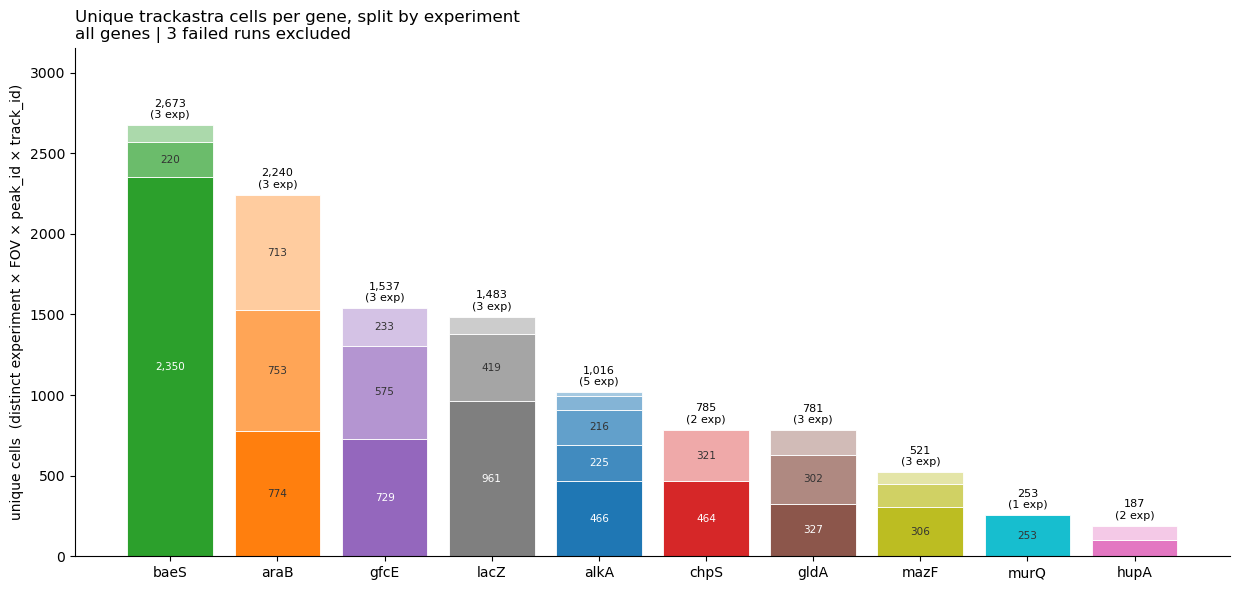

In [207]:
def fig_cells_per_gene(df, label=None, suffix=None):
    # resolved at call time, not def time, so re-running just the CONFIG cell is enough
    label = LABEL if label is None else label
    suffix = SUFFIX if suffix is None else suffix
    cells   = df[CELL_KEY + ['gene']].drop_duplicates()
    per_exp = cells.groupby(['gene', 'experiment_name']).size()
    # descending: with genes on x, largest reads left-to-right
    totals  = per_exp.groupby('gene').sum().sort_values(ascending=False)
    genes   = list(totals.index)

    fig, ax = plt.subplots(figsize=(0.95 * len(genes) + 3, 6))
    for x, gene in enumerate(genes):
        segs   = per_exp[gene].sort_values(ascending=False)
        colors = _shades(gene_color(gene), len(segs))
        bottom = 0                      # the stacking offset; `left=` when horizontal
        for (exp, n), c in zip(segs.items(), colors):
            ax.bar(x, n, bottom=bottom, color=c, edgecolor='white', linewidth=0.6)
            if n > 0.06 * totals.max():
                ax.text(x, bottom + n / 2, f'{n:,}', ha='center', va='center',
                        fontsize=7.5, color=_label_color(c))
            bottom += n
        ax.text(x, bottom + 0.012 * totals.max(),
                f'{totals[gene]:,}\n({len(segs)} exp)',
                ha='center', va='bottom', fontsize=8)

    ax.set_xticks(range(len(genes)), genes)
    ax.set_ylim(0, totals.max() * 1.18)
    ax.set_ylabel('unique cells  (distinct experiment × FOV × peak_id × track_id)')
    ax.set_title(f'Unique trackastra cells per gene, split by experiment\n{label}', loc='left')
    _style(ax)
    fig.tight_layout()
    _save(fig, f'cells_per_gene{suffix}')
    return fig


fig_cells_per_gene(df);

---
# 3 — Filtering: Δy displacement QC

Regenerated from `data/all_data_082026.csv` by stage 7:

```bash
python 07_track_displacement_analysis.py --gene all \
    --pairs-csv data/track_pairs_082026.csv --fluor-method none \
    --out-dir notebooks/figures/summary_082026
```

Two pair populations are built, tagged by `pair_type` / `is_division`:

- **within_track** (70,444) — consecutive frames of one `track_id`, flagged at 1.0 × the mean
  `axis_major_length` of the two endpoints.
- **division** (10,558) — the parent's last frame against each daughter's first. Flagged at
  **1.5 × the parent's own length**: a real division displaces the centroid further than one
  frame of growth, since each daughter starts about a quarter of a parent length off the
  parent's centroid on top of the usual advection. These were previously not examined at all,
  so a mis-called division — or a fluorescence burst landing exactly on a division frame — was
  invisible.

This notebook pools the two, so the ±1.0 cutoff line drawn in the figures below is the
within_track threshold; the division rows are judged against 1.5 instead. The per-row value
actually applied is in `dy_threshold_cell_lengths`.

### The criterion: one cell length

A pair is flagged when
$$|\Delta y| > 1.0 \times \text{cell length}$$
where cell length is the mean `axis_major_length` of the two endpoints for a within_track pair
and the parent's own length for a division pair (median 36.6 px within_track, 53.8 px
division). The reasoning is physical: a tracking error means the track landed on a
**different** cell, and in a trench of stacked cells that takes roughly one cell length of
apparent motion. The data agrees — `|Δy| / cell_length` falls monotonically to a floor at ~1.0
and then flattens into a long tail out to 43×, so the threshold sits in the valley between
advection and hops. **1,456 of 81,002 pooled pairs (1.80%)** are flagged: 1,307 of 70,444
within_track (1.86%) and 149 of 10,558 division (1.41%).

`delta_fluor` differences `intensity_mean_fluor` straight from the CSV (`--fluor-method none`,
no image I/O). The load cell below then divides `fluor_from` / `fluor_to` / `delta_fluor` by
each experiment's exposure, so Δfluor is in **a.u./ms per frame** from here on. Δy and the
cell-length ratio are spatial and are left alone.

The cell-length rule is the only criterion stage 7 applies. It replaced a robust
median ± k·MAD window on Δy in pixels, which was not comparable across experiments: Δy is
advective, so its spread tracked the acquisition interval rather than the tracking error
rate.

In [208]:
PAIR_DTYPES = {'FOV': str, 'trench_id': str, 'experiment_name': str, 'gene': str}

pairs_all = pd.read_csv(PAIRS_CSV, dtype=PAIR_DTYPES)
pairs_all['FOV'] = pairs_all['FOV'].str.zfill(3)

# The same two steps the cell table got: drop the failed runs, then put fluorescence in a.u./ms.
pairs_all = pairs_all[~pairs_all['experiment_name'].isin(list(FAILED_EXPERIMENTS))].copy()

# The pair CSV carries no exposure column, so the per-experiment value is mapped over from the
# cell table (asserted single-valued per experiment there). ONLY the fluorescence columns are
# rescaled: delta_y, cell_length, delta_y_cell_lengths and is_jump are spatial and must not be
# touched -- the cell-length criterion is already dimensionless.
EXPOSURE_BY_EXP = all_data.groupby('experiment_name')[EXPOSURE_COL].first()
_unknown = set(pairs_all['experiment_name']) - set(EXPOSURE_BY_EXP.index)
assert not _unknown, f'pair table holds experiments absent from the cell table: {sorted(_unknown)}'
_expo = pairs_all['experiment_name'].map(EXPOSURE_BY_EXP)
for _c in ('fluor_from', 'fluor_to', 'delta_fluor'):
    pairs_all[_c] = pairs_all[_c] / _expo

# The threshold is per-row, so the bound is a constant in cell-length units rather than
# something to recover from the data.
DY_LENGTH_K = 1.0
DY_BOUNDS = (-DY_LENGTH_K, DY_LENGTH_K)

print(f'{len(pairs_all):,} pairs | {pairs_all.is_jump.sum():,} flagged '
      f'({100 * pairs_all.is_jump.mean():.2f}%) | fluorescence rescaled to a.u./ms\n')
print(pairs_all.groupby('pair_type')
      .agg(n_pairs=('is_jump', 'size'), flagged=('is_jump', 'sum'),
           flag_pct=('is_jump', lambda s: round(100 * s.mean(), 2)),
           median_cell_len=('cell_length', lambda s: round(s.median(), 1))).to_string())

81,002 pairs | 1,456 flagged (1.80%) | fluorescence rescaled to a.u./ms

              n_pairs  flagged  flag_pct  median_cell_len
pair_type                                                
division        10558      149      1.41             53.8
within_track    70444     1307      1.86             36.6


### Scope the pairs to the CONFIG selection

In [209]:
def scope_pairs(pairs, gene=None, experiments=None, fovs=None):
    # Same filters as scope(). MIN_TRACK_FRAMES is not applied: a pair already implies a
    # track of at least two frames.
    out = pairs
    if gene is not None:
        out = out[out['gene'].isin([gene] if isinstance(gene, str) else list(gene))]
    if experiments is not None:
        exps = [experiments] if isinstance(experiments, str) else list(experiments)
        out = out[out['experiment_name'].isin(exps)]
    if fovs is not None:
        f = [fovs] if isinstance(fovs, str) else list(fovs)
        out = out[out['FOV'].isin([str(x).zfill(3) for x in f])]
    return out.copy()


pairs = scope_pairs(pairs_all, GENE, EXPERIMENTS, FOVS)
good  = pairs[~pairs['is_jump']]
print(f'scoped [{LABEL}]: {len(pairs):,} pairs | {pairs.is_jump.sum():,} jumps '
      f'({100*pairs.is_jump.mean():.2f}%) | {len(good):,} good')

scoped [all genes | 3 failed runs excluded]: 81,002 pairs | 1,456 jumps (1.80%) | 79,546 good


### Per-experiment diagnostic

Cell length and flag rate broken out per experiment. `median_cell_len` is the scale the
cutoff is measured against, `median_abs_dy_cl` the typical displacement in those units, and
`flag_pct` the rate under the cell-length criterion actually in use. A residual spread in
`flag_pct` across experiments remains, but it is no longer set by the acquisition interval.

In [210]:
def dy_by_experiment(pairs):
    rows = []
    for (mins, gene, exp), s in pairs.groupby(
            ['minutes_per_frame', 'gene', 'experiment_name'], sort=False):
        rows.append({
            'min_per_frame': mins, 'gene': gene, 'experiment_name': exp,
            'n_pairs': len(s),
            'median_cell_len': round(s['cell_length'].median(), 1),
            'median_abs_dy_cl': round(s['delta_y_cell_lengths'].abs().median(), 3),
            'flag_pct': round(100 * s['is_jump'].mean(), 2),
        })
    return pd.DataFrame(rows).sort_values('flag_pct').reset_index(drop=True)


dy_diag = dy_by_experiment(pairs)
print(f'Per-experiment Δy  [{LABEL}]   applied cutoff: |Δy| > {DY_LENGTH_K}× cell length\n')
print(dy_diag.to_string(index=False))
print()
print('by acquisition interval:')
print(dy_diag.groupby('min_per_frame')
      .agg(n_experiments=('experiment_name', 'size'),
           median_cell_len=('median_cell_len', 'median'),
           median_flag_pct=('flag_pct', 'median')).to_string())

Per-experiment Δy  [all genes | 3 failed runs excluded]   applied cutoff: |Δy| > 1.0× cell length

 min_per_frame gene                   experiment_name  n_pairs  median_cell_len  median_abs_dy_cl  flag_pct
             5 hupA               DUMM_giTG068_052925     1045             47.5             0.101      0.48
             5 alkA DUMM_giTG63_giTG67_Glucose_121724     2069             34.6             0.192      0.72
            10 alkA           DUMM_giTG069_063_121225      133             44.8             0.144      0.75
             5 gldA        DUMM_giTG69_Glucose_013025     2943             39.8             0.161      0.85
             5 lacZ DUMM_giTG059_noKan_Glucose_031125     3918             39.5             0.169      0.87
             5 chpS        DUMM_giTG62_Glucose_012925     4722             38.5             0.115      1.10
            10 mazF           DUMM_giTG059_060_061125      338             41.0             0.233      1.18
            10 gfcE           DUMM_gi

### Figures

Four histograms: Δy and Δfluor, each on a log and a linear y-axis. Both come from one local
function apiece rather than from `mmtrack.track_displacement.plot_dy_histogram` /
`plot_dfluor_histogram`, which hardcode `set_yscale('log')` and whose Δfluor x-label names
`intensity_mean_fluor` — the wrong unit now that the pair table is in a.u./ms. Colours, the value
column and the default x-range are still imported from that module, so the house style is shared.

On a linear axis the near-zero bin dominates: the Δy plot still reads fine (the cutoff sits
inside the visible bulk) while the Δfluor plot becomes one tall bin near zero with a short tail.
That is what the counts actually are — the log axis is what was hiding it.

In [211]:
# Local copies of plot_dy_histogram / plot_dfluor_histogram
# (mmtrack/track_displacement.py:491-541), parameterised by y-scale and x-label. The module
# versions hardcode ax.set_yscale('log') and name `intensity_mean_fluor` in the Delta-fluor
# label, which is the wrong unit now that the pair table is in a.u./ms. Colours and the value
# column are still imported from that module, so the house style stays shared -- but being
# copies, these do NOT track later edits to it.
from mmtrack.track_displacement import (
    C_GOOD, C_JUMP, DY_VALUE_COL, DY_XLABEL, DY_DEFAULT_RANGE,
)

# plot_* name their files f'{label}_delta_y_hist' etc. MIN_TRACK_FRAMES is excluded from the
# label because it does not apply to pairs.
DY_LABEL = 'dy' + scope_suffix(GENE, EXPERIMENTS, FOVS)


def _apply_yscale(ax, yscale, base):
    """Set the y-scale, label it, and return the filename suffix that keeps the log and
    linear variants from overwriting each other's SVG/PNG pair in FIG_DIR."""
    ax.set_yscale(yscale)
    ax.set_ylabel(f'{base} (log)' if yscale == 'log' else base)
    return '' if yscale == 'log' else '_linear'


def plot_dy_histogram(pairs, bounds, label, bins=60, xrange='default', yscale='log',
                      save=SAVE_FIGS):
    """Delta-y / cell length histogram. `yscale` picks the log or the linear variant."""
    lower, upper = bounds
    if xrange == 'default':
        xrange = DY_DEFAULT_RANGE
    n_jump, n_total = int(pairs['is_jump'].sum()), len(pairs)

    values = pairs[DY_VALUE_COL].dropna()
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.hist(values, bins=bins, range=xrange, color=C_MAIN, alpha=0.85)
    ax.axvline(lower, color=C_JUMP, ls='--', lw=1.5,
               label=f'cutoff [{lower:.1f}, {upper:.1f}]')
    ax.axvline(upper, color=C_JUMP, ls='--', lw=1.5)
    if xrange is not None:
        n_off = int(((values < xrange[0]) | (values > xrange[1])).sum())
        if n_off:
            # Say so rather than letting a clipped axis imply the tail does not exist.
            ax.plot([], [], ' ', label=f'{n_off} pair(s) beyond ±{xrange[1]:g}, off-axis')
    ax.set_xlabel(DY_XLABEL)
    suffix = _apply_yscale(ax, yscale, 'pair count')
    ax.set_title(f'{label}: frame-to-frame displacement\n'
                 f'{n_jump:,}/{n_total:,} pairs flagged as jumps '
                 f'({100 * n_jump / max(n_total, 1):.1f}%)')
    ax.legend(frameon=False)
    _style(ax)
    fig.tight_layout()
    if save:
        print(_save(fig, f'{label}_delta_y_hist{suffix}'))
    return fig


def plot_dfluor_histogram(all_pairs, good_pairs, label, bins=60, yscale='log',
                          xlabel=None, save=SAVE_FIGS):
    """Delta-fluor increase histogram. Positive changes only, as in the module version."""
    all_pos = all_pairs.loc[all_pairs['delta_fluor'] > 0, 'delta_fluor'].dropna()
    good_pos = good_pairs.loc[good_pairs['delta_fluor'] > 0, 'delta_fluor'].dropna()

    fig, ax = plt.subplots(figsize=(8, 5))
    hi = np.nanpercentile(all_pos, 99.5) if len(all_pos) else 1.0
    rng = (0, hi)
    ax.hist(all_pos, bins=bins, range=rng, color=C_ALL, alpha=0.6,
            label=f'all pairs (n={len(all_pos):,})')
    ax.hist(good_pos, bins=bins, range=rng, color=C_GOOD, alpha=0.7,
            label=f'good pairs (n={len(good_pos):,})')
    ax.set_xlabel(DFLUOR_LABEL if xlabel is None else xlabel)
    suffix = _apply_yscale(ax, yscale, 'pair count')
    ax.set_title(f'{label}: frame-to-frame fluorescence change')
    ax.legend(frameon=False)
    _style(ax)
    fig.tight_layout()
    if save:
        print(_save(fig, f'{label}_delta_fluor_hist{suffix}'))
    return fig

/Users/adrianjuarez/Documents/Covert_lab/repos/mother_machine_cell_tracker/notebooks/figures/summary_082026/dy_delta_y_hist.svg
/Users/adrianjuarez/Documents/Covert_lab/repos/mother_machine_cell_tracker/notebooks/figures/summary_082026/dy_delta_fluor_hist.svg
/Users/adrianjuarez/Documents/Covert_lab/repos/mother_machine_cell_tracker/notebooks/figures/summary_082026/dy_delta_y_hist_linear.svg
/Users/adrianjuarez/Documents/Covert_lab/repos/mother_machine_cell_tracker/notebooks/figures/summary_082026/dy_delta_fluor_hist_linear.svg


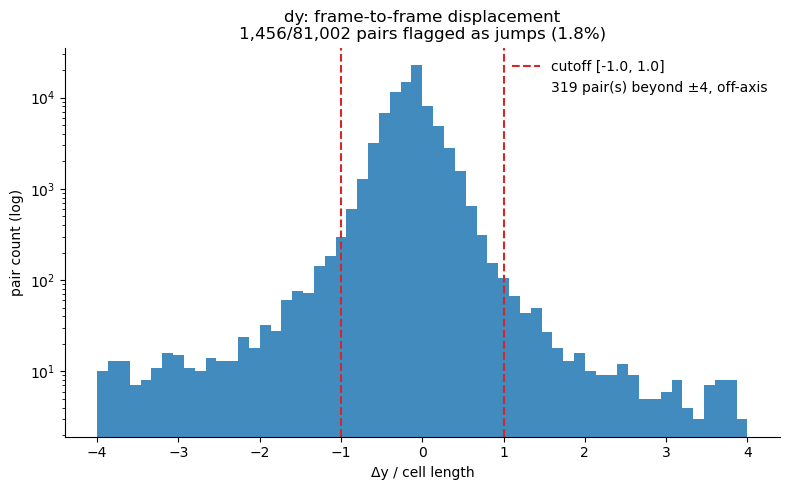

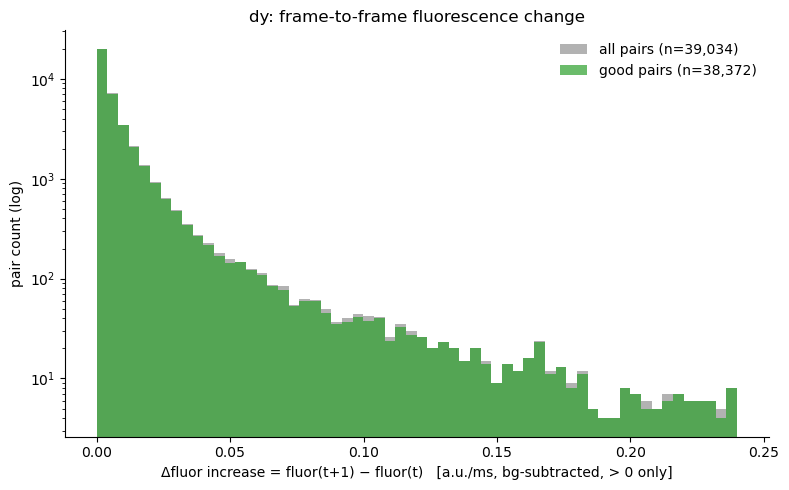

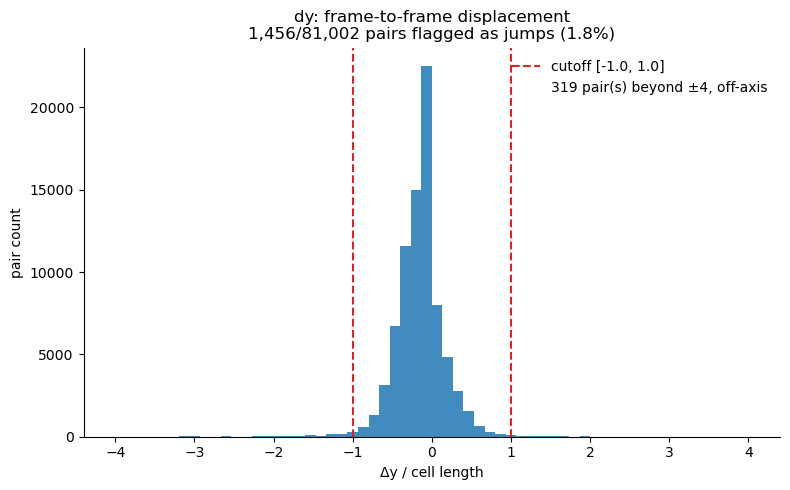

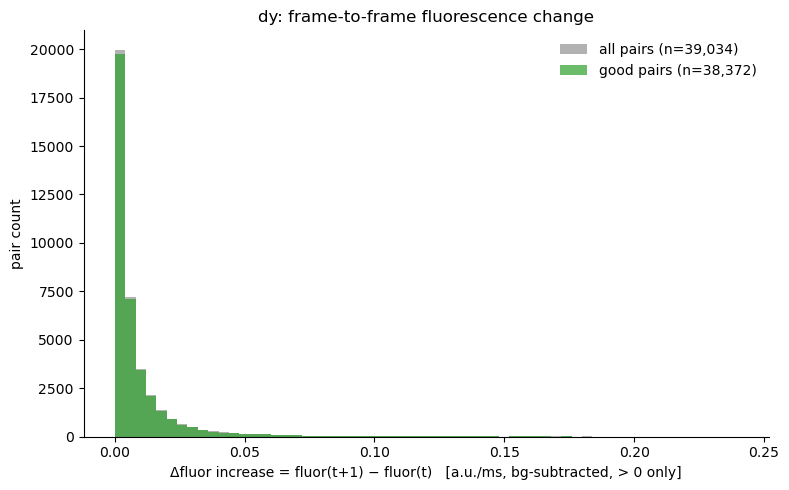

In [212]:
# Log first, then linear -- same data, same bins, same +/-1.0 cell-length cutoff.
for _ys in ('log', 'linear'):
    plot_dy_histogram(pairs, DY_BOUNDS, DY_LABEL, yscale=_ys)
    plot_dfluor_histogram(pairs, good, DY_LABEL, yscale=_ys)

### Merging the pairs back onto the cell table

`time_frame` (= `frame_from`) attributes each pair to the frame it starts from, so the table
left-merges 1:1 onto `all_data`. Every row keeps its full identity — `experiment_name`, `FOV`,
`trench_id`, `track_id` — so any pair traces back to one cell in one kymograph.

Each track's **last** frame has no successor and so no pair, which is exactly the 11,476-row
shortfall below: one per track.

Division pairs sit out this merge by design: their `time_frame` is NaN, because `frame_from`
belongs to the **parent** while `track_id` is the **daughter's**, so the key would attribute the
pair to a cell-frame that does not exist. NaN matches nothing, so the 1:1 assert still holds and
the Δ columns land exactly as they would from a within_track-only merge.

In [213]:
MERGE_KEY  = ['experiment_name', 'FOV', 'trench_id', 'track_id', 'time_frame']
DELTA_COLS = ['delta_y', 'cell_length', 'delta_y_cell_lengths', 'delta_fluor',
              'is_jump']

merged = all_data.merge(pairs_all[MERGE_KEY + DELTA_COLS], on=MERGE_KEY, how='left')

assert len(merged) == len(all_data), 'merge changed the row count -- duplicate join keys'
n_with = int(merged['delta_y'].notna().sum())
print(f'{len(merged):,} rows  |  {n_with:,} carry a Δ  |  '
      f'{len(merged) - n_with:,} without, = one per track (the final frame)')
print(f'tracks in all_data: {len(all_data[CELL_KEY].drop_duplicates()):,}')
print()
print(merged.loc[merged.is_jump == True,
                 CELL_KEY + ['time_frame', 'delta_y', 'cell_length',
                             'delta_y_cell_lengths']]
      .head(5).to_string(index=False))

81,920 rows  |  70,444 carry a Δ  |  11,476 without, = one per track (the final frame)
tracks in all_data: 11,476

     experiment_name FOV trench_id  track_id  time_frame     delta_y  cell_length  delta_y_cell_lengths
CL008_giTG068_072925 003       312         1           0   53.470401    40.230865              1.329089
CL008_giTG068_072925 003       312         2           1 -142.271627    47.335885             -3.005577
CL008_giTG068_072925 003       312         2           2  -59.991795    36.390708             -1.648547
CL008_giTG068_072925 003       312         4           2  -68.471192    26.751012             -2.559574
CL008_giTG068_072925 003       312         6           5   24.525746    23.925426              1.025091


---
# 4 — Doubling time

**Definition.** A cell's doubling time is the span over which it was observed before it
divided:

$$T_d = (\text{last observed frame} - \text{first observed frame}) \times \text{minutes\_per\_frame}$$

taken over the **parent** track of every division event. Tracks are contiguous in this
dataset (`n_frames == last - first + 1` for all of them), so first/last is the whole story
and there is no gap to account for.

**The denominator is divisions, not lineages.** Every division event contributes exactly one
observation to the mean; there is no per-track or per-lineage pre-averaging, which would
otherwise let a trench with one long lineage outweigh a trench with twenty short ones.

**One division event == one parent track.** Checked both ways — from `all_data`
(`parent_track_id`) and from `pairs_all[is_division]` — and the two agree exactly: 5,279
events, every one with exactly two daughters, and no parent that divides twice. The pair
table carries one row per *daughter*, so the two rows per event are deduplicated to
`(experiment_name, FOV, trench_id, parent_track_id)` before averaging. A division with two
daughters is one doubling time, not two.

**Left truncation is reported, not filtered.** 11.4% of dividing parents were already present
at their first observed frame with no parent of their own — either the movie started
mid-cycle or the track begins at a tracking break. Their lifetime is cut short, so their
doubling time is an underestimate. Rather than pick one, every table carries both: the
all-divisions columns and the `*_birth_obs` columns restricted to events whose parent's own
birth was seen. The gap between them is the size of the bias (pooled: 65.9 vs 67.9 min).

**Two things to read as data quality, not biology.**

- `n_zero_dt` — divisions whose parent was observed in a single frame, giving $T_d = 0$.
  186 pooled (3.5%). Almost certainly a segmentation or tracking artefact rather than a cell
  that divided instantly. They are kept and counted rather than silently dropped, so the
  column is the readout; a `mean_dt_min` sitting next to a large `pct_zero_dt` is soft.
- `minutes_per_frame` **quantizes** the answer. 13 experiments run at 10 min and 7 at 5 min,
  so a 10-min experiment can only ever report multiples of 10. That is why the medians land
  on round numbers and why the per-gene dots below are coloured by acquisition interval.

`MIN_TRACK_FRAMES` is deliberately not applied here, for the same reason `scope_pairs`
skips it: a division event already implies its parent was tracked, so the filter would be
re-litigating a threshold the pair construction has already passed. `GENE`, `EXPERIMENTS`
and `FOVS` do apply, through the already-scoped `pairs`.

In [214]:
# MIN_TRACK_FRAMES is excluded from the suffix: it does not apply to division events.
DT_SUFFIX = scope_suffix(GENE, EXPERIMENTS, FOVS)
DT_LABEL  = scope_label(GENE, EXPERIMENTS, FOVS)


def track_lifetimes(cells=None):
    """First and last observed frame per unique cell. One row per CELL_KEY.

    `parent_track_id` is constant within a track, so 'first' is just a way to carry it
    through the groupby.
    """
    cells = all_data if cells is None else cells
    return (cells.groupby(CELL_KEY, observed=True)
                 .agg(first_frame=('time_frame', 'min'),
                      last_frame=('time_frame', 'max'),
                      n_frames=('time_frame', 'nunique'),
                      minutes_per_frame=('minutes_per_frame', 'first'),
                      parent_track_id=('parent_track_id', 'first'))
                 .reset_index())


def division_events(pairs, cells=None):
    """One row per observed division, keyed by the *parent* cell.

    The pair table holds one division row per daughter, so this collapses them to one row
    per event and re-keys `parent_track_id` -> `track_id` so the result joins to
    `track_lifetimes` on CELL_KEY: the doubling time belongs to the cell that divided.

    Adds:
        doubling_min    (last_frame - first_frame) * minutes_per_frame
        birth_observed  the parent has a parent of its own, so its birth was seen
        has_jump        the parent track has at least one within_track pair flagged
                        is_jump -- i.e. its Delta-y hopped by more than one cell length
                        somewhere in its lifetime

    Args:
        pairs: pair-level DataFrame, already scoped (e.g. `pairs` from the Delta-y section).
        cells: per-cell-per-frame table for the lifetimes. Defaults to the UNSCOPED
            `all_data` on purpose -- the scope is carried by `pairs`, and passing a
            min_frames-filtered frame here would drop parent rows and trip the assert.
    """
    div = pairs[pairs['is_division'].astype(bool)]
    if div.empty:
        raise ValueError('no division pairs in this scope; nothing to average')

    # The lifetime definition below has no meaning if a track divides twice.
    per_parent = div.groupby(KYMO_KEY + ['parent_track_id'], observed=True)['frame_from'].nunique()
    assert (per_parent == 1).all(), 'a parent track divides at more than one frame'

    ev = (div.drop_duplicates(subset=KYMO_KEY + ['parent_track_id'])
             .loc[:, KYMO_KEY + ['gene', 'parent_track_id', 'frame_from', 'n_siblings']]
             .rename(columns={'parent_track_id': 'track_id',
                              'frame_from': 'division_frame',
                              'n_siblings': 'n_daughters'}))
    ev['track_id'] = ev['track_id'].astype(int)

    n_before = len(ev)
    ev = ev.merge(track_lifetimes(cells), on=CELL_KEY, how='inner')
    assert len(ev) == n_before, (
        f'{n_before - len(ev)} division events lost their parent rows in the cell table; '
        f'pass the unscoped all_data as `cells`')
    assert (ev['division_frame'] == ev['last_frame']).all(), (
        'a parent divides before its last observed frame -- the pair table and the cell '
        'table disagree about where the track ends')

    ev['doubling_min']   = (ev['last_frame'] - ev['first_frame']) * ev['minutes_per_frame']
    ev['birth_observed'] = ev['parent_track_id'].notna()

    # Jump granularity: the DIVIDING cell's own consecutive-frame pairs. A flagged
    # division pair (the birth of a daughter) does not disqualify the parent's lifetime.
    wt = pairs[~pairs['is_division'].astype(bool)]
    flagged = set(wt.loc[wt['is_jump'].astype(bool), CELL_KEY]
                    .drop_duplicates().itertuples(index=False, name=None))
    ev['has_jump'] = [k in flagged for k in ev[CELL_KEY].itertuples(index=False, name=None)]
    return ev


def doubling_by(events, keys):
    """Doubling-time stats grouped by `keys`. n is DIVISIONS, one row per event."""
    g  = events.groupby(keys, observed=True)['doubling_min']
    bo = events[events['birth_observed']].groupby(keys, observed=True)['doubling_min']
    out = pd.DataFrame({
        'n_div':               g.size(),
        'mean_dt_min':         g.mean(),
        'median_dt_min':       g.median(),
        'sd_dt_min':           g.std(),
        'sem_dt_min':          g.sem(),
        'n_div_birth_obs':     bo.size(),
        'mean_dt_birth_obs':   bo.mean(),
        'median_dt_birth_obs': bo.median(),
        'n_zero_dt':           events[events['doubling_min'] == 0]
                                   .groupby(keys, observed=True).size(),
    })
    for c in ('n_div_birth_obs', 'n_zero_dt'):
        out[c] = out[c].fillna(0).astype(int)
    out['pct_zero_dt'] = (100 * out['n_zero_dt'] / out['n_div']).round(1)
    return out


def _dt_total(events, label='TOTAL'):
    """The TOTAL row, recomputed over the whole frame rather than summed -- 10 of the 23
    experiments hold two genes in different FOVs, so summing a per-gene table would
    double-count them."""
    total = doubling_by(events.assign(_all=label), ['_all'])
    total.index = [label]
    return total


events = division_events(pairs)
print(f'divisions [{DT_LABEL}]: {len(events):,} events | '
      f'{events.has_jump.sum():,} with a Delta-y jump in the dividing cell '
      f'({100 * events.has_jump.mean():.2f}%) | {(~events.has_jump).sum():,} clean')
print(f'  birth observed: {events.birth_observed.sum():,} '
      f'({100 * events.birth_observed.mean():.1f}%) | '
      f'zero-length parents: {(events.doubling_min == 0).sum():,} '
      f'({100 * (events.doubling_min == 0).mean():.1f}%)')
print(f'  pooled mean {events.doubling_min.mean():.2f} min | '
      f'median {events.doubling_min.median():.1f} min')

divisions [all genes | 3 failed runs excluded]: 5,279 events | 389 with a Delta-y jump in the dividing cell (7.37%) | 4,890 clean
  birth observed: 4,676 (88.6%) | zero-length parents: 186 (3.5%)
  pooled mean 65.87 min | median 60.0 min


In [215]:
def doubling_by_experiment(events):
    """Table: one row per experiment, plus a recomputed TOTAL."""
    keys = ['experiment_name']
    out = doubling_by(events, keys)
    # '+'-joined because 10 of 23 experiments hold two genes in different FOVs.
    out.insert(0, 'gene', events.groupby(keys, observed=True)['gene']
                                .apply(lambda s: '+'.join(sorted(s.dropna().unique()))))
    out.insert(1, 'min_per_frame',
               events.groupby(keys, observed=True)['minutes_per_frame'].first())
    out = out.sort_values('mean_dt_min', ascending=False)

    total = _dt_total(events)
    total['gene'] = f"{events['gene'].nunique()} genes"
    total['min_per_frame'] = np.nan
    return pd.concat([out, total[out.columns]])


def doubling_by_gene(events):
    """Table: one row per gene, plus a recomputed TOTAL. Also returns the per-experiment
    means the `mean_of_exp_means` column and the figure's dots are built from."""
    out = doubling_by(events, ['gene'])
    per_exp = (events.groupby(['gene', 'experiment_name'], observed=True)
                     .agg(mean=('doubling_min', 'mean'),
                          n_div=('doubling_min', 'size'),
                          min_per_frame=('minutes_per_frame', 'first'))
                     .reset_index())

    out['n_experiments']     = per_exp.groupby('gene').size()
    out['mean_of_exp_means'] = per_exp.groupby('gene')['mean'].mean()
    out['min_exp_mean']      = per_exp.groupby('gene')['mean'].min()
    out['max_exp_mean']      = per_exp.groupby('gene')['mean'].max()

    cols = ['n_experiments', 'n_div', 'mean_dt_min', 'median_dt_min', 'sd_dt_min',
            'sem_dt_min', 'mean_of_exp_means', 'min_exp_mean', 'max_exp_mean',
            'n_div_birth_obs', 'mean_dt_birth_obs', 'median_dt_birth_obs',
            'n_zero_dt', 'pct_zero_dt']
    out = out[cols].sort_values('mean_dt_min', ascending=False)

    total = _dt_total(events)
    total['n_experiments']     = events['experiment_name'].nunique()
    total['mean_of_exp_means'] = per_exp['mean'].mean()
    total['min_exp_mean']      = per_exp['mean'].min()
    total['max_exp_mean']      = per_exp['mean'].max()
    return pd.concat([out, total[cols]]), per_exp


# Acquisition interval, not exposure: doubling time is quantized by minutes_per_frame.
# Green/purple deliberately avoid the bar colour below (blue).
INTERVAL_COLOR = {5: '#2ca02c', 10: '#9467bd'}
_ERR = dict(ecolor='0.3', lw=0.9, capsize=2)


def _interval_color(mins):
    return INTERVAL_COLOR.get(int(mins), '0.5')


def plot_doubling_by_experiment(events, title, name, save=None):
    """Mean doubling time per experiment, one bar per (experiment, gene).

    Splitting the mixed-gene experiments into adjacent sub-bars avoids having to paint a
    single bar with two gene colours -- and it is the honest reading, since the two genes
    sit in different FOVs of the same acquisition. Error bars are SEM over divisions.
    """
    per = (events.groupby(['experiment_name', 'gene'], observed=True)['doubling_min']
                 .agg(mean='mean', sem='sem', n='size').reset_index())
    order = (events.groupby('experiment_name', observed=True)['doubling_min']
                   .mean().sort_values(ascending=False).index)
    pooled = events['doubling_min'].mean()
    top = float(np.nanmax(per['mean'] + per['sem'].fillna(0)))

    fig, ax = plt.subplots(figsize=(0.66 * len(order) + 3.5, 5.6))
    seen = set()
    for x, exp in enumerate(order):
        sub = per[per['experiment_name'] == exp].sort_values('gene')
        w = 0.78 / len(sub)
        for j, (_, r) in enumerate(sub.iterrows()):
            xi = x - 0.39 + w * (j + 0.5)
            c = gene_color(r['gene'])
            ax.bar(xi, r['mean'], width=w * 0.9, color=c,
                   yerr=(r['sem'] if np.isfinite(r['sem']) else None), error_kw=_ERR,
                   label=r['gene'] if r['gene'] not in seen else None)
            seen.add(r['gene'])
            ax.text(xi, r['mean'] + (r['sem'] if np.isfinite(r['sem']) else 0) + 0.03 * top,
                    f"{int(r['n'])}", ha='center', va='bottom', fontsize=6.5, rotation=90)

    ax.axhline(pooled, color='0.35', ls='--', lw=0.9, zorder=0,
               label=f'pooled mean {pooled:.1f} min')
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(order, rotation=60, ha='right', fontsize=7.5)
    ax.set_xlim(-0.6, len(order) - 0.4)      # matplotlib pads bar axes; the pad reads as data
    ax.set_ylim(0, top * 1.32)
    ax.set_ylabel('mean doubling time (min)')
    ax.set_title(f'{title}\n{DT_LABEL}   (bar labels = number of divisions)', loc='left')
    ax.legend(frameon=False, fontsize=8, ncol=3, title='gene', title_fontsize=8)
    _style(ax)
    fig.tight_layout()
    print(_save(fig, name, save=SAVE_FIGS if save is None else save))
    return fig


def plot_doubling_by_gene(summary, per_exp, title, name, seed=0, save=None):
    """Per gene: grand mean over divisions (SEM error bars), with one dot per experiment
    coloured by acquisition interval.

    One bar per gene, not two: the mean of the per-experiment means was dropped, and the
    dots carry the replicate spread it stood in for. The y-axis is LINEAR -- the range here
    is roughly 48-86 min, not the ~150x span the fluorescence figures had to compress.
    """
    genes = [g for g in summary.index if g != 'TOTAL']
    s = summary.loc[genes]
    x = np.arange(len(genes))

    fig, ax = plt.subplots(figsize=(1.05 * len(genes) + 4, 5.6))
    ax.bar(x, s['mean_dt_min'], width=0.55, color=C_MAIN, alpha=0.85,
           yerr=s['sem_dt_min'], error_kw=_ERR, label='grand mean (per division)')

    rng = np.random.default_rng(seed)   # deterministic jitter -> reproducible figure
    seen = set()
    for xi, gene in enumerate(genes):
        sub = per_exp[per_exp['gene'] == gene]
        for (_, r), dx in zip(sub.iterrows(), rng.uniform(-0.20, 0.20, len(sub))):
            mins = int(r['min_per_frame'])
            ax.scatter(xi + dx, r['mean'], s=26, zorder=3,
                       color=_interval_color(mins), edgecolor='0.25', linewidth=0.5,
                       label=f'{mins} min/frame' if mins not in seen else None)
            seen.add(mins)

    top = float(np.nanmax([(s['mean_dt_min'] + s['sem_dt_min'].fillna(0)).max(),
                           per_exp['mean'].max()]))
    ax.set_xticks(x, genes)
    ax.set_xlim(-0.6, len(genes) - 0.4)
    ax.set_ylim(0, top * 1.18)
    ax.set_ylabel('doubling time (min)')
    ax.set_title(f'{title}\n{DT_LABEL}', loc='left')
    ax.legend(frameon=False, fontsize=8, ncol=2, title='bar / interval',
              title_fontsize=8)
    _style(ax)
    fig.tight_layout()
    print(_save(fig, name, save=SAVE_FIGS if save is None else save))
    return fig

### Table D + Figure 2 — average doubling time per experiment

Average doubling time per experiment  [all genes | 3 failed runs excluded]

                                        gene  min_per_frame  n_div  mean_dt_min  median_dt_min  sd_dt_min  sem_dt_min  n_div_birth_obs  mean_dt_birth_obs  median_dt_birth_obs  n_zero_dt  pct_zero_dt
DUMM_giTG059_068_SC_093025              lacZ           10.0    453        85.43           80.0      54.24        2.55              417              87.91                 80.0         12          2.6
DUMM_mazF_murQ_121625              mazF+murQ           10.0    249        73.41           70.0      40.29        2.55              205              77.02                 70.0          7          2.8
DUMM_gitg068_baeS_100225                baeS           10.0   1118        72.84           70.0      40.25        1.20             1036              74.72                 70.0         27          2.4
CL008_giTG068_072925                    araB           10.0    363        69.20           60.0      44.29        2.32           

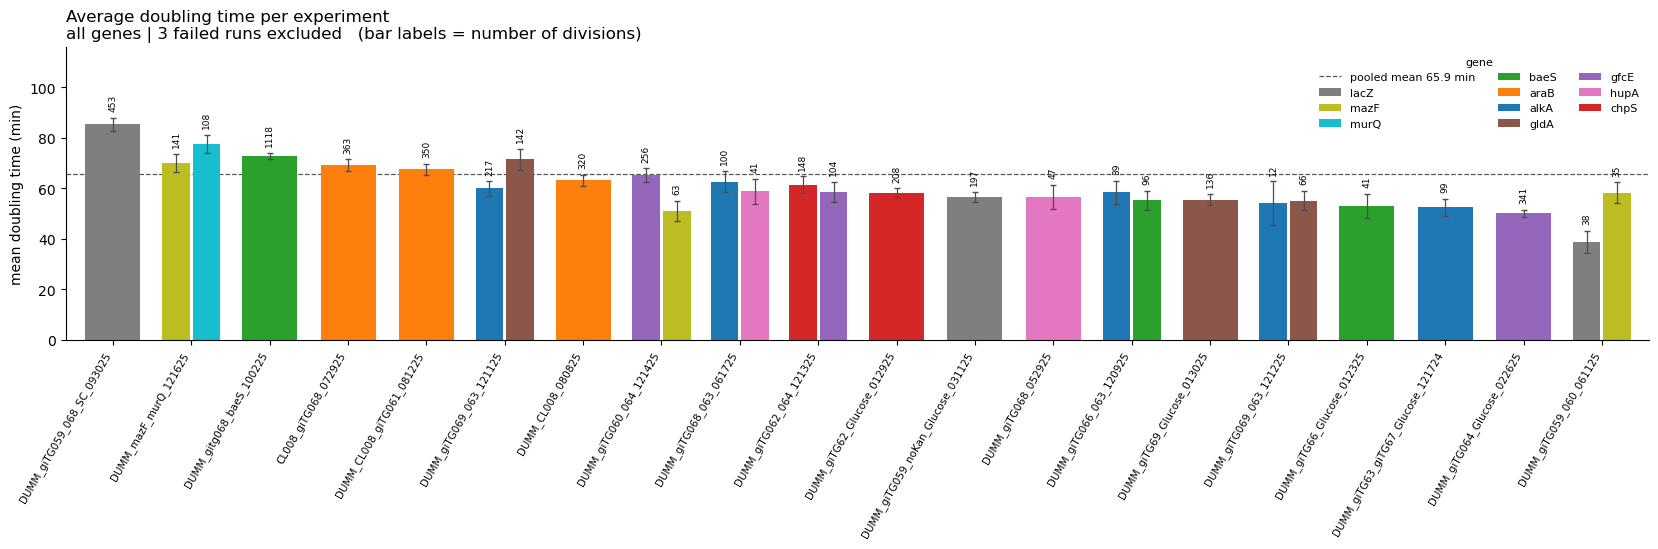

In [216]:
dt_by_exp = doubling_by_experiment(events)
print(f'Average doubling time per experiment  [{DT_LABEL}]\n')
print(dt_by_exp.round(2).to_string())

plot_doubling_by_experiment(events,
                            title='Average doubling time per experiment',
                            name=f'doubling_per_experiment{DT_SUFFIX}');

### Table E + Figure 3 — average doubling time per gene

Average doubling time per gene  [all genes | 3 failed runs excluded]

       n_experiments  n_div  mean_dt_min  median_dt_min  sd_dt_min  sem_dt_min  mean_of_exp_means  min_exp_mean  max_exp_mean  n_div_birth_obs  mean_dt_birth_obs  median_dt_birth_obs  n_zero_dt  pct_zero_dt
murQ               1    108        77.59           70.0      36.81        3.54              77.59         77.59         77.59               83              82.53                 80.0          2          1.9
lacZ               3    688        74.62           70.0      49.30        1.88              60.34         38.95         85.43              618              77.40                 70.0         19          2.8
baeS               3   1255        70.85           60.0      40.21        1.14              60.41         53.17         72.84             1150              72.99                 70.0         33          2.6
araB               3   1033        66.77           60.0      42.90        1.33              66.64     

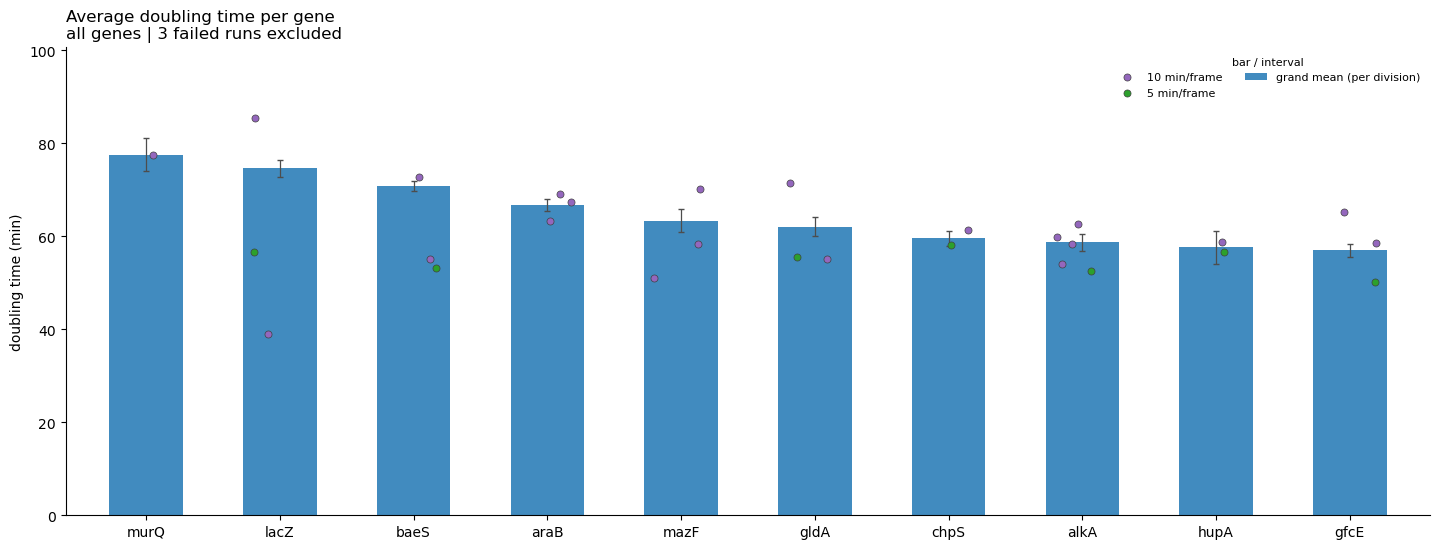

In [217]:
dt_by_gene, dt_per_exp = doubling_by_gene(events)
print(f'Average doubling time per gene  [{DT_LABEL}]\n')
print(dt_by_gene.round(2).to_string())

plot_doubling_by_gene(dt_by_gene, dt_per_exp,
                      title='Average doubling time per gene',
                      name=f'doubling_per_gene{DT_SUFFIX}');

---
## Figures 4–5 — the same two, restricted to cells with no Δy jump

Same tables and figures, over the subset of divisions whose **dividing cell** carries no
flagged Δy pair — no `within_track` pair anywhere in the parent's lifetime with
$|\Delta y| > 1.0 \times$ cell length. That is the tracking-error criterion from the Δy
section above, applied at the level of the cell whose lifetime is being measured. A cell that
hopped to a neighbour mid-lifetime has a lifetime that is not one cell's, so its doubling
time is meaningless regardless of whether the division itself looks clean.

**Scope of the filter.** Deliberately the parent's *own* consecutive-frame pairs only. Not
the division pairs (a daughter's birth displacement is judged against a different, 1.5×
threshold and says nothing about how long the parent lived), and not the whole lineage tree —
tree-level rejection would drop any tree containing a single bad pair anywhere, which takes
out ~79% of divisions and would trade the bias for a much larger variance.

**It keeps 4,890 of 5,279 divisions (92.6%), and the pooled mean moves 65.87 → 65.01 min.**
The filtered numbers are the ones to quote, but the small shift is the useful result: the
gene ranking is not an artefact of tracking hops.

jump-filtered: 4,890 of 5,279 divisions (92.6%) | pooled mean 65.01 min (vs 65.87 unfiltered)

Average doubling time per experiment, no Delta-y jump  [all genes | 3 failed runs excluded]

                                        gene  min_per_frame  n_div  mean_dt_min  median_dt_min  sd_dt_min  sem_dt_min  n_div_birth_obs  mean_dt_birth_obs  median_dt_birth_obs  n_zero_dt  pct_zero_dt
DUMM_giTG059_068_SC_093025              lacZ           10.0    416        85.82           80.0      54.31        2.66              385              88.68                 80.0         12          2.9
DUMM_mazF_murQ_121625              mazF+murQ           10.0    236        72.75           70.0      39.75        2.59              193              76.48                 70.0          7          3.0
DUMM_gitg068_baeS_100225                baeS           10.0   1066        72.34           70.0      39.60        1.21              987              74.35                 70.0         27          2.5
DUMM_CL008_giTG0

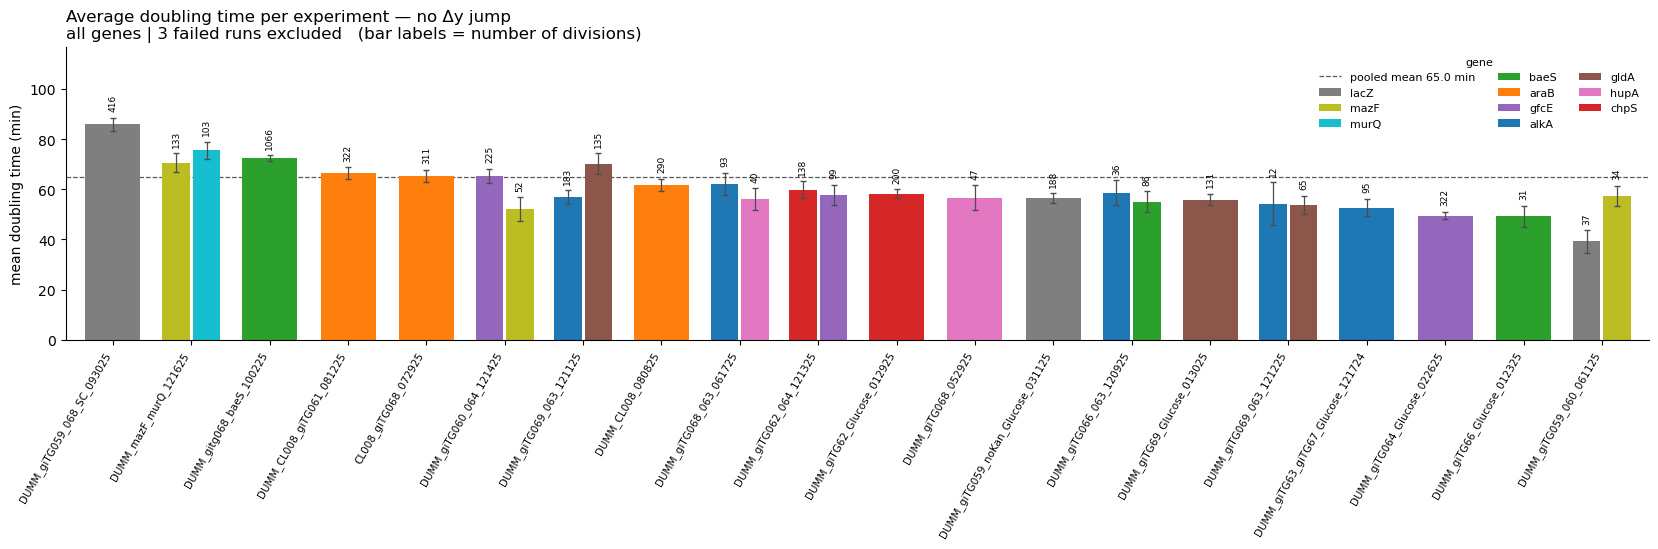

In [218]:
events_clean = events[~events['has_jump']].copy()
print(f'jump-filtered: {len(events_clean):,} of {len(events):,} divisions '
      f'({100 * len(events_clean) / len(events):.1f}%) | '
      f'pooled mean {events_clean.doubling_min.mean():.2f} min '
      f'(vs {events.doubling_min.mean():.2f} unfiltered)\n')

dt_by_exp_clean = doubling_by_experiment(events_clean)
print(f'Average doubling time per experiment, no Delta-y jump  [{DT_LABEL}]\n')
print(dt_by_exp_clean.round(2).to_string())

plot_doubling_by_experiment(events_clean,
                            title='Average doubling time per experiment — no Δy jump',
                            name=f'doubling_per_experiment_nojump{DT_SUFFIX}');

Average doubling time per gene, no Delta-y jump  [all genes | 3 failed runs excluded]

       n_experiments  n_div  mean_dt_min  median_dt_min  sd_dt_min  sem_dt_min  mean_of_exp_means  min_exp_mean  max_exp_mean  n_div_birth_obs  mean_dt_birth_obs  median_dt_birth_obs  n_zero_dt  pct_zero_dt
murQ               1    103        75.53           70.0      34.38        3.39              75.53         75.53         75.53               79              80.13                 80.0          2          1.9
lacZ               3    641        74.49           70.0      49.33        1.95              60.45         39.19         85.82              579              77.55                 70.0         19          3.0
baeS               3   1183        70.47           60.0      39.58        1.15              58.84         49.19         72.34             1084              72.74                 70.0         33          2.8
araB               3    923        64.56           60.0      41.61        1.37       

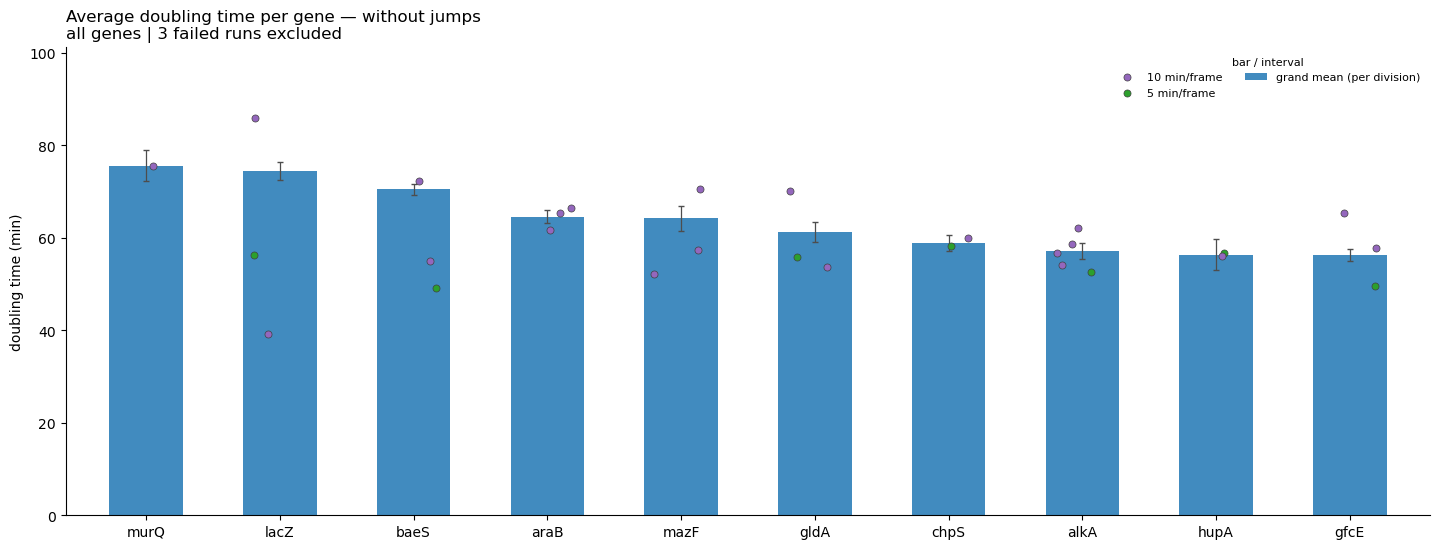

In [219]:
dt_by_gene_clean, dt_per_exp_clean = doubling_by_gene(events_clean)
print(f'Average doubling time per gene, no Delta-y jump  [{DT_LABEL}]\n')
print(dt_by_gene_clean.round(2).to_string())

# What the filter actually did, per gene, so it is one glance rather than two tables to
# diff. TOTAL is dropped first: a rank among genes is not defined for it.
by_gene_all   = dt_by_gene.drop(index='TOTAL')
by_gene_clean = dt_by_gene_clean.drop(index='TOTAL')
delta = pd.DataFrame({
    'n_div_all':    by_gene_all['n_div'],
    'n_div_nojump': by_gene_clean['n_div'],
    'mean_all':     by_gene_all['mean_dt_min'],
    'mean_nojump':  by_gene_clean['mean_dt_min'],
})
delta['pct_kept']    = (100 * delta['n_div_nojump'] / delta['n_div_all']).round(1)
delta['delta_min']   = delta['mean_nojump'] - delta['mean_all']
delta['rank_all']    = by_gene_all['mean_dt_min'].rank(ascending=False).astype(int)
delta['rank_nojump'] = by_gene_clean['mean_dt_min'].rank(ascending=False).astype(int)
delta['rank_shift']  = delta['rank_all'] - delta['rank_nojump']
print('\neffect of the jump filter (delta_min = filtered - unfiltered, '
      'rank_shift 0 = unchanged):')
print(delta.sort_values('mean_all', ascending=False).round(2).to_string())
print(f"\npooled: {dt_by_gene.loc['TOTAL','mean_dt_min']:.2f} -> "
      f"{dt_by_gene_clean.loc['TOTAL','mean_dt_min']:.2f} min  "
      f"({dt_by_gene_clean.loc['TOTAL','n_div']:,} of {dt_by_gene.loc['TOTAL','n_div']:,} "
      f"divisions kept)")

plot_doubling_by_gene(dt_by_gene_clean, dt_per_exp_clean,
                      title='Average doubling time per gene — without jumps',
                      name=f'doubling_per_gene_nojump{DT_SUFFIX}');

---
# 5 — Exposure: average fluorescence per gene

`intensity_mean_fluor` is the per-cell mean on the **background-subtracted** fluorescence
channel (stage 2 writes the `subtracted_*` TIFFs), so it is already offset-corrected. The load
cell divides it by each experiment's `fluor_exposure_ms`; `fluor_per_ms` is what everything
below — and everything in the rest of the notebook — actually reads.

**One figure, not two.** The raw per-gene means are printed for reference but not plotted: a raw
bar chart pools genes measured at 150 ms against genes measured at 500 ms on one axis, which is
exactly the confounder this section exists to remove. The rank shift between the raw and
normalised orderings is printed with Figure 6, and it is small — two adjacent swaps.

**These outputs deliberately ignore `GENE`** (a per-gene bar chart scoped to one gene is a single
bar). `EXPERIMENTS`, `FOVS` and `MIN_TRACK_FRAMES` still apply.

Each gene gets one bar — the grand mean over every cell×frame row. Note that a single
acquisition can dominate a gene's row count and so pull that bar toward itself; baeS is the
extreme case. Dots are the individual experiment means, coloured by exposure, and are what
show that spread. The y-axis is log: the range spans ~130×.

In [220]:
# FLUOR_COL / EXPOSURE_COL / FLUOR_LABEL live in CONFIG; `fluor_per_ms` is added at load.
# Gene axis always populated -> ignore GENE, keep the other filters.
fluor_df = scope(all_data, gene=None, experiments=EXPERIMENTS, fovs=FOVS,
                 min_frames=MIN_TRACK_FRAMES)


def fluor_by_gene(df, value_col=FLUOR_COL):
    """Per gene: grand mean over cell-frames, mean of per-experiment means, and the
    per-experiment values those are built from."""
    per_exp = (df.groupby(['gene', 'experiment_name'])
                 .agg(mean=(value_col, 'mean'), n_rows=(value_col, 'size'),
                      exposure_ms=(EXPOSURE_COL, 'first'))
                 .reset_index())
    summary = pd.DataFrame({
        'n_experiments':     per_exp.groupby('gene').size(),
        'n_rows':            df.groupby('gene')[value_col].size(),
        'grand_mean':        df.groupby('gene')[value_col].mean(),
        'mean_of_exp_means': per_exp.groupby('gene')['mean'].mean(),
        'min_exp_mean':      per_exp.groupby('gene')['mean'].min(),
        'max_exp_mean':      per_exp.groupby('gene')['mean'].max(),
    })
    summary['fold_range'] = (summary['max_exp_mean'] / summary['min_exp_mean'])
    summary = summary.sort_values('grand_mean', ascending=False)   # == the plotted bar
    return summary, per_exp


# One colour per exposure setting, shared by both figures. tab10 slots chosen to avoid
# the bar colour below (blue). Exposure is ordinal (150 < 250 < 450 < 500) and a categorical
# palette cannot show that -- the legend is sorted ascending to carry the ordering instead.
EXPOSURES = sorted(fluor_df[EXPOSURE_COL].unique())
_EXPOSURE_CYCLE = ['#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#bcbd22']
EXPOSURE_COLOR = {e: _EXPOSURE_CYCLE[i % len(_EXPOSURE_CYCLE)]
                  for i, e in enumerate(EXPOSURES)}


def plot_fluor_bars(summary, per_exp, vlabel, title, name, seed=0):
    genes = list(summary.index)
    x = np.arange(len(genes))
    fig, ax = plt.subplots(figsize=(1.05 * len(genes) + 4, 5.5))

    ax.bar(x, summary['grand_mean'], width=0.55, color='#1f77b4',
           alpha=0.85, label='grand mean (per cell-frame)')

    # One dot per experiment. Deterministic jitter so the figure is reproducible.
    rng = np.random.default_rng(seed)
    seen = set()
    for xi, gene in enumerate(genes):
        sub = per_exp[per_exp['gene'] == gene]
        jitter = rng.uniform(-0.20, 0.20, len(sub))
        for (_, row), dx in zip(sub.iterrows(), jitter):
            expo = row['exposure_ms']
            ax.scatter(xi + dx, row['mean'], s=26, zorder=3,
                       color=EXPOSURE_COLOR[expo], edgecolor='0.25', linewidth=0.5,
                       label=f'{expo:g} ms' if expo not in seen else None)
            seen.add(expo)

    ax.set_yscale('log')          # the log scale follows the VALUE axis
    ax.set_xticks(x, genes)       # genes on x
    ax.set_ylabel(vlabel)
    ax.set_title(f'{title}\n{scope_label(None, EXPERIMENTS, FOVS, MIN_TRACK_FRAMES)}',
                 loc='left')
    ax.legend(frameon=False, fontsize=8, ncol=2, title='bar / exposure',
              title_fontsize=8)
    _style(ax)
    fig.tight_layout()
    print(_save(fig, name))
    return fig

### Table — raw fluorescence, reference only

Not plotted. A raw bar chart would pool genes measured at 150 ms against genes measured at
500 ms on one axis, which is exactly the confounder this section exists to remove. The raw
numbers stay as the receipt that the confounder is real; the rank shift they produce against the
normalised ranking is printed with Figure 6 below.

In [221]:
# Reference only -- not plotted. A raw bar chart pools genes measured at 150 and 500 ms on
# one axis, which is the confounder this section exists to remove.
raw_summary, raw_per_exp = fluor_by_gene(fluor_df, RAW_FLUOR_COL)
print(f'mean {RAW_FLUOR_COL} per gene, RAW a.u.  '
      f'[{scope_label(None, EXPERIMENTS, FOVS, MIN_TRACK_FRAMES)}]\n')
print(raw_summary.round(3).to_string())

mean intensity_mean_fluor per gene, RAW a.u.  [all genes | 3 failed runs excluded]

      n_experiments  n_rows  grand_mean  mean_of_exp_means  min_exp_mean  max_exp_mean  fold_range
gene                                                                                              
hupA              2    1542     606.472            609.335       601.536       617.133       1.026
mazF              3    3240      54.869             66.854        40.593        80.120       1.974
chpS              2    6662      25.977             24.979        22.668        27.289       1.204
baeS              3   18255      24.314             90.380        13.507       237.782      17.604
alkA              5    6978      11.840             11.462         7.519        16.736       2.226
gldA              3    5871      10.909             11.089        10.479        11.503       1.098
murQ              1    1776       8.210              8.210         8.210         8.210       1.000
gfcE              3   115

### Figure 6 — fluorescence per gene, exposure-normalised

mean fluorescence per ms of exposure  [all genes | 3 failed runs excluded]

      n_experiments  n_rows  grand_mean  mean_of_exp_means  min_exp_mean  max_exp_mean  fold_range
gene                                                                                              
hupA              2    1542      2.2157             2.7255        1.3367        4.1142      3.0778
mazF              3    3240      0.3434             0.3745        0.2706        0.5323      1.9671
baeS              3   18255      0.1108             0.2326        0.0900        0.4756      5.2813
chpS              2    6662      0.0820             0.1028        0.0546        0.1511      2.7689
alkA              5    6978      0.0684             0.0694        0.0150        0.1116      7.4198
murQ              1    1776      0.0547             0.0547        0.0547        0.0547      1.0000
gldA              3    5871      0.0480             0.0576        0.0210        0.0767      3.6592
gfcE              3   11505      

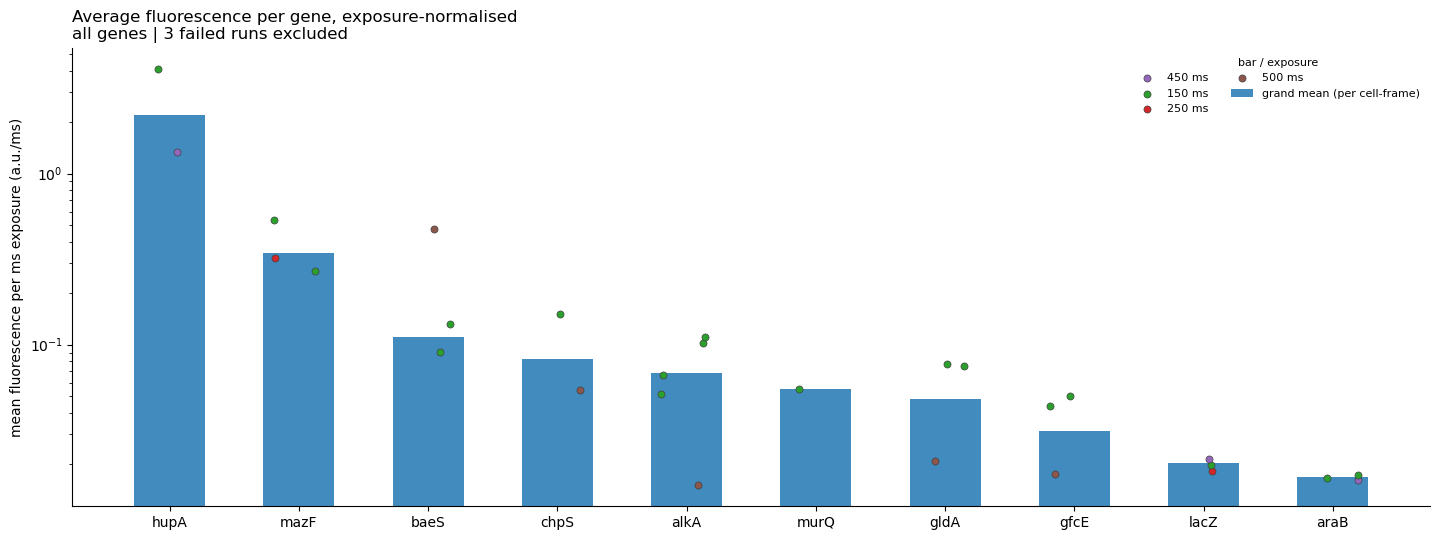

In [222]:
norm_summary, norm_per_exp = fluor_by_gene(fluor_df, FLUOR_COL)
print(f'mean fluorescence per ms of exposure  '
      f'[{scope_label(None, EXPERIMENTS, FOVS, MIN_TRACK_FRAMES)}]\n')
print(norm_summary.round(4).to_string())

# Did normalising reorder the genes?
ranks = pd.DataFrame({
    'raw_rank': raw_summary['grand_mean'].rank(ascending=False).astype(int),
    'per_ms_rank': norm_summary['grand_mean'].rank(ascending=False).astype(int),
})
ranks['shift'] = ranks['raw_rank'] - ranks['per_ms_rank']
print('\nrank change from normalising (0 = unchanged):')
print(ranks.sort_values('raw_rank').to_string())

plot_fluor_bars(norm_summary, norm_per_exp,
                vlabel=FLUOR_LABEL,
                title='Average fluorescence per gene, exposure-normalised',
                name=f'fluor_per_gene_per_ms{SUFFIX}');

### Does the linear-exposure assumption hold? — read this before quoting Figure 6

Dividing by `fluor_exposure_ms` assumes the detector responds linearly across 150–500 ms. That is
an assumption, not a measurement, and the data only half-supports it. The check below compares
each gene's **replicate spread** — max/min of its per-experiment means — before and after
normalising. If exposure were the dominant difference between a gene's experiments, normalising
would shrink it.

| | genes (raw fold → per-ms fold) | reading |
|---|---|---|
| **shrinks** | araB 2.96 → 1.07, lacZ 3.27 → 1.18, baeS 17.6 → 5.28 | exposure really was the confounder — and these are the genes with several replicates genuinely spread across settings |
| **unchanged** | mazF 1.97 → 1.97, murQ (one experiment) | only one exposure among the replicates that differ |
| **grows** | alkA 2.23 → 7.42, gldA 1.10 → 3.66, hupA 1.03 → 3.08, gfcE 1.34 → 2.87, chpS 1.20 → 2.77 | their raw means already agreed across different exposures, so dividing pulls them apart |

**Why the second row is not simply a refutation.** For those genes exposure is almost perfectly
**confounded with experiment**: all but one replicate sits at 150 ms and the odd one out at 450 or
500 ms, so "the 500 ms run" and "that particular acquisition" are the same thing, and no
arithmetic separates them. alkA is the clearest case — its 500 ms run has a *lower* raw mean
(7.5) than three of its four 150 ms runs (7.7–16.7), which a linear detector cannot produce at
equal expression. Either those cells were genuinely dimmer, or the response is not linear over 3×.

**It is not sensor saturation.** The largest single pixel anywhere in the filtered dataset is
**2,432 counts**, nowhere near any plausible ADC ceiling, and hupA — the brightest gene, and the
one whose raw means match across a 3× exposure change — tops out there rather than clipping flat.

**What to do with it.** Quote Figure 6 for the cross-gene ranking, which is what it is for and
which the rank table shows is barely affected. Do **not** read a 2–3× difference between two
experiments of the *same* gene as biology. And note that none of this reaches the burst results:
those are relative to each `(gene, experiment)`'s own noise, so they are identical either way.

In [223]:
# Does normalising shrink or grow each gene's replicate spread? If exposure were the dominant
# difference between a gene's experiments, dividing by it would shrink the spread. Printed
# rather than asserted, because the answer is mixed -- see the markdown above.
_chk = (fluor_df.groupby(['gene', 'experiment_name'])
        .agg(exposure_ms=(EXPOSURE_COL, 'first'),
             n_rows=(RAW_FLUOR_COL, 'size'),
             raw=(RAW_FLUOR_COL, 'mean'), per_ms=(FLUOR_COL, 'mean'))
        .reset_index())

_fold = _chk.groupby('gene').agg(
    n_exp=('exposure_ms', 'size'),
    n_exposures=('exposure_ms', 'nunique'),
    raw_fold=('raw', lambda s: s.max() / s.min()),
    per_ms_fold=('per_ms', lambda s: s.max() / s.min()))
_fold['verdict'] = np.where(
    _fold['n_exposures'] < 2, 'single exposure',
    np.where(_fold['per_ms_fold'] < _fold['raw_fold'] - 1e-9, 'normalising helps',
             np.where(_fold['per_ms_fold'] > _fold['raw_fold'] + 1e-9,
                      'normalising HURTS', 'no change')))

print('replicate spread per gene, before and after normalising  '
      '(fold = max/min over that gene\'s per-experiment means)\n')
print(_fold.round(2).sort_values('per_ms_fold').to_string())
print(f"\nhelps: {(_fold.verdict == 'normalising helps').sum()}  |  "
      f"hurts: {(_fold.verdict == 'normalising HURTS').sum()}  |  "
      f"n/a: {(_fold.n_exposures < 2).sum()}")

# The saturation question, answered rather than assumed: a clipped sensor would pile up at a
# power-of-two ceiling. `intensity_max_fluor` is not in SUMMARY_COLS, so read just that column.
_mx = pd.read_csv(CSV_PATH, usecols=['experiment_name', 'intensity_max_fluor'],
                  dtype={'experiment_name': str})
_mx = _mx[~_mx['experiment_name'].isin(list(FAILED_EXPERIMENTS))]
print(f'\nbrightest single pixel in the filtered dataset: '
      f'{_mx.intensity_max_fluor.max():,.0f} counts -- no ADC ceiling in sight, '
      f'so the non-linearity above is not clipping.')
del _mx

replicate spread per gene, before and after normalising  (fold = max/min over that gene's per-experiment means)

      n_exp  n_exposures  raw_fold  per_ms_fold            verdict
gene                                                              
murQ      1            1      1.00         1.00    single exposure
araB      3            2      2.96         1.07  normalising helps
lacZ      3            3      3.27         1.18  normalising helps
mazF      3            2      1.97         1.97  normalising helps
chpS      2            2      1.20         2.77  normalising HURTS
gfcE      3            2      1.34         2.87  normalising HURTS
hupA      2            2      1.03         3.08  normalising HURTS
gldA      3            2      1.10         3.66  normalising HURTS
baeS      3            2     17.60         5.28  normalising helps
alkA      5            2      2.23         7.42  normalising HURTS

helps: 4  |  hurts: 5  |  n/a: 1

brightest single pixel in the filtered dataset: 

---
# 6 — Bursts: single-trench inspection

Everything above is pooled. These two functions drop into one trench — the step between spotting
an odd number in a table and opening `data/kymograph_viewer_082026.html`. Both take
`(experiment_name, FOV, peak_id)`; use Table C to find valid combinations.

**A note on the lookup.** `FOV` and `trench_id` are zero-padded **strings** here (`'015'`,
`'228'`) so they join to `experiment_metadata` and the viewer's card ids. The version of
`plot_track_fluorescence` in the older notebook opened with `fov = int(fov)`, which was right
there — a bare `read_csv` gave int64 — but silently matches **nothing** against strings, so every
call would fall through to `WARNING: no rows`. `select_trench` below normalises whatever you pass,
so `('015', 228)` and `(15, '228')` both work.

In [224]:
def select_trench(df, exp, fov, peak_id):
    """Rows for one trench, tolerant of int or str ids.

    FOV is stored zero-padded to 3 chars; trench_id (peak_id) is stored unpadded, so
    str(int(...)) strips any leading zeros the caller supplies.
    """
    return df[(df['experiment_name'] == exp)
              & (df['FOV'] == str(fov).zfill(3))
              & (df['trench_id'] == str(int(peak_id)))]

In [225]:
def plot_track_fluorescence(df, exp, fov, peak_id, cell_id=None,
                            fluor_col=FLUOR_COL, save=False):
    """Plot avg fluorescence vs time for each unique cell track in one trench.

    Left panel:  raw time_frame on the x-axis.
    Right panel: time re-zeroed per track (frames since each track's first appearance).

    Args:
        df: per-cell-per-frame DataFrame (e.g. all_data) with columns
            experiment_name, FOV, trench_id, track_id, time_frame, and fluor_col.
        exp: experiment_name (str).
        fov: FOV id (accepts zero-padded str like '015' or int).
        peak_id: trench / peak id (accepts str or int); matches df['trench_id'].
        cell_id: optional track_id (int) of a single lineage to highlight. When given,
            that lineage is drawn boldly and all other tracks are dimmed to gray so it's
            easy to focus on one lineage. The id matches the labels shown in the
            kymograph viewer. When None (default), all tracks are plotted as usual.
        fluor_col: fluorescence column to plot (default FLUOR_COL, a.u./ms).
        save: write the figure to FIG_DIR as well as displaying it.
    """
    sub = select_trench(df, exp, fov, peak_id)

    if sub.empty:
        print(f"WARNING: no rows for experiment={exp!r}, FOV={fov}, trench/peak={peak_id}")
        return

    track_ids = sorted(sub['track_id'].unique())
    # tab20 by position in the sorted track list -- deliberately NOT the pinned tab10 gene
    # palette. This matches build_track_color_map() in generate_kymograph_viewer.py, so a
    # line here is the same colour as that track in the HTML viewer.
    cmap = plt.get_cmap('tab20', len(track_ids))
    track_colors = {tid: cmap(i) for i, tid in enumerate(track_ids)}

    # Validate the requested highlight id; fall back to normal rendering if not found.
    if cell_id is not None:
        cell_id = int(cell_id)
        if cell_id not in track_ids:
            print(f"WARNING: cell_id={cell_id} not found in FOV {fov}, trench {peak_id}. "
                  f"Available track_ids: {track_ids}")
            cell_id = None

    fig, (ax_raw, ax_elapsed) = plt.subplots(1, 2, figsize=(14, 5))

    for tid in track_ids:
        g = sub[sub['track_id'] == tid].sort_values('time_frame')
        elapsed = g['time_frame'] - g['time_frame'].min()

        if cell_id is None:
            # Default: every track in its own color.
            kw = dict(color=track_colors[tid], label=tid)
        elif tid == cell_id:
            # Highlighted lineage: bold, opaque, drawn on top.
            kw = dict(color=track_colors[tid], label=tid, linewidth=2.5, alpha=1.0, zorder=3)
        else:
            # Everything else: dimmed to gray in the background.
            kw = dict(color='lightgray', linewidth=1.0, alpha=0.4, zorder=1)

        ax_raw.plot(g['time_frame'], g[fluor_col], **kw)
        ax_elapsed.plot(elapsed, g[fluor_col], **kw)

    highlight_note = f' (cell {cell_id})' if cell_id is not None else ''
    ax_raw.set_xlabel('Time frame')
    ax_raw.set_ylabel(FLUOR_LABEL)
    ax_raw.set_title(f'{exp}\nFOV {fov}, trench {peak_id} - raw time{highlight_note}')

    ax_elapsed.set_xlabel('Frames since track start')
    ax_elapsed.set_ylabel(FLUOR_LABEL)
    ax_elapsed.set_title(f'{exp}\nFOV {fov}, trench {peak_id} - time elapsed per track{highlight_note}')

    for ax in (ax_raw, ax_elapsed):
        _style(ax)

    # Legend: show just the highlighted track when one is set, otherwise the usual
    # all-tracks legend when the count is small enough to be readable.
    if cell_id is not None:
        ax_raw.legend(title='track_id', fontsize=8)
    elif len(track_ids) <= 20:
        ax_raw.legend(title='track_id', fontsize=8, ncol=2)

    fig.tight_layout()
    if save:
        print(_save(fig, f'track_fluor_{exp}_{str(fov).zfill(3)}_{int(peak_id)}'))
    return fig

In [226]:
def plot_trench_dy_dfluor(pairs, exp, fov, peak_id, bins=40, cell_id=None,
                          top_n=10, save=False):
    """Δy and Δfluor for one trench, highlighted against its whole experiment.

    Companion to plot_track_fluorescence, same (exp, fov, peak_id) arguments but reading
    the pair table rather than the cell table.

    The grey histogram is every pair in the experiment; the trench is drawn on top of it,
    so you can see at a glance whether this trench moves or changes brightness unusually
    for its experiment. The trench is ~9% of the experiment's pairs and its rarest bins
    hold a single pair, so the y-axis is log -- on a linear axis the trench peak is only
    10-14% of the axis height and the tails are invisible.

    UNITS. delta_fluor = fluor(t+1) - fluor(t), where fluor is the mean pixel value inside
    the cell mask on the BACKGROUND-SUBTRACTED channel, divided by that experiment's
    fluor_exposure_ms (the load cell does this). So it is a.u./ms per FRAME: exposure-
    normalised, but still not per-minute. The grey backdrop is one experiment anyway, so the
    5-vs-10 min/frame difference never enters this figure.

    Args:
        pairs: pair-level DataFrame (pairs_all).
        cell_id: optional track_id; narrows the highlight to one track, backdrop unchanged.
        top_n: print this many pairs with the largest fluorescence INCREASE (0 = skip).
        save: write the figure to FIG_DIR as well as displaying it.
    """
    backdrop = pairs[pairs['experiment_name'] == exp]
    if backdrop.empty:
        print(f"WARNING: no pairs for experiment={exp!r}")
        return

    sub = select_trench(pairs, exp, fov, peak_id)
    if sub.empty:
        print(f"WARNING: no pairs for experiment={exp!r}, FOV={fov}, trench/peak={peak_id}")
        return

    if cell_id is not None:
        cell_id = int(cell_id)
        if cell_id not in set(sub['track_id']):
            print(f"WARNING: cell_id={cell_id} has no pairs in FOV {fov}, trench {peak_id}. "
                  f"Available track_ids: {sorted(sub['track_id'].unique())}")
            cell_id = None
        else:
            sub = sub[sub['track_id'] == cell_id]

    mins = int(sub['minutes_per_frame'].iloc[0])
    note = f' | cell {cell_id}' if cell_id is not None else ''
    print(f'{exp} FOV {str(fov).zfill(3)} trench {int(peak_id)}{note}: '
          f'{len(sub)} pairs | {sub.track_id.nunique()} tracks | '
          f'median cell length {sub.cell_length.median():.1f} px  '
          f'(experiment backdrop: {len(backdrop)} pairs)')

    fig, (ax_dy, ax_df) = plt.subplots(1, 2, figsize=(14, 4.5))

    panels = ((ax_dy, 'delta_y',
               'Δy = centroid_y(t+1) − centroid_y(t)  [px]'),
              (ax_df, 'delta_fluor',
               'Δfluor = fluor(t+1) − fluor(t)  [a.u./ms per frame, bg-subtracted]'))

    for ax, col, xlabel in panels:
        # Bin edges from the EXPERIMENT's robust range: a handful of extreme pairs would
        # otherwise flatten every bin that matters.
        lo, hi = np.nanpercentile(backdrop[col].dropna(), [0.5, 99.5])
        edges = np.linspace(lo, hi, bins + 1)

        ax.hist(backdrop[col].dropna(), bins=edges, color=C_ALL, alpha=0.55,
                label=f'experiment (n={len(backdrop):,})')
        ax.hist(sub[col].dropna(), bins=edges, color=C_MAIN, alpha=0.95,
                label=f'this trench (n={len(sub):,})')

        off = int(((sub[col] < lo) | (sub[col] > hi)).sum())
        if off:
            # Say so rather than letting the clipped range imply the trench has no tail.
            ax.plot([], [], ' ', label=f'{off} trench pair(s) off-axis')

        ax.set_yscale('log')          # the trench is ~9% of the backdrop; linear hides it
        ax.set_xlabel(xlabel)
        ax.set_ylabel('pair count (log)')
        ax.legend(frameon=False, fontsize=8)
        _style(ax)

    ax_dy.set_title(f'{exp}\nFOV {str(fov).zfill(3)}, trench {int(peak_id)}{note} — Δy',
                    fontsize=10)
    ax_df.set_title(f'{exp}\nFOV {str(fov).zfill(3)}, trench {int(peak_id)}{note} — Δfluor',
                    fontsize=10)

    fig.tight_layout()
    if save:
        print(_save(fig, f'trench_dy_dfluor_{exp}_{str(fov).zfill(3)}_{int(peak_id)}'))

    if top_n:
        cols = ['track_id', 'frame_from', 'frame_to', 'time_min_from',
                'fluor_from', 'fluor_to', 'delta_fluor',
                'delta_y', 'delta_y_cell_lengths', 'predicted_lineage']
        top = (sub[sub['delta_fluor'] > 0]
               .sort_values('delta_fluor', ascending=False)
               .head(top_n)[cols])
        print(f'\ntop {len(top)} pairs by fluorescence INCREASE  '
              f'(a.u./ms per frame, {mins} min/frame)')
        # delta_y is kept alongside on purpose: a large step next to a large displacement
        # is usually the track moving, not the cell brightening.
        print(top.round(3).to_string(index=False))

    return fig

### Worked example

Change `EX_EXP` / `EX_FOV` / `EX_PEAK` to inspect a different trench — Table C above lists every
valid `(gene, experiment, FOV, peak_ids)` combination. Set `cell_id=` on either function to
follow one lineage; the ids match the "cell N" entries in the kymograph viewer's dropdown.

DUMM_giTG059_060_061125 FOV 008 trench 1488: 409 pairs | 98 tracks | median cell length 39.6 px  (experiment backdrop: 747 pairs)

top 10 pairs by fluorescence INCREASE  (a.u./ms per frame, 10 min/frame)
 track_id  frame_from  frame_to  time_min_from  fluor_from  fluor_to  delta_fluor  delta_y  delta_y_cell_lengths predicted_lineage
        8          11        12            110       0.039     0.063        0.024   -1.014                -0.029               5.1
        3           4         5             40       0.007     0.029        0.023   11.275                 0.293               2.1
       44          52        53            520       0.015     0.034        0.019  -13.829                -0.334          10.2.1.2
        8          10        11            100       0.021     0.039        0.018   11.065                 0.176               5.1
       42          48        49            480       0.015     0.032        0.017 -128.131                -0.393              12.2
       89 

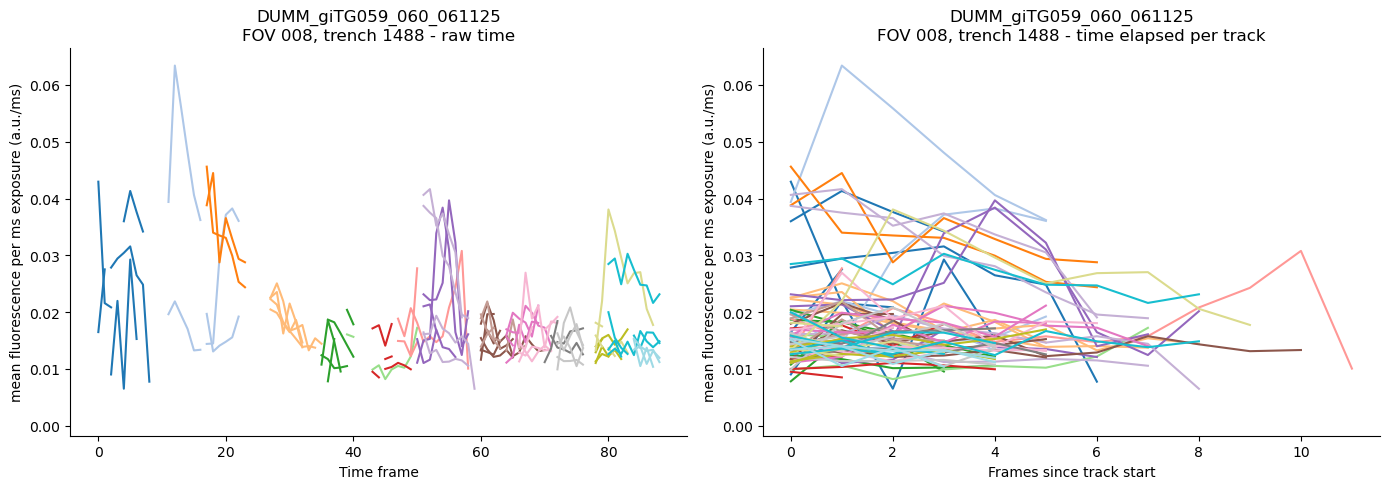

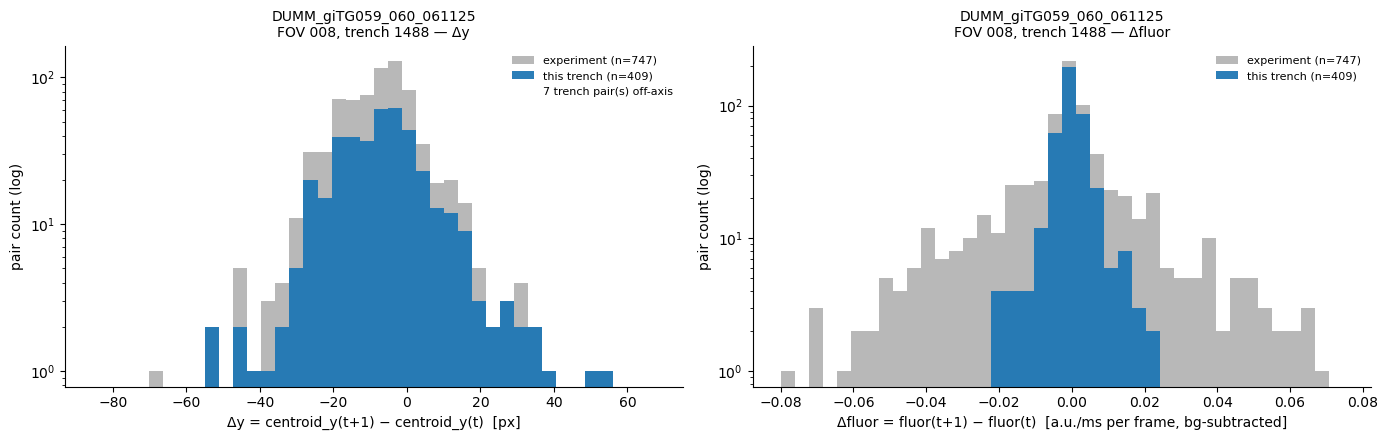

In [227]:
EX_EXP, EX_FOV, EX_PEAK = 'DUMM_giTG059_060_061125', '008', '1488'

plot_track_fluorescence(all_data, EX_EXP, EX_FOV, EX_PEAK);
plot_trench_dy_dfluor(pairs_all, EX_EXP, EX_FOV, EX_PEAK);

### One trench's Δfluor, greyed against its experiment

`plot_trench_dfluor_highlight(pairs_all, experiment, FOV, trench_id)` — the Δfluor half of
`plot_trench_dy_dfluor` above, on a single linear-count panel: every positive-Δfluor pair in
the experiment is drawn grey and only the requested trench is colored.

**Why the backdrop is one experiment, not the whole table.** `delta_fluor` is
`intensity_mean_fluor(t+1) − intensity_mean_fluor(t)` in arbitrary camera units **per frame**
on the background-subtracted channel — neither exposure-normalised nor per-minute. The 23
experiments here span four exposure settings and two frame intervals, so pooling them into one
backdrop would compare incomparable units.

Positive values only, matching `plot_dfluor_histogram`: the question is which trenches
brighten unusually. Pass `cell_id=` to narrow the highlight to a single track (backdrop
unchanged), or `save=True` to write the figure to `FIG_DIR`.

In [228]:
def plot_trench_dfluor_highlight(pairs, exp, fov, peak_id, bins=40,
                                 cell_id=None, save=False):
    """Δfluor increase for one trench, colored on top of its whole experiment in grey.

    Single-panel, linear-axis companion to plot_trench_dy_dfluor above: every pair in the
    experiment is drawn grey and only the requested (FOV, trench_id) is colored, so you can
    see at a glance whether this trench brightens unusually for its experiment.

    Only POSITIVE delta_fluor is plotted, matching plot_dfluor_histogram in mmtrack -- the
    question this figure answers is about brightening, not about dimming.

    UNITS. delta_fluor = fluor(t+1) - fluor(t), where fluor is the mean pixel value inside
    the cell mask on the BACKGROUND-SUBTRACTED channel, divided by that experiment's
    fluor_exposure_ms (the load cell does this). So it is a.u./ms per FRAME. Exposure is
    handled, but the frame interval is not, which is why the grey backdrop is still one
    experiment rather than the whole dataset: the set mixes 5 and 10 min/frame.

    Args:
        pairs: pair-level DataFrame (pairs_all).
        exp: experiment_name (str).
        fov: FOV id (accepts zero-padded str like '008' or int).
        peak_id: trench / peak id (accepts str or int); matches pairs['trench_id'].
        bins: number of bins spanning the backdrop's 0-99.5th percentile range.
        cell_id: optional track_id; narrows the highlight to one track, backdrop unchanged.
        save: write the figure to FIG_DIR as well as displaying it.
    """
    backdrop = pairs[pairs['experiment_name'] == exp]
    if backdrop.empty:
        print(f"WARNING: no pairs for experiment={exp!r}")
        return

    sub = select_trench(pairs, exp, fov, peak_id)
    if sub.empty:
        print(f"WARNING: no pairs for experiment={exp!r}, FOV={fov}, trench/peak={peak_id}")
        return

    if cell_id is not None:
        cell_id = int(cell_id)
        if cell_id not in set(sub['track_id']):
            print(f"WARNING: cell_id={cell_id} has no pairs in FOV {fov}, trench {peak_id}. "
                  f"Available track_ids: {sorted(sub['track_id'].unique())}")
            cell_id = None
        else:
            sub = sub[sub['track_id'] == cell_id]

    # Positive increases only, on both layers, so the two histograms mean the same thing.
    back_pos = backdrop.loc[backdrop['delta_fluor'] > 0, 'delta_fluor'].dropna()
    sub_pos = sub.loc[sub['delta_fluor'] > 0, 'delta_fluor'].dropna()
    if back_pos.empty:
        print(f"WARNING: no positive delta_fluor pairs in experiment={exp!r}")
        return

    note = f' | cell {cell_id}' if cell_id is not None else ''
    print(f'{exp} FOV {str(fov).zfill(3)} trench {int(peak_id)}{note}: '
          f'{len(sub)} pairs ({len(sub_pos)} with a fluorescence increase) | '
          f'{sub.track_id.nunique()} tracks  '
          f'(experiment backdrop: {len(backdrop):,} pairs, {len(back_pos):,} increases)')

    # Bin edges from the BACKDROP's robust range, so the grey reference distribution is
    # identical no matter which trench is selected. A handful of extreme pairs would
    # otherwise flatten every bin that matters.
    hi = np.nanpercentile(back_pos, 99.5)
    edges = np.linspace(0, hi, bins + 1)

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.hist(back_pos, bins=edges, color=C_ALL, alpha=0.55,
            label=f'experiment (n={len(back_pos):,})')
    # Drawn second so the trench sits on top of the grey.
    ax.hist(sub_pos, bins=edges, color=C_MAIN, alpha=0.95,
            label=f'this trench (n={len(sub_pos):,})')

    off = int((sub_pos > hi).sum())
    if off:
        # Say so rather than letting the clipped range imply the trench has no tail.
        ax.plot([], [], ' ', label=f'{off} trench pair(s) off-axis')

    # Linear y-axis. A trench holds a median ~5% of its experiment's positive-Delta pairs
    # (range 0.5-56% across the 292 trenches here), so on linear counts its bars are
    # usually much shorter than the grey: read the grey as a reference distribution to
    # place the trench against, not as a same-height rival. Switch to ax.set_yscale('log')
    # -- what plot_trench_dy_dfluor above does -- if a sparse trench disappears.
    ax.set_xlabel(DFLUOR_LABEL)
    ax.set_ylabel('pair count')
    ax.set_title(f'{exp}\nFOV {str(fov).zfill(3)}, trench {int(peak_id)}{note} '
                 f'— Δfluor increase vs experiment', fontsize=10)
    ax.legend(frameon=False, fontsize=8)
    _style(ax)

    fig.tight_layout()
    if save:
        print(_save(fig, f'trench_dfluor_{exp}_{str(fov).zfill(3)}_{int(peak_id)}'))
    return fig

DUMM_giTG059_060_061125 FOV 008 trench 1488: 409 pairs (192 with a fluorescence increase) | 98 tracks  (experiment backdrop: 747 pairs, 345 increases)


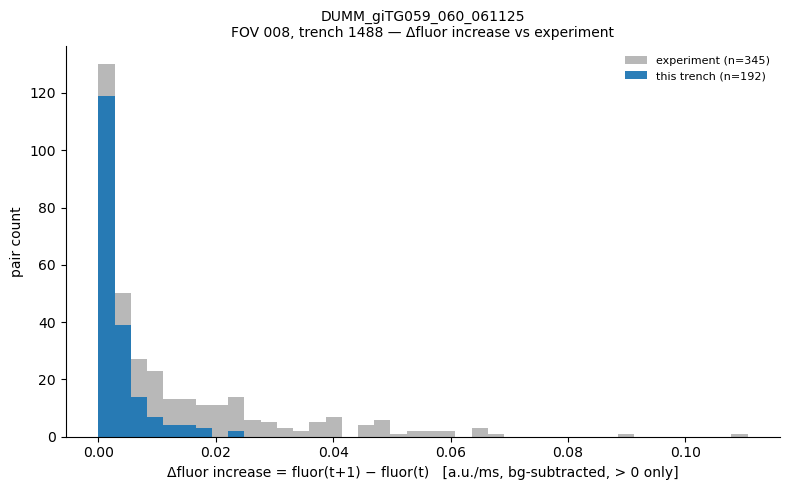

In [229]:
# EX_EXP / EX_FOV / EX_PEAK are set in the worked-example cell above -- change them there.
plot_trench_dfluor_highlight(pairs_all, EX_EXP, EX_FOV, EX_PEAK);

---
# 7 — Bursts in expression

A **burst** is a cell sitting dark and then jumping sharply in fluorescence. The reference case
is `CL008_giTG068_072925 | FOV 003 | trench 1598 | track_id 12` (araB): flat at ~0.021 a.u./ms
for frames 31–36, then **0.0192 → 0.0539 → 0.0758** at frames 36–38, peaking at **0.0763** at
frame 39 and decaying slowly to 0.0410 by frame 55 as the cell grows.

**The acceptance test is `mazF`, `hupA`, `chpS`.** These are constitutive — always expressing,
high fluorescence — so a correct definition must score them near zero. This is what makes the
problem non-trivial, because they are also the *brightest* genes in the set: any rule keyed on
absolute fluorescence ranks them first.

### Why the obvious definitions fail

Fluorescence is a mean pixel value per ms of exposure. Median baseline still runs from
0.0141 a.u./ms (alkA) to 3.99 (hupA) — a **283×** spread — because normalising removes the
exposure term but not the expression level, which is the bigger one. (It is wider than the 218×
of the raw units for the reason section 5 sets out: for several genes exposure is confounded
with experiment.) So **an absolute Δ cutoff is still not comparable across genes**: any threshold
that catches the araB burst (Δ = +0.057 a.u./ms from baseline to peak) fires on every hupA wobble.

**Fold change** (`F(t+1)/F(t) ≥ K`) cancels the units, but divides by a small number: **865 of
the 81,002 pairs** start from an `F(t)` below 20% of their own `(gene, experiment)` median, and
one is exactly 0. A prototype using fold ≥ 2 **and** a robust
z ≥ 5 still failed the control (mazF 3rd of 10), because it counts one episode once per cell:
mazF trench 1768 registered 4 times — tracks 7/8/8/11 at frames 18/21/23/27 — for a single
burst propagating through a lineage.

### What this section uses instead

Detection runs on a **max-fluorescence envelope** — the brightest cell at each frame — which
makes an inherited burst one smooth hump instead of one event per descendant, and requires
**prominence** rather than height. As of **v2** the envelope is taken per **lineage family**
rather than per trench, so two bursts running at once in one trench are not masked by whichever
is brighter; concurrent events in adjacent cells are then merged back together. Prominence is a peak's height above the highest
saddle you must descend before reaching higher ground on either side. A flat-high trace clears
any height bar but has near-zero prominence — *this is the criterion that zeroes the
constitutive genes.*

Thresholds are robust: `median + k · 1.4826 · MAD`, where `MAD = median(|x − median x|)`.
Unlike a standard deviation, MAD is not squared-error based, so one 400 a.u. spike cannot
inflate it. The 1.4826 factor is 1/Φ⁻¹(0.75), which rescales MAD so that on clean Gaussian
noise "k MAD-scales" means the same as "k sigma" — `k` stays interpretable in familiar units
without being wrecked by the very outliers being hunted.

Ported from `notebooks/trackastra_figures.ipynb` cell 26, with every fix and every later
change recorded in the changelog below. **Read the changelog before trusting a number** — the
active definition is whatever `BURST_DEF` points at, and each output table carries its
`def_version`.

### Definition changelog — append only

The definition will change. Add a new version below and a new `BURST_DEF_V*` dict; **do not
edit an old one in place.** Every output table carries a `def_version` column so a saved result
can always be traced to the rule that produced it.

---

**v1** — 2026-08-24. Initial port from `notebooks/trackastra_figures.ipynb` cell 26.

A frame on a trench's max envelope is a burst when all three hold:

1. **Height** — `fluor > median + k · 1.4826 · MAD`, taken per **(gene, experiment_name)**.
2. **Local peak** — the maximum within ±`window` frames.
3. **Prominence** — rise ≥ `k · mad_scale`. The criterion that zeroes the constitutive genes.

Then **episode merge**, so a slow decay counts once: walking peaks in time, a later peak opens
a new burst only if the envelope first drops back below threshold, or climbs above the previous
peak + prominence. The araB example collapses to a single burst at frame 39.

Fixes applied during the port, all confirmed against the data:

- **Baseline keys are `(gene, experiment_name)`, never experiment alone.** 10 of the 23
  experiments hold two genes, so experiment-only scaling makes a dim and a bright gene share
  one noise ruler. Scaling per experiment alone put chpS at 1.72 per 1000 pairs; per
  gene×experiment it drops to 0.92. Do not "simplify" this.
- **FOV dtype.** The original `plot_bursts_for_trench` did `fov = int(fov)`, which matches
  nothing against this notebook's zero-padded string FOVs. Now routed through `select_trench`.
- **`node_id`** was added to `SUMMARY_COLS` in section 1 — `detect_bursts` records it, and it
  is in the CSV but was not being loaded.

Known quirk, measured not guessed: **`window` is inert while prominence is on.** 80 bursts at
every `window` from 1 to 8, with the reference trenches unchanged; it only begins to bite at
`window` = 12 (77 bursts). It is a fallback that prominence makes redundant — with prominence
disabled `window` does matter (250 bursts at 1, 167 at 5, 151 at 8), which is presumably the
regime it was originally tuned in. Leave it alone and tune `k`.

**Prominence is the load-bearing criterion.** Disabling it at `window` = 5 takes the count from
80 to 167 and breaks the constitutive control: hupA goes from 0.00 to 1.32 bursts per 100 cells,
last place to 5th of 10. Height alone cannot separate constitutive from bursty — `hupA` sits at
~598 a.u. permanently and clears any absolute bar.
---

**v2** — 2026-08-24. **Detects concurrent bursts.** Signal changes from one envelope per trench
to one per **lineage family**, followed by a merge step. `k`, `window` and the baseline rule are
unchanged from v1.

*What v1 got wrong.* `trench_max_envelope` is a scalar max per frame, so two bursts running at
once in one trench collapse into a single hump and the dimmer one is masked. The case:
`DUMM_giTG059_060_061125 | FOV 008 | trench 1488`, frames 50–59, holds two real bursts —

- **A**: track 41 rises at frames 49–50 and divides at 51 into 49 + 50, both daughters carrying
  the protein. Peak 10.41 at frame 52. *v1 counts this once, correctly — inheritance is not a
  new burst.*
- **B**: tracks 44 and 45, two adjacent cells nearer the open end, peaking 9.60 / 9.92 at frames
  54–55. At frame 55 the cells sort by `centroid_y` as `45@88, 44@121, 43@172, 50@217, 49@263` —
  a **dark** cell (43, F = 3.4) separates the two bright regions, so they are plainly distinct.

v1 reported **one** burst there. Burst B's peak has a measured prominence of **0.78** against the
required 4.38, because burst A is still at 9.14 at frame 53 and leaves no saddle between them.

*Why the merge step is needed too.* Per-family detection alone over-splits: tracks 44 and 45 sit
in different lineage families (roots 30 and 31), so burst B gets counted twice. Two events are
treated as one burst when their peaks are within `merge_window` frames **and** their centroids are
within `merge_gap_cell_lengths`. The gap is in **cell lengths**, not pixels, for the same reason
`flag_jumps` uses them (`mmtrack/track_displacement.py`) — the unit is independent of
magnification and cell size. It is an insensitive choice: 1.5, 2.0 and 2.5 all give 95, because
the 7 concurrent pairs in this dataset sit at ≤ 1.06 or ≥ 2.77 cell lengths, with 44/45 at 1.41.

`merge_keep='earliest'` reports the **onset** of a merged burst, so timing is not biased late by
whichever neighbour happened to peak brighter. Burst B is therefore reported at frame 54, not 55.

*Effect.* 80 → 100 bursts from per-family detection, then → **95** after merging 5 of the 7
concurrent pairs. The `TOTAL` count and every rate change accordingly; `gldA` moves 6th → 3rd
(0.38 → 0.90 per 100 cells) and `alkA` 3rd → 5th. araB, murQ and all three constitutive genes are
unchanged. Run the merge-audit cell to see every concurrent pair and its verdict.

*Regression checks that must keep passing.* The FOV 007/821 fragmentation case still yields
exactly 1 burst — all six of the tracks the tracker split that cell across land in one lineage
family, and the spatial merge is a second safety net when they do not. Trench 003/1598 still
yields 1 at frame 39.

*Caveat, measured not guessed.* v2 is more sensitive than v1 at low `k`: at `k = 2.0` chpS climbs
to 3rd of 10 (5th under v1), so the constitutive control is not clean down there. At the shipped
`k = 4.0` chpS is 7th and mazF is 10th at every `k` from 2 to 6. Also note the concurrent pair in
trench 1488 disappears at `k = 6.0` — both bursts fall under the height threshold.

---

**Units change — 2026-09-01.** Not a new definition: `BURST_DEF_V1['fluor_col']` moved from
`intensity_mean_fluor` (raw a.u.) to `fluor_per_ms` (a.u./ms), and v2 and v3 inherit it. **Every
number in the v1 and v2 entries above is in the raw a.u. of the run that measured it and has not
been rewritten** — divide by that experiment's `fluor_exposure_ms` to compare with a current
table (150 ms for the araB reference trench, 250 ms for trench 1488).

*Why this is a units change and not a definition change.* `fluor_exposure_ms` is constant within
an experiment and `compute_baselines` groups by `(gene, experiment_name)`, so the median, the
MAD scale, the height threshold and the required prominence all scale by the same 1/E. Every
criterion is a comparison between quantities that scaled identically, so no verdict can move.
Verified empirically rather than argued: re-running the full pipeline after the switch gives the
same **94** events with the same per-gene counts (lacZ 35, araB 22, gfcE 14, alkA 9, gldA 7,
baeS 4, chpS 2, murQ 1, hupA 0, mazF 0), the same 7-row merge audit, and a bit-identical k-sweep
table.

**Failed runs excluded at load — 2026-09-01.** Also not a definition change. The three failed
acquisitions are dropped in section 2, so detection now runs on 20 experiments rather than 23.
Equivalent to filtering the old full-dataset burst table, for the same baseline-grouping reason:
**95 → 94**, the lost event being the marginal chpS burst in `DUMM_alkA_chpS_111325`. One
consequence for the v2 entry above: its *caveat* about chpS climbing to 3rd of 10 at `k = 2.0`
was measured on the unfiltered frame. On the filtered frame chpS is **6th** at `k = 2.0` and
5th at `k = 3.0`, so the control is better behaved at low `k` than that entry warns.

In [230]:
# The versioned burst definition. Single source of truth for every call below -- change the
# rule by adding a new dict and repointing BURST_DEF, never by editing an old one in place.
BURST_DEF_V1 = {
    'version': 'v1',
    'k': 4.0,                       # MAD multiplier: sets the height threshold AND the
                                    # required prominence
    'window': 5,                    # +/- frames for the local-max check / peak separation
    'min_prominence': None,         # None -> k * mad_scale
    'fluor_col': FLUOR_COL,         # a.u./ms. Detection is invariant under the rescale:
                                    # baselines are per (gene, experiment) and exposure is
                                    # constant within an experiment, so median, MAD, height
                                    # and prominence all scale by the same 1/E.
    'signal': 'per-trench max envelope',
    'baseline_keys': ('gene', 'experiment_name'),
    'constitutive_genes': ('mazF', 'hupA', 'chpS'),
}

# v2 detects on per-LINEAGE-FAMILY envelopes so two bursts running at once in one trench are
# not masked by whichever is brighter, then merges concurrent adjacent events back together.
# See the changelog above for the evidence.
BURST_DEF_V2 = {
    **BURST_DEF_V1,
    'version': 'v2',
    'signal': 'per-lineage-family max envelope',
    'merge_window': 5,                 # frames; peaks this close together are concurrent
    'merge_gap_cell_lengths': 1.5,     # centroid gap below this = one burst, not two
    'merge_keep': 'earliest',          # report burst onset, not the brighter neighbour
}

BURST_DEF = BURST_DEF_V2
CONSTITUTIVE_GENES = set(BURST_DEF['constitutive_genes'])

_bkeys = ' x '.join(BURST_DEF['baseline_keys'])
print(f"burst definition {BURST_DEF['version']}: k={BURST_DEF['k']}, "
      f"window={BURST_DEF['window']}, signal={BURST_DEF['signal']}, "
      f"baseline per {_bkeys}")
if 'merge_gap_cell_lengths' in BURST_DEF:
    print(f"  concurrent-burst merge: peaks within {BURST_DEF['merge_window']} frames and "
          f"{BURST_DEF['merge_gap_cell_lengths']} cell lengths -> one event "
          f"({BURST_DEF['merge_keep']} kept)")
print(f"constitutive control genes (expected ~0 bursts): {sorted(CONSTITUTIVE_GENES)}")

burst definition v2: k=4.0, window=5, signal=per-lineage-family max envelope, baseline per gene x experiment_name
  concurrent-burst merge: peaks within 5 frames and 1.5 cell lengths -> one event (earliest kept)
constitutive control genes (expected ~0 bursts): ['chpS', 'hupA', 'mazF']


In [231]:
# Ported verbatim from notebooks/trackastra_figures.ipynb cell 26. Kept faithful to the
# original so the two can still be diffed; the fixes and the v2 changes live in the next
# cell and the callers, and are listed in the changelog above.
import itertools
from collections import defaultdict

from scipy.signal import find_peaks
from scipy.stats import chi2


def build_lineage_traces(df_trench, fluor_col=FLUOR_COL):
    """Stitch each cell onto its ancestors into continuous root->leaf fluorescence traces.

    A track_id only lasts until the cell divides (then daughters get new track_ids). Walking
    up parent_track_id and concatenating gives each root->leaf path as one continuous signal,
    so a daughter's *inherited* fluorescence appears as a declining slope rather than a fresh
    peak. Used here mainly for plotting the individual per-cell traces; burst detection runs
    on the per-frame max envelope (see detect_bursts / trench_max_envelope).

    Args:
        df_trench: rows for ONE (experiment_name, FOV, trench_id) group.
        fluor_col: fluorescence column to pull into the trace.

    Returns:
        list of DataFrames (one per root->leaf path), each sorted by time_frame with columns
        time_frame, fluor, node_id, track_id, predicted_lineage.
    """
    track_rows, parent_of, children = {}, {}, defaultdict(list)
    for tid, g in df_trench.groupby('track_id'):
        g = g.sort_values('time_frame')
        track_rows[tid] = g
        par = g['parent_track_id'].iloc[0]
        par = int(par) if pd.notna(par) else None
        parent_of[tid] = par
        if par is not None:
            children[par].append(tid)

    leaves = [t for t in track_rows if t not in children]
    if not leaves:                       # degenerate (e.g. a cycle) -> treat all as leaves
        leaves = list(track_rows)

    traces = []
    for leaf in leaves:
        chain, cur, seen = [], leaf, set()
        while cur is not None and cur in track_rows and cur not in seen:
            seen.add(cur)                # guard against cyclic parent references
            chain.append(cur)
            par = parent_of.get(cur)
            cur = par if (par in track_rows) else None
        chain.reverse()                  # root -> leaf order
        parts = [track_rows[t][['time_frame', fluor_col, 'node_id', 'track_id', 'predicted_lineage']]
                 for t in chain]
        trace = (pd.concat(parts).sort_values('time_frame').reset_index(drop=True)
                   .rename(columns={fluor_col: 'fluor'}))
        traces.append(trace)
    return traces


def trench_max_envelope(df_trench, fluor_col=FLUOR_COL):
    """The brightest cell at each frame -> one continuous signal per trench.

    A burst is inherited by all descendants after a division, so at every frame the
    *maximum* fluorescence across the cells present captures the burst's envelope while
    smoothing the per-cell cell-cycle sawtooth. On this envelope a single burst that decays
    over many frames is one smooth hump, not many little peaks. Returns the picked rows
    (one per time_frame), sorted by time_frame.
    """
    idx = df_trench.groupby('time_frame')[fluor_col].idxmax()
    return df_trench.loc[idx].sort_values('time_frame').reset_index(drop=True)


def compute_baselines(df, fluor_col=FLUOR_COL):
    """Robust per-(gene, experiment) baseline and MAD scale for a modified z-score.

    baseline = median fluorescence; scale = 1.4826 * MAD (median absolute deviation).
    Robust because rare bursts don't inflate the median/MAD (unlike mean/std). A small
    floor keeps the scale positive for near-constant (e.g. constitutive) signals so the
    threshold stays finite.

    Returns a DataFrame indexed by (gene, experiment_name) with columns median, mad_scale.
    """
    rows = []
    for (gene, exp), g in df.groupby(['gene', 'experiment_name']):
        x = g[fluor_col].to_numpy()
        med = np.median(x)
        mad = np.median(np.abs(x - med))
        rows.append({'gene': gene, 'experiment_name': exp,
                     'median': med, 'mad_scale': 1.4826 * mad})
    base = pd.DataFrame(rows).set_index(['gene', 'experiment_name'])
    base['mad_scale'] = base['mad_scale'].clip(lower=1e-6)
    return base


def detect_bursts(df, k=4.0, window=5, min_prominence=None,
                  fluor_col=FLUOR_COL, constitutive_genes=None):
    """Detect fluorescence bursts on the per-trench max-fluorescence envelope.

    For each (experiment, FOV, trench) the brightest cell at each frame forms one continuous
    signal (trench_max_envelope). Candidate peaks satisfy: (a) height > gene x experiment
    threshold median + k * mad_scale, (b) local maximum within +/- `window` frames, and
    (c) prominence >= min_prominence (a genuine rise). Prominence is why flat-high
    constitutive genes score ~0. Using the max envelope means a daughter's inherited
    fluorescence is part of a decaying hump, so division carryover is not miscounted.

    Episode merge (the key rule): a single burst that decays over many frames must count
    ONCE, not once per wobble on the way down. Walking candidate peaks in time, a later peak
    only opens a NEW burst when either the envelope first drops back below threshold (a reset
    to baseline, then re-rises) OR it climbs to a genuinely higher new maximum
    (> previous burst peak + min_prominence). Otherwise it is the same decaying/plateauing
    burst and is skipped.

    Args:
        df: per-cell-per-frame DataFrame (needs gene, experiment_name, FOV, trench_id,
            track_id, time_frame, node_id, predicted_lineage, fluor_col).
        k: robust z-score multiplier for the absolute height threshold.
        window: +/- frames for the local-maximum check and minimum peak separation.
        min_prominence: required rise; defaults to k * mad_scale (per gene x experiment).
        fluor_col: fluorescence column (default FLUOR_COL, a.u./ms).
        constitutive_genes: optional set; only used to tag an 'is_constitutive' column.

    Returns:
        DataFrame with one row per burst event: experiment_name, FOV, trench_id, track_id,
        predicted_lineage, node_id, time_frame, fluor, gene, threshold, is_constitutive.
        (track_id / node_id / predicted_lineage identify the brightest cell at the peak.)
    """
    baselines = compute_baselines(df, fluor_col=fluor_col)
    constitutive_genes = constitutive_genes or set()
    records = []

    for (exp, fov, trench), df_trench in df.groupby(['experiment_name', 'FOV', 'trench_id']):
        gene = df_trench['gene'].iloc[0]
        if (gene, exp) not in baselines.index:
            continue
        med = baselines.loc[(gene, exp), 'median']
        scale = baselines.loc[(gene, exp), 'mad_scale']
        height = med + k * scale
        prom = k * scale if min_prominence is None else min_prominence

        env = trench_max_envelope(df_trench, fluor_col=fluor_col)
        sig = env[fluor_col].to_numpy()
        if len(sig) < 3:
            continue

        peaks, _ = find_peaks(sig, height=height, distance=window, prominence=prom)
        # explicit +/- window local-maximum check on the envelope
        cand = [pi for pi in peaks
                if sig[pi] >= sig[max(0, pi - window):min(len(sig), pi + window + 1)].max()]

        # episode merge: collapse a decaying burst to a single event
        cur_peak, last_i = -np.inf, None
        for pi in cand:
            if last_i is None:
                new = True
            elif sig[last_i:pi + 1].min() < height:      # returned to baseline -> reset
                new = True
            elif sig[pi] > cur_peak + prom:              # climbed to a higher new maximum
                new = True
            else:
                new = False                              # same decaying/plateauing burst
            if new:
                row = env.iloc[pi]
                records.append({
                    'experiment_name': exp, 'FOV': fov, 'trench_id': trench,
                    'track_id': int(row['track_id']), 'predicted_lineage': row['predicted_lineage'],
                    'node_id': int(row['node_id']), 'time_frame': int(row['time_frame']),
                    'fluor': float(row[fluor_col]), 'gene': gene, 'threshold': float(height),
                })
                cur_peak = sig[pi]
            last_i = pi

    cols = ['experiment_name', 'FOV', 'trench_id', 'track_id', 'predicted_lineage',
            'node_id', 'time_frame', 'fluor', 'gene', 'threshold', 'is_constitutive']
    if not records:
        return pd.DataFrame(columns=cols)
    bursts = pd.DataFrame(records)
    bursts['is_constitutive'] = bursts['gene'].isin(constitutive_genes)
    return bursts.reset_index(drop=True)

In [232]:
# --- v2: per-lineage-family detection + concurrent-burst merge -------------------------

FAMILY_SEP = '#'   # encodes the family into trench_id so detect_bursts groups by family


def lineage_family_roots(df_trench):
    """{track_id: root track_id} for one trench -- connected components of the parent forest.

    A burst is inherited by every descendant of the cell that fired it, so the whole
    root->leaf tree is one candidate signal. Grouping by family instead of by trench is what
    lets two bursts running at the same time in one trench be seen separately.

    The `seen` guard mirrors build_lineage_traces: a cyclic parent reference would otherwise
    loop forever.
    """
    par = df_trench.groupby('track_id')['parent_track_id'].first().to_dict()
    out = {}
    for t in par:
        cur, seen = int(t), set()
        while True:
            p = par.get(cur)
            if pd.isna(p) or int(p) not in par or int(p) in seen:
                break
            seen.add(cur)
            cur = int(p)
        out[int(t)] = cur
    return out


def add_lineage_family(df):
    """Add a `lineage_family` column (root track_id within the trench) to a cell table."""
    df = df.sort_values(KYMO_KEY + ['track_id', 'time_frame']).reset_index(drop=True)
    fam = np.empty(len(df), dtype=object)
    for _, g in df.groupby(KYMO_KEY, observed=True, sort=False):
        roots = lineage_family_roots(g)
        fam[g.index] = [roots[int(t)] for t in g['track_id']]
    df['lineage_family'] = fam
    return df


def merge_concurrent_bursts(bursts, bdef=BURST_DEF):
    """Collapse events that are the same burst seen in two lineage families.

    Per-family detection separates genuinely concurrent bursts, but it also splits a single
    burst across two ADJACENT cells the tracker put in different families -- e.g. tracks 44
    and 45 of trench 1488, which are neighbours 1.41 cell lengths apart. Two events are the
    same burst when their peaks are within `merge_window` frames AND their centroids are
    within `merge_gap_cell_lengths` of each other.

    The gap is measured in CELL LENGTHS, not pixels, for the same reason flag_jumps does it
    (mmtrack/track_displacement.py): a cell-length unit is independent of magnification and
    cell size. It is also an insensitive choice here -- 1.5, 2.0 and 2.5 all give the same
    total, because the concurrent pairs in this dataset sit at <=1.06 or >=2.77 cell lengths.

    `merge_keep='earliest'` reports the ONSET of the merged burst, so timing is not biased
    late by whichever neighbour happened to peak brighter.

    Returns (merged_bursts, audit) where `audit` has one row per concurrent pair considered.
    """
    W = bdef['merge_window']
    GAP = bdef['merge_gap_cell_lengths']
    if bdef.get('merge_keep', 'earliest') != 'earliest':
        raise ValueError("only merge_keep='earliest' is implemented")

    drop, audit = set(), []
    for _, g in bursts.groupby(KYMO_KEY, observed=True):
        # Earliest first, brighter first on ties: the survivor of a merge is the onset.
        ordered = sorted(g.itertuples(), key=lambda r: (r.time_frame, -r.fluor))
        for x, y in itertools.combinations(ordered, 2):
            if abs(x.time_frame - y.time_frame) > W:
                continue                       # not concurrent -- nothing to decide
            length = np.nanmean([x.axis_major_length, y.axis_major_length])
            gap_cl = abs(x.centroid_y - y.centroid_y) / length
            # Already-dropped events must not absorb further ones, or a chain of neighbours
            # would collapse transitively into a single event.
            live = x.Index not in drop and y.Index not in drop
            merged = bool(gap_cl < GAP and live)
            audit.append({
                'gene': x.gene, 'experiment_name': x.experiment_name, 'FOV': x.FOV,
                'trench_id': x.trench_id,
                'frames': f'{int(x.time_frame)}/{int(y.time_frame)}',
                'families': f'{x.lineage_family}/{y.lineage_family}',
                'gap_px': round(abs(x.centroid_y - y.centroid_y), 1),
                'gap_cell_lengths': round(gap_cl, 2),
                'merged': 'yes' if merged else 'no',
                'kept_frame': int(x.time_frame) if merged else '-',
            })
            if merged:
                drop.add(y.Index)

    cols = ['gene', 'experiment_name', 'FOV', 'trench_id', 'frames', 'families',
            'gap_px', 'gap_cell_lengths', 'merged', 'kept_frame']
    audit = (pd.DataFrame(audit, columns=cols).sort_values('gap_cell_lengths')
             if audit else pd.DataFrame(columns=cols))
    return bursts.drop(index=drop), audit.reset_index(drop=True)


def run_burst_detection(df, bdef=BURST_DEF):
    """Run detect_bursts under a versioned BURST_DEF and stamp the version on the result.

    v1 detects on one envelope per trench. v2 detects per lineage family, which it gets for
    free by temporarily encoding the family into `trench_id` -- detect_bursts groups by
    (experiment_name, FOV, trench_id), so the ported function needs no change. `trench_id` is
    restored afterwards so select_trench still works on the burst table.

    `baseline_keys` is asserted rather than passed: it is hard-coded inside compute_baselines,
    and getting it wrong (experiment alone, when 10 of 23 experiments hold two genes) silently
    corrupts every threshold. The family relabeling does not touch it -- baselines are per
    (gene, experiment), so the thresholds are identical in v1 and v2.
    """
    assert tuple(bdef['baseline_keys']) == ('gene', 'experiment_name'), (
        "compute_baselines groups by (gene, experiment_name); a different baseline_keys in "
        "BURST_DEF would not be honoured. Change the function, not just the dict."
    )
    per_family = bdef['signal'].startswith('per-lineage-family')

    if not per_family:
        bursts = detect_bursts(
            df, k=bdef['k'], window=bdef['window'],
            min_prominence=bdef['min_prominence'], fluor_col=bdef['fluor_col'],
            constitutive_genes=set(bdef['constitutive_genes']),
        )
        bursts['def_version'] = bdef['version']
        return bursts, pd.DataFrame()

    cells = add_lineage_family(df)
    keyed = cells.copy()
    keyed['trench_id'] = (keyed['trench_id'].astype(str) + FAMILY_SEP
                          + keyed['lineage_family'].astype(str))
    bursts = detect_bursts(
        keyed, k=bdef['k'], window=bdef['window'],
        min_prominence=bdef['min_prominence'], fluor_col=bdef['fluor_col'],
        constitutive_genes=set(bdef['constitutive_genes']),
    )
    if bursts.empty:
        bursts['def_version'] = bdef['version']
        return bursts, pd.DataFrame()

    split = bursts['trench_id'].str.rsplit(FAMILY_SEP, n=1, expand=True)
    bursts['trench_id'] = split[0]
    bursts['lineage_family'] = split[1].astype(int)

    # Position and size at the peak, for the merge. centroid_y is the true along-trench axis;
    # centroid_x is kymograph-space and must never be used for distance (see CLAUDE.md).
    pos_key = KYMO_KEY + ['track_id', 'time_frame']
    bursts = bursts.merge(cells[pos_key + ['centroid_y', 'axis_major_length']],
                          on=pos_key, how='left')
    assert bursts['centroid_y'].notna().all(), 'a burst peak failed to match a cell row'

    bursts, audit = merge_concurrent_bursts(bursts, bdef)
    bursts['def_version'] = bdef['version']
    return bursts.reset_index(drop=True), audit

In [233]:
# Detection is not scoped by CONFIG: the MAD baselines are per (gene, experiment), so running
# on the full table keeps each gene's noise ruler built from all of that gene's data. Scope the
# SUMMARY instead if you want a subset.
bursts, burst_merge_audit = run_burst_detection(all_data, BURST_DEF)

burst_cells = all_data.drop_duplicates(CELL_KEY)
print(f"{len(bursts)} bursts [{BURST_DEF['version']}, k={BURST_DEF['k']}] across "
      f"{len(all_data[KYMO_KEY].drop_duplicates()):,} trenches | "
      f"{bursts[KYMO_KEY].drop_duplicates().shape[0]} trenches carry at least one")
if len(burst_merge_audit):
    n_m = (burst_merge_audit['merged'] == 'yes').sum()
    print(f"concurrent pairs considered: {len(burst_merge_audit)} | merged into one: {n_m} | "
          f"kept separate: {len(burst_merge_audit) - n_m}")

94 bursts [v2, k=4.0] across 255 trenches | 64 trenches carry at least one
concurrent pairs considered: 7 | merged into one: 5 | kept separate: 2


### Table F — bursts per gene

`n_bursts` counts **episodes**, not frames: a burst that decays over 30 frames is one row.
Both denominators are reported because they answer different questions — `per_100_cells`
normalises by how many cells were watched, `per_1k_cell_hours` by how long they were watched
using each experiment's own `minutes_per_frame`. The set mixes 5 and 10 min intervals, so the
time-based rate is the one that is comparable across experiments.

**Read the intervals, not the order.** With 0–35 events per gene the point estimates are far
less resolved than they look; the Poisson intervals overlap for most pairs.

In [234]:
def _poisson_ci(n, denom, scale):
    """Exact (Garwood) Poisson 95% CI for a rate of `n` events per `denom`, times `scale`.

    Counts here run 0-31 per gene, so the point estimates alone are badly over-readable --
    murQ's single burst gives a rate whose interval spans almost every other gene. Exact
    rather than normal-approximate because the approximation is meaningless at n=0.
    """
    lo = np.where(n > 0, chi2.ppf(0.025, 2 * np.maximum(n, 1)) / 2, 0.0)
    hi = chi2.ppf(0.975, 2 * (n + 1)) / 2
    return [f'{scale * a / d:.2f}-{scale * b / d:.2f}' for a, b, d in zip(lo, hi, denom)]


def bursts_by_gene(bursts, cells=None, bdef=BURST_DEF):
    """Table: one row per gene, plus a recomputed TOTAL. Also returns the per-experiment
    counts the TOTAL and any per-gene dot plot are built from.

    Denominators. `per_100_cells` normalises by sampling effort in cells; `per_1k_cell_hours`
    normalises by observed TIME, using each experiment's own minutes_per_frame. The set mixes
    5 and 10 min intervals, so the time-based rate is the one that is comparable across
    experiments -- a burst has to clear threshold within one frame interval either way.
    """
    cells = all_data if cells is None else cells
    uniq = cells.drop_duplicates(CELL_KEY)

    n_bursts = bursts.groupby('gene', observed=True).size()
    out = pd.DataFrame({
        'n_bursts':   n_bursts,
        'n_cells':    uniq.groupby('gene', observed=True).size(),
        'cell_hours': (cells['minutes_per_frame'] / 60).groupby(cells['gene']).sum(),
    })
    out['n_bursts'] = out['n_bursts'].fillna(0).astype(int)

    per_exp = (bursts.groupby(['gene', 'experiment_name'], observed=True).size()
                     .rename('n_bursts').reset_index())

    # TOTAL is recomputed over the whole frame rather than summed. For the count columns the
    # two agree (every cell carries exactly one gene, and no row has a null gene), but the
    # RATES must not be: TOTAL's per_100_cells is total bursts / total cells, which is not the
    # mean of the per-gene rates whenever genes differ in size -- and they differ by 10x here.
    out.loc['TOTAL'] = {
        'n_bursts':   len(bursts),
        'n_cells':    len(uniq),
        'cell_hours': (cells['minutes_per_frame'] / 60).sum(),
    }
    out['n_bursts'] = out['n_bursts'].astype(int)
    out['n_cells'] = out['n_cells'].astype(int)

    out['per_100_cells']     = (100 * out['n_bursts'] / out['n_cells']).round(2)
    out['per_1k_cell_hours'] = (1000 * out['n_bursts'] / out['cell_hours']).round(2)
    out['ci95_per_100_cells'] = _poisson_ci(out['n_bursts'].to_numpy(),
                                            out['n_cells'].to_numpy(), 100)
    out['constitutive'] = out.index.isin(bdef['constitutive_genes'])
    out['def_version']  = bdef['version']
    out['cell_hours']   = out['cell_hours'].round(1)

    # Sort genes by rate, TOTAL pinned last.
    body = out.drop(index='TOTAL').sort_values('per_100_cells', ascending=False)
    return pd.concat([body, out.loc[['TOTAL']]]), per_exp


burst_summary, burst_per_exp = bursts_by_gene(bursts, all_data)
print(f"bursts per gene  [{BURST_DEF['version']}, k={BURST_DEF['k']}]  "
      f"* = constitutive, expected ~0\n")
print(burst_summary.to_string())
print('\nThe CIs overlap heavily -- only lacZ vs baeS/hupA/mazF is a separation the counts '
      'actually support. Treat the middle of the ranking as unresolved.')

bursts per gene  [v2, k=4.0]  * = constitutive, expected ~0

       n_bursts  n_cells  cell_hours  per_100_cells  per_1k_cell_hours ci95_per_100_cells  constitutive def_version
gene                                                                                                               
lacZ         35     1483      1660.6           2.36              21.08          1.64-3.28         False          v2
araB         22     2240      2359.3           0.98               9.32          0.62-1.49         False          v2
gfcE         14     1537      1386.4           0.91              10.10          0.50-1.53         False          v2
gldA          7      781       730.8           0.90               9.58          0.36-1.85         False          v2
alkA          9     1016       988.3           0.89               9.11          0.41-1.68         False          v2
murQ          1      253       296.0           0.40               3.38          0.01-2.20         False          v2
chpS       

### Table G — strongest burst per trench

One row per trench that bursts, keeping only that trench's biggest episode — this is the
"largest Δfluor per `trench_id`" view, and the way to find more cases like 003/1598. `rise` is
peak height above the gene × experiment threshold rather than raw a.u., so it is already scaled
by that gene's own noise in that experiment and can be compared across genes.

In [235]:
def burst_trench_ranking(bursts, gene=None, top=15):
    """Biggest burst per trench, ranked -- the tool for finding more examples like 003/1598.

    One row per trench that bursts, keeping only that trench's strongest episode. `rise` is
    peak height above the gene x experiment threshold, which is the principled version of
    "largest delta fluorescence for this trench_id": it is already scaled by that gene's own
    noise in that experiment, so it is comparable across genes in a way raw a.u. is not.
    """
    b = bursts if gene is None else bursts[bursts['gene'] == gene]
    if b.empty:
        print(f'WARNING: no bursts for gene={gene!r}')
        return pd.DataFrame()
    b = b.assign(rise=b['fluor'] - b['threshold'])
    best = (b.sort_values('rise', ascending=False)
             .drop_duplicates(KYMO_KEY)
             .sort_values('rise', ascending=False))
    cols = ['gene', 'experiment_name', 'FOV', 'trench_id', 'track_id', 'time_frame',
            'fluor', 'threshold', 'rise']
    # 4 dp, not 2: in a.u./ms a threshold is ~0.03 and 2 dp rounds the table to mush.
    return best[cols].head(top).round(4).reset_index(drop=True)


print(f'strongest burst per trench, araB  (the example trench is in here)\n')
print(burst_trench_ranking(bursts, gene='araB', top=8).to_string(index=False))
print(f'\nstrongest burst per trench, all genes\n')
print(burst_trench_ranking(bursts, top=10).to_string(index=False))

strongest burst per trench, araB  (the example trench is in here)

gene           experiment_name FOV trench_id  track_id  time_frame  fluor  threshold   rise
araB      CL008_giTG068_072925 003      1598        12          39 0.0763     0.0308 0.0456
araB      CL008_giTG068_072925 009       551        45          55 0.0693     0.0308 0.0385
araB         DUMM_CL008_080825 005      2213         5           4 0.0675     0.0378 0.0296
araB DUMM_CL008_giTG061_081225 017      1276        21          51 0.0533     0.0311 0.0222
araB      CL008_giTG068_072925 007       821        19          39 0.0495     0.0308 0.0188
araB DUMM_CL008_giTG061_081225 016        30        25          23 0.0467     0.0311 0.0155
araB      CL008_giTG068_072925 007       594        27          43 0.0457     0.0308 0.0149
araB DUMM_CL008_giTG061_081225 015      1092        29          38 0.0426     0.0311 0.0115

strongest burst per trench, all genes

gene            experiment_name FOV trench_id  track_id  time_fra

### Table H — concurrent-burst merge audit

Every pair of bursts close enough in time to be concurrent in the same trench. Seven rows for the
whole dataset, so each one is checkable by eye against `data/kymograph_viewer_082026.html`.

`merged = yes` means the two peaks were treated as one burst because the cells are adjacent;
`merged = no` means two genuinely simultaneous bursts in one trench — the case v1 could not see.

In [236]:
# Every pair of bursts in the same trench close enough in time to be concurrent. Small enough
# to check each one by eye against data/kymograph_viewer_082026.html.
print(f'concurrent-burst merge audit  [{BURST_DEF["version"]}, '
      f'gap < {BURST_DEF["merge_gap_cell_lengths"]} cell lengths, '
      f'within {BURST_DEF["merge_window"]} frames]\n')
print(burst_merge_audit.to_string(index=False))
print('\nRows with merged=no are genuinely separate bursts running at once in one trench -- '
      'exactly what v1 could not see.')

concurrent-burst merge audit  [v2, gap < 1.5 cell lengths, within 5 frames]

gene                   experiment_name FOV trench_id frames families  gap_px  gap_cell_lengths merged kept_frame
gfcE           DUMM_giTG060_064_121425 020      1176  32/33      3/1    30.1              0.66    yes         32
gfcE           DUMM_giTG060_064_121425 020       874  10/15      8/9    22.9              0.88    yes         10
lacZ DUMM_giTG059_noKan_Glucose_031125 004       832  32/36      2/1    37.9              0.91    yes         32
alkA           DUMM_giTG069_063_121125 005       773  39/41      3/1    43.5              1.06    yes         39
lacZ           DUMM_giTG059_060_061125 008      1488  54/55    30/31    54.9              1.41    yes         54
lacZ           DUMM_giTG059_060_061125 008      1488  52/54    40/30   109.6              2.77     no          -
lacZ           DUMM_giTG059_060_061125 008      1488  52/55    40/31   164.5              5.81     no          -

Rows with merged=n

### Figure 7 — validating a burst against the kymograph

Grey = per-cell stitched lineage traces, orange = the max envelope detection actually runs on,
crimson = detected bursts, dashed blue = the gene × experiment threshold. Cross-check any dot
against `data/kymograph_viewer_082026.html`.

Takes the same `(experiment_name, FOV, peak_id)` as `plot_track_fluorescence` and
`plot_trench_dfluor_highlight` in section 6.

In [237]:
def plot_bursts_for_trench(df, bursts, exp, fov, peak_id, bdef=BURST_DEF,
                           by_family=True, save=False):
    """Overlay detected bursts on one trench (validation).

    Ported from notebooks/trackastra_figures.ipynb cell 28. The original did
    `fov = int(fov)`, which silently matches NOTHING against this notebook's zero-padded
    string FOVs -- every call fell through to "no rows". Now routed through select_trench.

    by_family=True (the v2 view) draws one colored envelope per lineage family, which is the
    signal detection actually runs on. Use it for concurrent bursts: with a single trench
    envelope the second burst's marker appears to float BELOW the line, because at that frame
    the trench max is following the other, brighter burst.

    by_family=False reproduces the v1 view -- one orange trench-max envelope.

    Grey lines = per-cell stitched lineage traces. Crimson dots = detected bursts. Dashed blue
    = the gene x experiment threshold. A single decaying burst gets ONE dot at its hump; a
    constitutive gene's steady-high envelope gets none.
    """
    fluor_col = bdef['fluor_col']
    df_trench = select_trench(df, exp, fov, peak_id)
    if df_trench.empty:
        print(f'WARNING: no rows for {exp} FOV {fov} trench {peak_id}')
        return
    gene = df_trench['gene'].iloc[0]

    baselines = compute_baselines(df, fluor_col=fluor_col)
    height = None
    if (gene, exp) in baselines.index:
        b = baselines.loc[(gene, exp)]
        height = b['median'] + bdef['k'] * b['mad_scale']

    b_tr = select_trench(bursts, exp, fov, peak_id)

    fig, ax = plt.subplots(figsize=(11, 5))
    for trace in build_lineage_traces(df_trench, fluor_col=fluor_col):
        ax.plot(trace['time_frame'], trace['fluor'],
                color='lightgray', lw=1, alpha=0.6, zorder=1)

    if by_family:
        fams = lineage_family_roots(df_trench)
        sub = df_trench.assign(_fam=[fams[int(t)] for t in df_trench['track_id']])
        # Only families that ever cross the threshold get a colored line; the rest stay grey,
        # otherwise a busy trench is 20 indistinguishable lines.
        hot = [f for f, g in sub.groupby('_fam') if height is None or g[fluor_col].max() > height]
        cmap = plt.get_cmap('tab10', max(len(hot), 1))
        for i, f in enumerate(sorted(hot)):
            env = trench_max_envelope(sub[sub['_fam'] == f], fluor_col=fluor_col)
            ax.plot(env['time_frame'], env[fluor_col], lw=1.8, zorder=2,
                    color=cmap(i), label=f'family {f}')
    else:
        env = trench_max_envelope(df_trench, fluor_col=fluor_col)
        ax.plot(env['time_frame'], env[fluor_col], color='darkorange', lw=1.5, zorder=2,
                label='trench max ')

    if not b_tr.empty:
        ax.scatter(b_tr['time_frame'], b_tr['fluor'], color='crimson', s=70, zorder=4,
                   label=f'burst (n={len(b_tr)})')
    if height is not None:
        ax.axhline(height, color='steelblue', ls='--', lw=1, label=f'threshold = {height:.4g}')

    ax.set_xlabel('Time frame')
    ax.set_ylabel(FLUOR_LABEL)
    view = 'per-family ' if by_family else 'trench max '
    ax.set_title(f'{gene}  |  {exp}\nFOV {str(fov).zfill(3)}, trench {int(peak_id)} — '
                 f'{view} & bursts  [{bdef["version"]}]')
    ax.legend(fontsize=8)
    _style(ax)
    fig.tight_layout()
    if save:
        print(_save(fig, f'bursts_{bdef["version"]}_{exp}_{str(fov).zfill(3)}_{int(peak_id)}'))
    return fig

gene  track_id  time_frame  fluor  threshold
araB        12          39 0.0763     0.0308
/Users/adrianjuarez/Documents/Covert_lab/repos/mother_machine_cell_tracker/notebooks/figures/summary_082026/bursts_v2_CL008_giTG068_072925_003_1598.svg


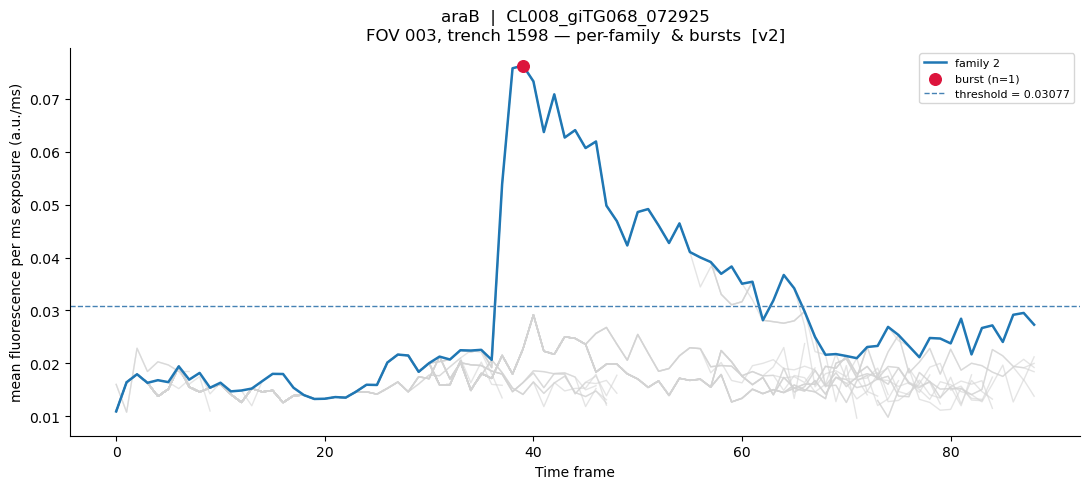

In [238]:
# Case 1 -- a clean single burst. Flat at ~0.021 a.u./ms through frame 36, then
# 0.0192 -> 0.0539 -> 0.0758, peaking at 0.0763 (frame 39) against a threshold of 0.0308, then
# decaying slowly over 30 frames. Episode merge gives ONE dot, at frame 39.
BURST_EXP, BURST_FOV, BURST_PEAK = 'CL008_giTG068_072925', '003', '1598'
print(select_trench(bursts, BURST_EXP, BURST_FOV, BURST_PEAK)
      [['gene', 'track_id', 'time_frame', 'fluor', 'threshold']].round(4).to_string(index=False))
plot_bursts_for_trench(all_data, bursts, BURST_EXP, BURST_FOV, BURST_PEAK,
                       save=SAVE_FIGS);

### Figure 8 — two bursts at once (the v2 case)

The trench that motivated v2. On the per-family view the two bursts are two separate humps; on a
single trench-max envelope the second sits inside the first's shoulder with a prominence of
0.0031 a.u./ms against a required 0.0175, and is thrown away.

Note family 31's hump crosses the threshold but carries **no** marker: it merged into family 30's
event, 1.41 cell lengths away and one frame earlier. That is the merge working, not a miss — the
audit table above records it.

gene  track_id  lineage_family  time_frame  fluor  threshold
lacZ         8               7          12 0.0634     0.0332
lacZ        50              40          52 0.0417     0.0332
lacZ        44              30          54 0.0384     0.0332
lacZ        89              89          80 0.0381     0.0332

in frames 50-59: 2 bursts (v1 found 1 here)
/Users/adrianjuarez/Documents/Covert_lab/repos/mother_machine_cell_tracker/notebooks/figures/summary_082026/bursts_v2_DUMM_giTG059_060_061125_008_1488.svg


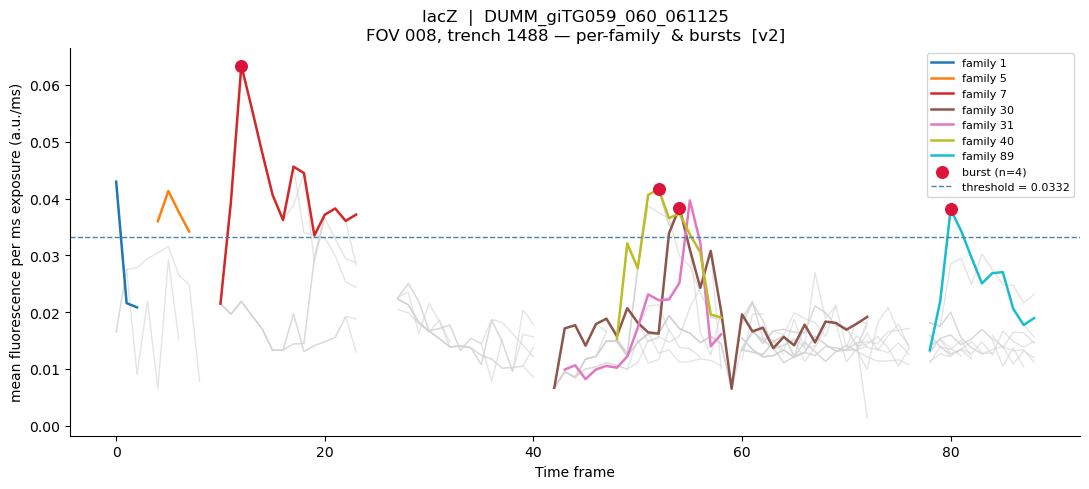

In [239]:
# Case 2 -- TWO concurrent bursts, the case v1 could not see (it reported one).
#   burst A: track 41 rises at frames 49-50, divides at 51 into 49 + 50, both daughters
#            carrying the protein. Peak 0.0417 a.u./ms at frame 52, counted ONCE -- inheritance
#            is not a new burst.
#   burst B: tracks 44 and 45, two adjacent cells 1.41 cell lengths apart, merged to one
#            event reported at its onset, frame 54.
# On the per-family view these are two separate humps; on a single trench-max envelope burst B
# sits inside burst A's shoulder with a prominence of 0.78 and is rejected.
CONC_EXP, CONC_FOV, CONC_PEAK = 'DUMM_giTG059_060_061125', '008', '1488'
_c = select_trench(bursts, CONC_EXP, CONC_FOV, CONC_PEAK)
print(_c[['gene', 'track_id', 'lineage_family', 'time_frame', 'fluor', 'threshold']]
      .sort_values('time_frame').round(4).to_string(index=False))
print(f'\nin frames 50-59: {len(_c[_c.time_frame.between(50, 59)])} bursts '
      f'(v1 found 1 here)')
plot_bursts_for_trench(all_data, bursts, CONC_EXP, CONC_FOV, CONC_PEAK,
                       save=SAVE_FIGS);

### Is the answer tuned? — k sensitivity

`k` sets both the height threshold and the required prominence, so it is the one knob that
could manufacture the result. Re-running detection across it shows it cannot: the constitutive
genes sit at the bottom everywhere and the reference burst survives everywhere. `k` trades
sensitivity against noise; it does not decide the ranking.

mazF is 10th of 10 at every `k` from 2 to 6, hupA 8th–9th, chpS 5th–7th. With the failed runs out
of the frame the low-`k` soft spot the v2 changelog entry warns about is gone: chpS sits at 6th
at `k = 2.0`, not 3rd. The concurrent pair in trench 1488 survives to `k = 5.0` and disappears at
`k = 6.0`, where both peaks fall under the height bar.

In [240]:
# Is the ranking a property of the data or of k? Re-run the whole detection across k and check
# where the three constitutive genes land. If they only sink at the tuned value, the result is
# an artefact of tuning; they should sink everywhere.
rows = []
for k in (2.0, 3.0, 4.0, 5.0, 6.0):
    bd = {**BURST_DEF, 'k': k}
    b, _ = run_burst_detection(all_data, bd)
    rate = (100 * b.groupby('gene', observed=True).size()
            / burst_cells.groupby('gene', observed=True).size()).fillna(0)
    rate = rate.sort_values(ascending=False)
    rank = {g: i + 1 for i, g in enumerate(rate.index)}
    rows.append({
        'k': k, 'n_bursts': len(b),
        **{f'rank_{g}': rank.get(g, len(rate)) for g in sorted(CONSTITUTIVE_GENES)},
        'top3': ', '.join(rate.index[:3]),
        'ref_burst': not select_trench(b, BURST_EXP, BURST_FOV, BURST_PEAK).empty,
        'concurrent_pair': len(select_trench(b, CONC_EXP, CONC_FOV, CONC_PEAK)
                               .query('50 <= time_frame <= 59')),
    })

print(f'k sensitivity — rank of each constitutive gene among {all_data.gene.nunique()} genes '
      f'(higher rank number = fewer bursts = expected)\n')
print(pd.DataFrame(rows).to_string(index=False))
print('\nmazF stays last at every k and the reference burst survives everywhere, so k trades '
      'sensitivity for noise rather than deciding the answer. With the failed runs excluded at '
      'load, chpS no longer climbs into the top 3 at low k -- the v2 changelog caveat about that '
      'was measured on the unfiltered frame.')

k sensitivity — rank of each constitutive gene among 10 genes (higher rank number = fewer bursts = expected)

  k  n_bursts  rank_chpS  rank_hupA  rank_mazF             top3  ref_burst  concurrent_pair
2.0       381          6          8         10 murQ, gfcE, lacZ       True                2
3.0       184          5          8         10 lacZ, murQ, gfcE       True                2
4.0        94          7          9         10 lacZ, araB, gfcE       True                2
5.0        58          7          9         10 lacZ, araB, alkA       True                2
6.0        27          7          9         10 lacZ, araB, murQ       True                0

mazF stays last at every k and the reference burst survives everywhere, so k trades sensitivity for noise rather than deciding the answer. With the failed runs excluded at load, chpS no longer climbs into the top 3 at low k -- the v2 changelog caveat about that was measured on the unfiltered frame.


---
# 8 — Ranking the genes: how "subgen" is each one?

Two bar plots of the same bursts against two different denominators. Sorted descending, so the ranking reads left to right.

- **per good cell pair** — normalises by sampling *opportunity*: how many chances to observe a
  burst did we actually have. The denominator is `within_track` pairs with `is_jump` False: one
  consecutive-frame observation per cell per frame transition, tracking-error pairs removed.
- **per unique cell** — normalises by sampling *breadth*: how many distinct cells were watched.

**Why `within_track` only.** The notebook's `good` object also carries division pairs, which
link a parent's last frame to a daughter's first — a different kind of observation from a
frame-to-frame step. Including them inflates the denominator ~13% and lowers every rate
proportionally, so the filter is spelled out explicitly below rather than reusing `good`.

**Read the whiskers, not the bar order.** With 0–35 bursts per gene these are small-count rates.
The whiskers are exact Poisson (Garwood) 95% intervals, and they overlap for most pairs of genes:

- **Stable:** lacZ is top and baeS / hupA / mazF are bottom under *both* denominators.
- **Not resolved:** lacZ vs araB overlap (2.37–4.72 vs 1.19–2.87), so even the top pair is not a
  separation the counts support. Only lacZ against baeS/chpS/hupA/mazF clears.
- **Denominator-dependent:** alkA, gfcE and gldA hold ranks 3/4/5 in *different orders* depending
  on which denominator you use. Their three rates are within 0.15 of each other.

A zero-height bar still carries a whisker, because 0 observed bursts is not evidence of a zero
rate — mazF's upper bound is 1.39 per 1000 pairs, which is above chpS's point estimate.

In [241]:
def _poisson_bounds(n, denom, scale):
    """Numeric exact (Garwood) Poisson 95% bounds for a rate of `n` per `denom`, times `scale`.

    Numeric sibling of _poisson_ci above, which formats to a display string and so cannot feed
    a matplotlib `yerr`. Same interval: the lower limit is 0 when n == 0 (you cannot bound a
    zero count away from zero), the upper limit uses n+1 so it stays finite there.
    """
    n = np.asarray(n, dtype=float)
    denom = np.asarray(denom, dtype=float)
    lo = np.where(n > 0, chi2.ppf(0.025, 2 * np.maximum(n, 1)) / 2, 0.0)
    hi = chi2.ppf(0.975, 2 * (n + 1)) / 2
    return scale * lo / denom, scale * hi / denom


def burst_rate_table(bursts, cells, pairs):
    """Burst counts and both normalised rates per gene, with numeric Poisson 95% bounds.

    The pair denominator is spelled out here rather than reusing `good`: that also includes
    division pairs, and quietly swapping one for the other moves every rate by ~13%.
    """
    good_wt = pairs[(~pairs['is_jump']) & (pairs['pair_type'] == 'within_track')]
    uniq = cells.drop_duplicates(CELL_KEY)

    t = pd.DataFrame({
        'n_bursts':     bursts.groupby('gene', observed=True).size(),
        'n_good_pairs': good_wt.groupby('gene', observed=True).size(),
        'n_cells':      uniq.groupby('gene', observed=True).size(),
    }).fillna(0).astype(int)

    t['per_1k_good_pairs'] = 1000 * t['n_bursts'] / t['n_good_pairs']
    t['gp_lo'], t['gp_hi'] = _poisson_bounds(t['n_bursts'], t['n_good_pairs'], 1000)
    t['per_100_cells'] = 100 * t['n_bursts'] / t['n_cells']
    t['uc_lo'], t['uc_hi'] = _poisson_bounds(t['n_bursts'], t['n_cells'], 100)
    return t


def plot_burst_rank_bars(t, value_col, lo_col, hi_col, ylabel, title, name,
                         denom_col=None, save=None):
    """Genes ranked by a burst rate, with exact Poisson 95% whiskers.

    Geometry and chrome follow plot_fluor_bars: one colour for the single series (bar length
    already carries the value, so hue would be redundant and no legend is needed), hairline
    chrome, no gridlines. Linear y-axis -- these rates span only ~13x, so a log axis would
    obscure rather than reveal.

    Sorted descending by `value_col`, so each figure is a ranking in its own right. The two
    denominators do NOT produce the same order in the middle of the field; sorting each by its
    own metric makes that visible instead of hiding it behind a shared order.
    """
    t = t.sort_values(value_col, ascending=False)
    genes = list(t.index)
    x = np.arange(len(genes))
    val = t[value_col].to_numpy()
    # yerr is expressed as distance from the bar top, not as absolute bounds.
    err = np.vstack([val - t[lo_col].to_numpy(), t[hi_col].to_numpy() - val])

    fig, ax = plt.subplots(figsize=(1.05 * len(genes) + 4, 5.5))
    ax.bar(x, val, width=0.55, color=C_MAIN, alpha=0.85, zorder=2)
    # A zero-height bar still gets a whisker: 0 observed bursts is not evidence of a zero rate.
    ax.errorbar(x, val, yerr=err, fmt='none', ecolor='0.35', elinewidth=1.1,
                capsize=3, capthick=1.1, zorder=3)

    # n/N above each whisker. The numerator and denominator are load-bearing here -- a rate of
    # 0.67 from 1/1,490 is a far weaker claim than 3.40 from 35/10,305.
    top = float(t[hi_col].max())
    for xi, (n, d, hi) in enumerate(zip(t['n_bursts'], t[denom_col or 'n_good_pairs'],
                                        t[hi_col])):
        ax.text(xi, hi + 0.03 * top, f'{n}/{d:,}', ha='center', va='bottom', fontsize=7.5,
                color='0.35')

    ax.set_ylim(0, top * 1.16)          # headroom so the n/N labels are never clipped
    ax.set_xticks(x, genes)
    ax.set_ylabel(ylabel)
    ax.set_title(f'{title}\n{LABEL}  |  bars = point estimate, '
                 f'labels = bursts/denominator', loc='left', fontsize=10)
    _style(ax)
    fig.tight_layout()
    print(_save(fig, name, save=SAVE_FIGS if save is None else save))
    return fig

burst rate per gene  [all genes | 3 failed runs excluded]  (v2, k=4.0)

      n_bursts  n_good_pairs  n_cells  per_1k_good_pairs ci_per_1k_pairs  rank_by_pair  per_100_cells ci_per_100_cells  rank_by_cell
gene                                                                                                                                
lacZ        35         10305     1483              3.396       2.37-4.72             1          2.360        1.64-3.28             1
araB        22         11598     2240              1.897       1.19-2.87             2          0.982        0.62-1.49             2
alkA         9          5839     1016              1.541       0.70-2.93             3          0.886        0.41-1.68             5
gfcE        14          9770     1537              1.433       0.78-2.40             4          0.911        0.50-1.53             3
gldA         7          5012      781              1.397       0.56-2.88             5          0.896        0.36-1.85            

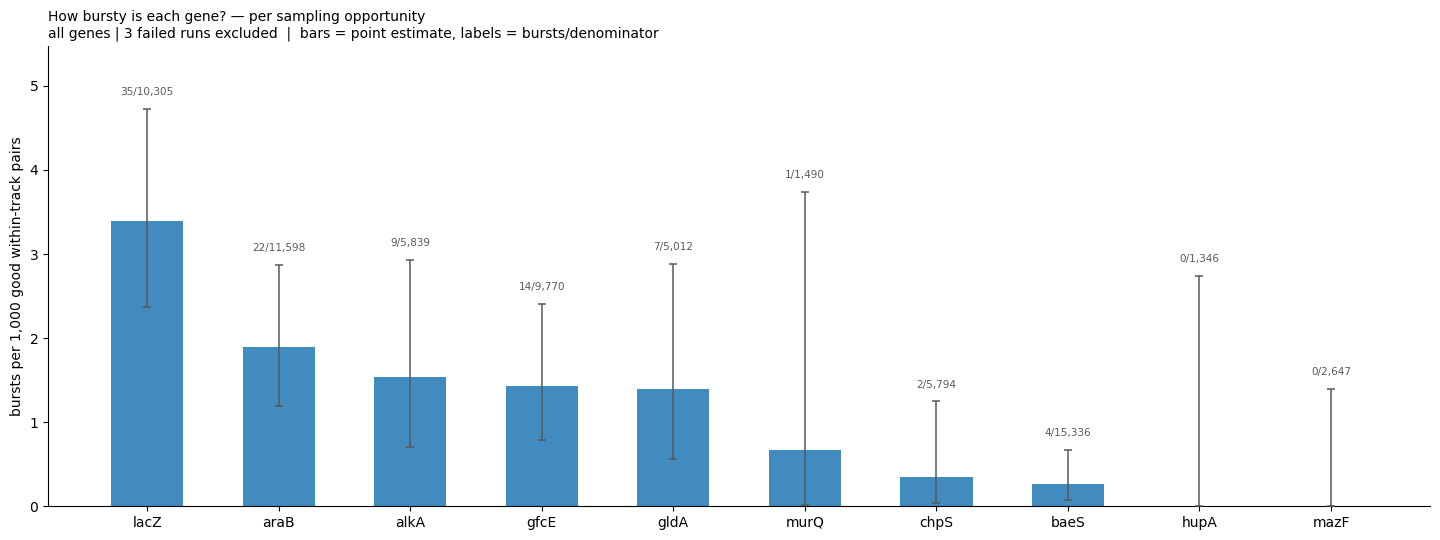

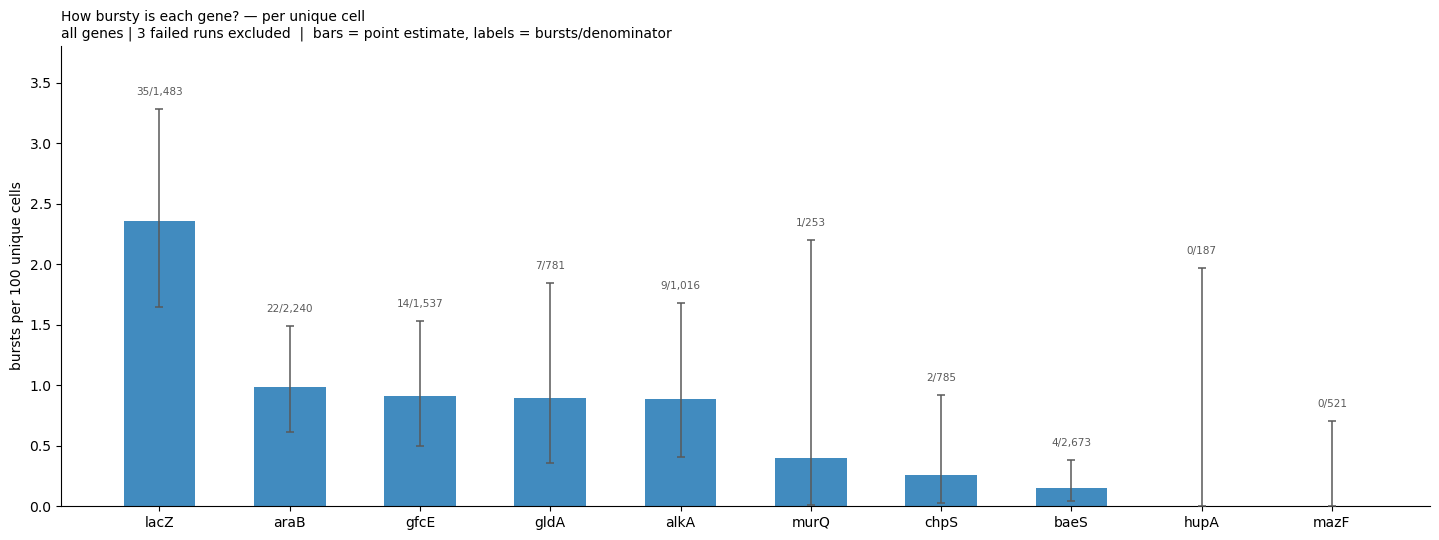

In [242]:
burst_rates = burst_rate_table(bursts, all_data, pairs_all)

_show = burst_rates.copy()
_show['ci_per_1k_pairs'] = [f'{a:.2f}-{b:.2f}' for a, b in zip(_show.gp_lo, _show.gp_hi)]
_show['ci_per_100_cells'] = [f'{a:.2f}-{b:.2f}' for a, b in zip(_show.uc_lo, _show.uc_hi)]
_show['rank_by_pair'] = _show.per_1k_good_pairs.rank(ascending=False, method='min').astype(int)
_show['rank_by_cell'] = _show.per_100_cells.rank(ascending=False, method='min').astype(int)
print(f'burst rate per gene  [{LABEL}]  '
      f'({BURST_DEF["version"]}, k={BURST_DEF["k"]})\n')
print(_show[['n_bursts', 'n_good_pairs', 'n_cells',
             'per_1k_good_pairs', 'ci_per_1k_pairs', 'rank_by_pair',
             'per_100_cells', 'ci_per_100_cells', 'rank_by_cell']]
      .sort_values('per_1k_good_pairs', ascending=False).round(3).to_string())

_moved = _show[_show.rank_by_pair != _show.rank_by_cell]
if len(_moved):
    print(f'\nrank differs between the two denominators for: '
          f'{", ".join(sorted(_moved.index))} -- their rates sit within '
          f'{_moved.per_1k_good_pairs.max() - _moved.per_1k_good_pairs.min():.2f} '
          f'per 1000 pairs of each other, so the order there is not meaningful.')

plot_burst_rank_bars(
    burst_rates, 'per_1k_good_pairs', 'gp_lo', 'gp_hi',
    ylabel='bursts per 1,000 good within-track pairs',
    title='How bursty is each gene? — per sampling opportunity',
    name=f'burst_rate_per_good_pair{SUFFIX}',
    denom_col='n_good_pairs')

plot_burst_rank_bars(
    burst_rates, 'per_100_cells', 'uc_lo', 'uc_hi',
    ylabel='bursts per 100 unique cells',
    title='How bursty is each gene? — per unique cell',
    name=f'burst_rate_per_cell{SUFFIX}',
    denom_col='n_cells');

---
# 9 — v3, and a burst CSV the kymograph viewer can outline

Two additions:

1. **v3**, which subdivides a lineage family that is spatially discontiguous.
2. **`data/bursts_082026.csv`** with boolean `burst_v1/v2/v3` columns, for
   `generate_kymograph_viewer.py --burst-csv` to draw a real outline — a contour cut from
   `ctc_masks` — around the cell that burst, so bursts can be confirmed by eye.

### Headline result on v3: it is a no-op, measured

**v3 finds exactly the same 89 bursts as v2** on this dataset: `v3 \ v2 = 0` and `v2 \ v3 = 0`,
and every per-gene rate is identical. The toggle below is real, working machinery, but selecting
v3 currently draws the same outlines as v2. Recorded rather than hidden, because the reason is
informative.

**Why.** v2's blind spot is real — 32 co-bright, spatially-separated cell pairs sit inside a single
lineage family, across 8 of 292 trenches, and 20% of trenches are one family where v2 degenerates
to v1. But every way of splitting on position runs into the same wall:

| linking rule for the spatial sub-groups | result |
|---|---|
| by cluster **mean centroid**, ≤1 cell length | **shatters** the signal — median envelope 2 frames, 52% of units under 3 frames and therefore unusable by `find_peaks`; the reference burst cell alone passed through 5 groups. Loses bursts (56). |
| by **shared cell identity** (same `track_id`, or parent→daughter) | coherent again (median envelope 16 frames vs v2's 17), but identity **re-joins whatever position split** — cells in a trench are physically contiguous, so the partition collapses back to v2. Result: 89, a no-op. |
| by **fluorescence runs** (split at a dark cell rather than a geometric gap) | 80 bursts — *worse* than v2, and 009/551 still gives 2. |

The two failure modes trade off exactly against each other, so **the v2 partition is at a local
optimum for this data**. Separating same-family concurrency would need a genuinely different
signal — per-cell deconvolution, or segmentation good enough to trust cell identity without the
envelope — not another partition of the same envelope.

### An input filter, applied before all three definitions

Sorted burst-cell areas are `[1, 1, 1, 2, 2, 117, 131, 131, 135, 142, …]`. Only **0.11%** of all
cell-frames are ≤5 px², yet **5 of 95** v2 bursts land on them — a 48× enrichment. One has
`axis_major_length = 0` and lives for a single frame. On a 1-pixel mask `intensity_mean_fluor` is a
single raw pixel with no averaging, which is exactly how a false peak clears a threshold built from
properly-averaged cells.

Framed as a **data-quality filter on the input table**, not part of any version's rule — the same
status as the failed-run exclusion applied at load. That is what lets it apply to all three
definitions without editing the frozen v1 and v2 rules. It removes exactly those 5 bursts.

**The floor is relative, not absolute** — 5% of each experiment's own median cell area. An absolute
px² threshold is not portable across this set, because one acquisition
(`DUMM_giTG66_Glucose_012325`) was recorded at roughly **one third the linear pixel scale** of every
other: its cells, cell widths *and its trenches* are all ~0.34× the usual size, so its median cell
area is 33 px² against 263 px² elsewhere. Its masks are sound — `area / (L·W)` = 0.783 against 0.767
elsewhere, both matching π/4 for a clean ellipse — they are simply recorded on bigger pixels, and
nothing in the pipeline records pixel size. Measured, an absolute 50 px² floor dropped **905**
cell-frames of which **749 were that run's perfectly good cells**; the relative floor drops 121, of
which **1**. It is the same argument `delta_y_cell_lengths` already makes: with no µm/px anywhere in
the repo, a ratio is the only threshold that ports across acquisitions.

The floor still filters the cell table, so it also reshapes the envelopes; that is intended. The
masks it was written for are the ≤5 px² ones — 100 in the whole dataset, 98 of them outside the
coarse-pixel run.

### Why linking is only ever frame-to-frame

Cells drift along the trench (median |Δy| **6.38 px/frame**, 99th pct 0.82 cell lengths) and cross
the 322 px trench in ~50 frames, so the same `y` holds a different cell later: **all 10**
same-trench burst pairs within 1.5 cell lengths in `y` are 9–42 frames apart and **none** are
concurrent. Position alone would fuse every one. All linking here is between consecutive frames
only — a frame gap deliberately breaks the chain.

In [243]:
# --- input filter: drop degenerate masks before ANY definition runs -------------------
# Not part of a version's rule -- same status as the failed-run exclusion applied at load.
#
# RELATIVE, not an absolute px^2 threshold. DUMM_giTG66_Glucose_012325 was recorded at ~1/3 the
# linear pixel scale of every other run (cells, widths AND trenches all ~0.34x; median cell area
# 33 px^2 against 263 px^2 elsewhere), and its masks are geometrically sound -- area/(L*W) = 0.783
# vs 0.767, both matching pi/4 for an ellipse. An absolute 50 px^2 floor deleted 749 of its 844
# good cell-frames. Nothing in the pipeline records pixel size, so the threshold has to be
# scale-free, exactly as delta_y_cell_lengths is.
MIN_CELL_AREA_FRAC = 0.05          # 5% of the experiment's own median cell area

# Medians come from all_data, never from a scoped frame, so the floor does not move when CONFIG
# is narrowed to a subset of experiments or FOVs.
EXP_MEDIAN_AREA = all_data.groupby('experiment_name')['area'].median()


def drop_degenerate_masks(df, frac=MIN_CELL_AREA_FRAC, verbose=True):
    """Drop cell-frames whose mask is below `frac` of their experiment's median cell area."""
    floor = frac * df['experiment_name'].map(EXP_MEDIAN_AREA)
    assert floor.notna().all(), 'an experiment is missing from EXP_MEDIAN_AREA'
    keep = df['area'] >= floor
    if verbose:
        print(f'area floor {frac:.0%} of each experiment\'s own median: '
              f'{len(df):,} -> {int(keep.sum()):,} cell-frames '
              f'({int((~keep).sum()):,} dropped, {100 * (~keep).mean():.2f}%)')
    return df[keep].copy()


area_data = drop_degenerate_masks(all_data)

# Per-experiment floors, so the scale difference is on the page rather than buried in a constant.
_fl = (EXP_MEDIAN_AREA * MIN_CELL_AREA_FRAC).rename('floor_px2').to_frame()
_fl['median_area_px2'] = EXP_MEDIAN_AREA
_fl['dropped'] = (all_data.assign(_lo=all_data['experiment_name'].map(EXP_MEDIAN_AREA)
                                  * MIN_CELL_AREA_FRAC)
                  .pipe(lambda d: d[d.area < d._lo]).groupby('experiment_name').size())
_fl['dropped'] = _fl['dropped'].fillna(0).astype(int)
print()
print(_fl.sort_values('median_area_px2').round(1).to_string())


BURST_DEF_V3 = {
    **BURST_DEF_V2,
    'version': 'v3',
    'signal': 'per-lineage-family x spatial-cluster max envelope',
    'split_gap_cell_lengths': 1.5,   # cut a family where its cells are this far apart in y
    'link_gap_cell_lengths': 1.0,    # max per-frame drift when linking clusters across frames
}


def _spatial_clusters_one_frame(sub, split_gap):
    """Cluster one family's cells at one frame by gaps along y. Returns cluster index per row.

    Sorted by centroid_y; a new cluster starts wherever the gap to the previous cell exceeds
    `split_gap` cell lengths. In trench 1488 the separator is a genuinely dark cell sitting
    between the two bright regions, so the gap that splits them is already in the data.
    """
    order = np.argsort(sub['centroid_y'].to_numpy())
    y = sub['centroid_y'].to_numpy()[order]
    L = np.nanmean(sub['axis_major_length'].to_numpy())
    L = L if L > 1 else 1.0
    gaps = np.diff(y) / L
    cl = np.concatenate([[0], np.cumsum(gaps > split_gap)])
    out = np.empty(len(sub), dtype=int)
    out[order] = cl
    return out


def add_spatial_subgroup(df, bdef=BURST_DEF_V3):
    """Add `spatial_group`: a lineage family subdivided by position, coherent through time.

    Per (trench, family): cluster by y-gap within each frame, then join clusters in CONSECUTIVE
    frames that SHARE A CELL -- same track_id, or a parent/daughter pair. Union-find over
    (frame, cluster) nodes gives groups that persist as the cells drift.

    Linking on cell identity, not on cluster position. An earlier version matched cluster mean
    centroids within 1 cell length and fragmented badly: clusters split and merge as cells
    divide, so the MEAN jumps far more than any individual cell does. That shattered the
    reference burst into 5 groups and left 52% of units under 3 frames (unusable by find_peaks).
    Shared identity is invariant to that.

    Consecutive-frames-only is the safeguard against fusing two bursts that occupy the same y at
    different times: there is no chain of links between them because the region went dark.
    """
    split_gap = bdef['split_gap_cell_lengths']
    df = df.sort_values(KYMO_KEY + ['lineage_family', 'time_frame']).reset_index(drop=True)
    grp = np.empty(len(df), dtype=object)

    for (exp, fov, tr, fam), g in df.groupby(KYMO_KEY + ['lineage_family'], sort=False):
        node_of_row, members, parents_of = {}, {}, {}
        for fr, gf in g.groupby('time_frame', sort=True):
            cl = _spatial_clusters_one_frame(gf, split_gap)
            for idx, c in zip(gf.index, cl):
                node_of_row[idx] = (fr, int(c))
            tids = gf['track_id'].to_numpy()
            pars = gf['parent_track_id'].to_numpy()
            for c in np.unique(cl):
                members[(fr, int(c))] = set(tids[cl == c].tolist())
                parents_of[(fr, int(c))] = {int(p) for p in pars[cl == c] if pd.notna(p)}

        parent = {n: n for n in members}
        def find(a):
            while parent[a] != a:
                parent[a] = parent[parent[a]]; a = parent[a]
            return a
        def union(a, b):
            ra, rb = find(a), find(b)
            if ra != rb:
                parent[max(ra, rb)] = min(ra, rb)

        frames = sorted({f for f, _ in members})
        by_frame = {f: [n for n in members if n[0] == f] for f in frames}
        for f0, f1 in zip(frames, frames[1:]):
            if f1 - f0 != 1:
                continue                       # a frame gap breaks the chain, by design
            for a in by_frame[f0]:
                for b in by_frame[f1]:
                    # same cell carried over, or a daughter of a cell in `a`
                    if members[a] & members[b] or members[a] & parents_of[b]:
                        union(a, b)

        for idx in g.index:
            r = find(node_of_row[idx])
            grp[idx] = f'{fam}.{r[0]}_{r[1]}'

    df['spatial_group'] = grp
    return df


def run_burst_detection_any(df, bdef):
    """Detect bursts under v1, v2 or v3, returning (bursts, merge_audit).

    Dispatches on the partition the definition asks for -- trench (v1), lineage family (v2), or
    family x spatial cluster (v3) -- by temporarily encoding the partition into `trench_id`, which
    is what detect_bursts groups by. `trench_id` is restored before returning, so select_trench
    keeps working on the result.
    """
    assert tuple(bdef['baseline_keys']) == ('gene', 'experiment_name'), 'baseline_keys not honoured'
    sig = bdef['signal']

    if sig.startswith('per-trench'):
        b = detect_bursts(df, k=bdef['k'], window=bdef['window'],
                          min_prominence=bdef['min_prominence'], fluor_col=bdef['fluor_col'],
                          constitutive_genes=set(bdef['constitutive_genes']))
        b['def_version'] = bdef['version']
        b['lineage_family'] = np.nan
        return b, pd.DataFrame()

    cells = add_lineage_family(df)
    part = 'lineage_family'
    if sig.startswith('per-lineage-family x spatial'):
        cells = add_spatial_subgroup(cells, bdef)
        part = 'spatial_group'

    keyed = cells.copy()
    keyed['trench_id'] = keyed['trench_id'].astype(str) + FAMILY_SEP + keyed[part].astype(str)
    b = detect_bursts(keyed, k=bdef['k'], window=bdef['window'],
                      min_prominence=bdef['min_prominence'], fluor_col=bdef['fluor_col'],
                      constitutive_genes=set(bdef['constitutive_genes']))
    if b.empty:
        b['def_version'] = bdef['version']; return b, pd.DataFrame()

    split = b['trench_id'].str.rsplit(FAMILY_SEP, n=1, expand=True)
    b['trench_id'] = split[0]
    b['partition'] = split[1]
    b['lineage_family'] = b['partition'].astype(str).str.split('.').str[0].astype(int)

    pos = KYMO_KEY + ['track_id', 'time_frame']
    b = b.merge(cells[pos + ['centroid_y', 'axis_major_length']], on=pos, how='left')
    assert b['centroid_y'].notna().all(), 'a burst peak failed to match a cell row'
    b, audit = merge_concurrent_bursts(b, bdef)
    b['def_version'] = bdef['version']
    return b.reset_index(drop=True), audit

area floor 5% of each experiment's own median: 81,920 -> 81,799 cell-frames (121 dropped, 0.15%)

                                   floor_px2  median_area_px2  dropped
experiment_name                                                       
DUMM_giTG66_Glucose_012325               1.6             33.0        1
DUMM_giTG062_064_121325                  9.9            198.0        4
DUMM_CL008_080825                       10.4            208.0        3
DUMM_giTG62_Glucose_012925              10.5            209.0       11
DUMM_giTG060_064_121425                 11.3            226.0       14
DUMM_gitg068_baeS_100225                11.5            230.0       24
DUMM_giTG63_giTG67_Glucose_121724       11.6            233.0        1
DUMM_giTG69_Glucose_013025              12.1            242.0        0
DUMM_giTG066_063_120925                 12.4            247.0        0
DUMM_giTG059_noKan_Glucose_031125       12.4            247.0        6
DUMM_mazF_murQ_121625                   13.2      

In [244]:
BURST_DEFS = {'v1': BURST_DEF_V1, 'v2': BURST_DEF_V2, 'v3': BURST_DEF_V3}
burst_sets, burst_audits = {}, {}
for _v, _bd in BURST_DEFS.items():
    burst_sets[_v], burst_audits[_v] = run_burst_detection_any(area_data, _bd)
    print(f'{_v}: {len(burst_sets[_v]):3d} bursts   [{_bd["signal"]}]')

PEAK_KEY = KYMO_KEY + ['track_id', 'time_frame']
_as_set = lambda b: set(map(tuple, b[PEAK_KEY].astype({'track_id': int, 'time_frame': int}).values))
_s1, _s2, _s3 = (_as_set(burst_sets[v]) for v in ('v1', 'v2', 'v3'))

print(f'\nv1 n v2 n v3 = {len(_s1 & _s2 & _s3)} | union = {len(_s1 | _s2 | _s3)}')
print(f'v2 \\ v1 = {len(_s2 - _s1):2d}   (concurrency v1 masked)')
print(f'v3 \\ v2 = {len(_s3 - _s2):2d}   (concurrency v2 masked inside one family)')
print(f'v2 \\ v3 = {len(_s2 - _s3):2d}')
if _s3 == _s2:
    print('\n  NOTE: v3 == v2 exactly on this dataset. Identity-based linking re-joins whatever the'
          '\n  spatial split separates, because cells in a trench are physically contiguous. See the'
          '\n  markdown above for the three partition rules tried and why each fails.')

# the araB trench where the whole trench is ONE lineage family -- v2's blind spot
for _v in ('v1', 'v2', 'v3'):
    _n = len(select_trench(burst_sets[_v], 'CL008_giTG068_072925', '009', '551'))
    print(f'  araB 009/551 (single-family trench): {_v} finds {_n}')

# per-gene rates under all three, and the constitutive control
_v3_rate_rows = []
for _v in ('v1', 'v2', 'v3'):
    _r = (100 * burst_sets[_v].groupby('gene', observed=True).size()
          / area_data.drop_duplicates(CELL_KEY).groupby('gene', observed=True).size()).fillna(0)
    _v3_rate_rows.append(_r.rename(_v))
_v3_cmp = pd.concat(_v3_rate_rows, axis=1).round(2)
_v3_cmp['constitutive'] = _v3_cmp.index.isin(CONSTITUTIVE_GENES)
print(f'\nbursts per 100 unique cells, by definition  '
      f'[area floor {MIN_CELL_AREA_FRAC:.0%} of own median, failed runs excluded]\n')
print(_v3_cmp.sort_values('v3', ascending=False).to_string())

v1:  73 bursts   [per-trench max envelope]
v2:  89 bursts   [per-lineage-family max envelope]
v3:  89 bursts   [per-lineage-family x spatial-cluster max envelope]

v1 n v2 n v3 = 71 | union = 91
v2 \ v1 = 18   (concurrency v1 masked)
v3 \ v2 =  0   (concurrency v2 masked inside one family)
v2 \ v3 =  0

  NOTE: v3 == v2 exactly on this dataset. Identity-based linking re-joins whatever the
  spatial split separates, because cells in a trench are physically contiguous. See the
  markdown above for the three partition rules tried and why each fails.
  araB 009/551 (single-family trench): v1 finds 2
  araB 009/551 (single-family trench): v2 finds 2
  araB 009/551 (single-family trench): v3 finds 2

bursts per 100 unique cells, by definition  [area floor 5% of own median, failed runs excluded]

        v1    v2    v3  constitutive
gene                                
lacZ  1.98  2.26  2.26         False
gfcE  0.66  0.92  0.92         False
gldA  0.39  0.90  0.90         False
alkA  0.69  0.

In [245]:
BURST_CSV = f'{REPO_ROOT}/data/bursts_082026.csv'

def build_burst_csv(burst_sets, cells, path=BURST_CSV):
    """One row per burst PEAK across the union of all definitions, with a boolean per definition.

    The viewer joins on (experiment_name, FOV, trench_id, track_id, time_frame) and cuts the
    outline contour from ctc_masks[time_frame] == track_id, so those five columns are the
    load-bearing ones; the geometry columns let the CSV be validated without opening a mask.

    `time_frame` is the 0-based index within the trimmed stack, i.e. the kymograph COLUMN index.
    It must NOT be offset by the time_dict `start` -- the viewer uses start only for printed tick
    labels, so adding it would shift every outline sideways.
    """
    frames = []
    for v, b in burst_sets.items():
        f = b[KYMO_KEY + ['track_id', 'time_frame']].astype({'track_id': int, 'time_frame': int})
        f = f.assign(**{f'burst_{v}': True})
        frames.append(f)
    out = frames[0]
    for f in frames[1:]:
        out = out.merge(f, on=KYMO_KEY + ['track_id', 'time_frame'], how='outer')
    for v in burst_sets:
        out[f'burst_{v}'] = out[f'burst_{v}'].fillna(False).astype(bool)

    # Context + geometry. `centroid_x` and `axis_minor_length` are NOT in SUMMARY_COLS, so
    # they are pulled straight from the CSV for just these few rows rather than widening the
    # section-1 loader -- the viewer needs centroid_x (already kymograph-space) to sanity-check
    # the outline placement, so silently dropping it would be worse than a targeted re-read.
    GEO = ['gene', 'centroid_x', 'centroid_y', 'axis_major_length', 'axis_minor_length', 'area']
    key = KYMO_KEY + ['track_id', 'time_frame']
    have = [c for c in GEO if c in cells.columns]
    out = out.merge(cells[key + have], on=key, how='left')

    missing = [c for c in GEO if c not in have]
    if missing:
        extra = pd.read_csv(
            CSV_PATH, usecols=lambda c: c in set(key + missing),
            dtype={'FOV': str, 'trench_id': str, 'experiment_name': str, 'gene': str})
        extra['FOV'] = extra['FOV'].str.zfill(3)
        out = out.merge(extra, on=key, how='left')
        print(f'pulled {missing} from {os.path.basename(CSV_PATH)} for the export')
    have = GEO

    # fluor / threshold from whichever definition detected the peak (v3 preferred, then v2, v1)
    for v in ('v1', 'v2', 'v3'):
        src = burst_sets[v][KYMO_KEY + ['track_id', 'time_frame', 'fluor', 'threshold']].astype(
            {'track_id': int, 'time_frame': int})
        out = out.merge(src, on=KYMO_KEY + ['track_id', 'time_frame'], how='left',
                        suffixes=('', f'_{v}'))
        if v != 'v1':
            out['fluor'] = out['fluor'].fillna(out.pop(f'fluor_{v}'))
            out['threshold'] = out['threshold'].fillna(out.pop(f'threshold_{v}'))

    assert not out['trench_id'].astype(str).str.contains(FAMILY_SEP).any(), (
        f'a partition id leaked into trench_id via {FAMILY_SEP!r}; the viewer would match no card')
    assert out['FOV'].astype(str).str.len().eq(3).all(), 'FOV must stay zero-padded to 3 chars'
    for c in ('centroid_x', 'centroid_y', 'axis_major_length', 'area'):
        assert out[c].notna().all(), f'a peak row has no {c}'
    assert len(out) == len(out.drop_duplicates(KYMO_KEY + ['track_id', 'time_frame'])), 'dup rows'

    cols = (KYMO_KEY + ['track_id', 'time_frame'] + [f'burst_{v}' for v in burst_sets]
            + have + ['fluor', 'threshold'])
    out = out[cols].sort_values(KYMO_KEY + ['time_frame', 'track_id']).reset_index(drop=True)
    out.to_csv(path, index=False)
    return out


burst_csv = build_burst_csv(burst_sets, area_data)
print(f'wrote {BURST_CSV}  ({len(burst_csv)} rows)\n')
print('rows per definition: ' + ' | '.join(
    f'{v}={int(burst_csv[f"burst_{v}"].sum())}' for v in burst_sets))
print(f'trenches with at least one burst: {len(burst_csv[KYMO_KEY].drop_duplicates())}\n')
print(burst_csv.head(10).to_string(index=False))
print('\nrender with:')
print(f'  python generate_kymograph_viewer.py --burst-csv data/bursts_082026.csv \\')
print(f'      --output data/kymograph_viewer_bursts.html')

/var/folders/z0/t_qxft797x97j_j_sdkjdv740000gn/T/ipykernel_22380/632511400.py:23: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  out[f'burst_{v}'] = out[f'burst_{v}'].fillna(False).astype(bool)
/var/folders/z0/t_qxft797x97j_j_sdkjdv740000gn/T/ipykernel_22380/632511400.py:23: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  out[f'burst_{v}'] = out[f'burst_{v}'].fillna(False).astype(bool)
/var/folders/z0/t_qxft797x97j_j_sdkjdv740000gn/T/ipykernel_22380/632511400.py:23: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and 

pulled ['centroid_x', 'axis_minor_length'] from all_data_082026.csv for the export
wrote /Users/adrianjuarez/Documents/Covert_lab/repos/mother_machine_cell_tracker/data/bursts_082026.csv  (91 rows)

rows per definition: v1=73 | v2=89 | v3=89
trenches with at least one burst: 63

     experiment_name FOV trench_id  track_id  time_frame  burst_v1  burst_v2  burst_v3 gene  centroid_x  centroid_y  axis_major_length  axis_minor_length  area    fluor  threshold
CL008_giTG068_072925 003      1598        12          39      True      True      True araB  789.947917  281.348958          30.868615          16.025089 384.0 0.076319   0.030769
CL008_giTG068_072925 007      1048        19          30      True      True      True araB  608.118182  179.390909          33.655093           8.515917 220.0 0.039212   0.030769
CL008_giTG068_072925 007      1048        34          42      True      True      True araB  849.327586  316.642241          31.853985           9.386719 232.0 0.033966   0.030769


---
# 10 — A different route to bursts: the distribution of cell-frame fluorescence

Section 7 finds bursts by peak detection on a max-fluorescence envelope, so a burst there is an
**event in time**. This section asks the same question with time thrown away: what does the
*distribution* of fluorescence look like across every cell-frame of a gene?

The logic is that a bursty gene should carry a **right tail** — a minority of cell-frames sitting
far above the bulk — while a constitutive gene, always on, should be tight and roughly symmetric.
A ranking built from that tail shares no machinery with section 7, so where the two agree that is
real evidence, and where they disagree that is a lead worth following.

**One observation is one cell-frame, not one cell.** Every row of the table counts: a cell tracked
across 40 frames contributes 40 values. That is deliberate — a burst is a handful of frames, so
collapsing each cell to a single mean would average out the very thing being hunted. Each figure's
title reports both numbers, cell-frames and unique cells, so the distinction is never in doubt.

## The per-experiment offset, and the rescaling that removes it

Pooling a gene's experiments in absolute a.u./ms does not work. baeS's pooled distribution has a
skew of **6.68** against a within-experiment skew of 0.95: one acquisition
(`DUMM_giTG66_Glucose_012325`, median 0.480 a.u./ms against 0.086 and 0.124 for its two siblings)
sits bodily above the others, and pooling reports that gap as a bright subpopulation.

So each cell-frame is rescaled against its own **(gene, experiment)** group before pooling. Every
candidate transform is affine within a group, which means **none of them changes the shape inside
an experiment** — within-experiment skew is identical under all of them. What they change is only
how the groups line up when pooled. Measuring that as the distance between a gene's pooled skew
and its batch-free within-experiment skew:

Measured on `hist_df`, the frame this section actually uses:

| `normalize=` | formula | mean skew gap | worst gene | baeS pooled skew |
|---|---|---|---|---|
| `'none'` | `f` | 0.91 | baeS 5.73 | **6.68** |
| **`'minmax'`** (default) | `(f − min) / (max − min)` | **0.14** | hupA 0.32 | **1.22** |
| `'robust'` | `(f − p1) / (p99 − p1)` | 0.16 | lacZ 0.59 | 0.95 |
| — | `(f − median) / 1.4826·MAD` | 0.27 | lacZ 1.17 | 0.95 |
| — | `f / median` | 0.33 | lacZ 1.39 | 0.96 |

baeS lands essentially on its true within-experiment value of 0.95. Min–max is the best of the
five at the specific job of removing the offset, so it is the default; the last two rows were
measured and rejected, not omitted.

### Two things to know about the scaling

**The group is (gene, experiment), never experiment alone.** Eight experiments hold two genes, and
they can be very far apart — `DUMM_giTG068_063_061725` has alkA at 0.048 a.u./ms and hupA at 3.99,
a factor of **83**. Scaling per experiment would compress every alkA cell-frame into the bottom 1%
of [0, 1] and its histogram would be a single spike at zero. This is also how `compute_baselines`
groups in section 7.

**Min–max divides by a burst.** In **14 of the 20** (gene, experiment) groups that contain a
detected v2 burst, the single brightest cell-frame *is* one of those burst peaks. So `1.0` on the
scaled axis means "this acquisition's own burstiest moment", not a fixed level: a group whose
burst reached 7× baseline and one that reached 3× both put their peak at exactly 1.0. That is
fine for comparing *shape* — which is what these histograms are for — but it means the axis is not
a brightness scale and the height of the tail is not comparable between groups.

`normalize='robust'` is the alternative when that matters. It scales on the 1st and 99th
percentiles instead of the two extreme observations, so a single cell cannot set the axis and the
burst tail runs past 1.0 rather than being pinned to it. It gives up almost nothing on batch
removal (gap 0.13 against 0.10).

### The input filter

Degenerate masks are dropped **before** any scale is computed, via section 9's
`drop_degenerate_masks`. On a 1-pixel mask `intensity_mean_fluor` is a single raw pixel with no
averaging, and such a mask can set a group's maximum — that is, the entire x-axis under min–max
scaling. Removing them moves araB's max in `DUMM_CL008_giTG061_081225` by 36%.

The floor is **5% of each experiment's own median cell area**, not an absolute px² threshold,
because one acquisition is on a ~3× coarser pixel scale — see the box below. The counts here sit
slightly below Table A and the section 5 table; the cell below reconciles them.

### ⚠ `DUMM_giTG66_Glucose_012325` is on a different pixel scale from every other run

**Correction to an earlier version of this note, which called this a segmentation failure. It is
not — the masks are geometrically perfect. The imaging geometry is different.**

It was found through the area floor. Under the **old absolute 50 px² floor** baeS lost 4.27% of its
cell-frames while no other gene lost more than 0.3%, and 749 of those 779 came from this one
acquisition. (The floor is relative now, so the reconciliation above no longer shows that — baeS
loses 25 cell-frames, 0.14%, in line with every other gene.) Following it up, *everything* in that
run is uniformly ~0.34× in linear scale:

| | `DUMM_giTG66_Glucose_012325` | other 19 experiments |
|---|---|---|
| median cell length | 12.6 px | 36.5 px — **0.35×** |
| median cell width | 3.3 px | 9.6 px — **0.34×** |
| **trench extent (max `centroid_y`)** | **123 px** (all 4 trenches: 122–123) | 366 px — **0.34×** |
| median cell area | 33 px² | 263 px² — **0.13× ≈ 0.34²** |
| cells per trench per frame | 3 | 3–8 |

Cells, cell widths *and the trench itself* all shrink by the same factor while the cell count per
trench stays normal. Fragmented segmentation would give **more** cells per trench in a
**normal-sized** trench; this is the opposite. Two further checks confirm the masks are sound:
the aspect ratio `L/W` is 3.71 against 3.97 elsewhere, and `area / (L·W)` is **0.783** against
0.767 elsewhere — both matching π/4 = 0.785 for a clean ellipse, which a fragmented or degenerate
mask could not do.

So this run was acquired at roughly one third the linear pixel scale — lower magnification, camera
binning, or a downscaled save. **Nothing in the pipeline records pixel size**: `experiment_metadata.py`
and `08_build_combined_data.py` carry exposure and `minutes_per_frame` only, and CLAUDE.md already
notes no µm/px exists anywhere in the repo. So the difference is invisible to every stage.

It also explains the brightness, and rules out the explanations we reached for first. Raw phase is
**1,139** here against 8,817 elsewhere while raw fluorescence is **228** against 13 — phase 7.7×
dimmer, fluorescence 17× brighter. Coarser pixels integrate more photons per pixel, and
`intensity_mean_fluor` is a per-pixel mean, so the 5.3× offset that made baeS look like the
burstiest gene is an artefact of pixel size, not exposure and not biology. Exposure normalisation
cannot remove it because it is not an exposure effect; min–max scaling per (gene, experiment) does,
which is why baeS behaves in the scaled histograms.

**What was done about it, and what was not:**

1. **The area floor is now relative** — 5% of each experiment's own median cell area, in section 9
   and here. This is the same argument the repo already makes for `delta_y_cell_lengths`: with no
   µm/px recorded anywhere, a ratio is the only threshold that ports across acquisitions. Measured,
   the old absolute 50 px² floor dropped 905 cell-frames of which **749 were this run's good
   cells**; the relative floor drops 121, of which **1**. The masks the filter was written for are
   the ≤5 px² ones — 100 in the dataset, 98 outside this run — and it still catches them.
2. **This acquisition is still included.** Excluding it is a call about the data, not about the
   filter: it is 4 trenches on an incomparable pixel *and* intensity scale, so arguably it belongs
   with the three failed runs. Doing so would move the section 5 bars, the section 7 baselines and
   the burst rates, so it is flagged rather than taken. Min–max scaling per (gene, experiment)
   neutralises it for **these** histograms, but not for sections 5 and 7, which still read it at
   face value.

### What the first pass turned up

**mazF is bimodal, and it is one FOV.** Its main mode is a broad symmetric hump, but a sharp second
mode sits far below it holding **743 of 3,237 cell-frames (23%)**. It survives the area floor and
survives min–max scaling, sitting at 0.00–0.15 on the scaled axis against a bright-mode median of
0.47 — so it is a real within-experiment feature, not a batch offset.

It comes from **`DUMM_mazF_murQ_121625`, and within it from FOV 012 specifically**. Of the three
experiments carrying mazF, only that one is bimodal (36% of its cell-frames in the dim mode, against
3.0% and 0.6% for the other two), and its decile profile is unmistakable — 710 cell-frames in the
first tenth, 80 in the second, then a normal hump. Broken out by FOV within that run:

| FOV | mazF trenches | cell-frames | median fluorescence |
|---|---|---|---|
| 005 | 3 | 1,056 | 0.387 |
| 006 | 2 | 293 | 0.390 |
| **012** | **2** (1042, 358) | **715** | **0.050** |

It is not two stray trenches — it is **every mazF trench in FOV 012**, at 7.7× below its sibling
FOVs in the same acquisition. And there are real cells there: median area 208 and 286 px² and
median cell length 35.1 px, both normal, and mean phase intensity 10,400–12,100 against 12,900 for
the rest of the run. Normal morphology, normal phase contrast, no fluorescence — so an FOV-level
illumination, focus or background-subtraction problem, or genuinely non-expressing cells loaded
into that region of the chip. Worth resolving, because mazF is one of the three constitutive
controls section 7's method is validated against.

It is a property of whole cells, not of frames: **21% of mazF cell-tracks are dark for their entire
lifetime while 75% are never dark**, so these are non-expressing cells rather than cells passing
through a dim state.

**lacZ and araB look the way a bursty gene should**: one unimodal bulk with a smooth right tail, no
second mode.

**Nothing in this section is saved.** Both loops pass `save=False`, so `FIG_DIR` is untouched and
the figures are inline only. The ten `fluor_hist_<gene>.svg/.png` already in `FIG_DIR` are
leftovers from an earlier pass and are not refreshed by this run.

In [246]:
# Degenerate masks are dropped BEFORE any scale is computed. On a 1-pixel mask
# intensity_mean_fluor is a single raw pixel with no averaging, and such a mask can set the
# group MAXIMUM -- i.e. the whole x-axis under min-max scaling.
#
# drop_degenerate_masks is section 9's filter, reused rather than re-picked: 5% of each
# experiment's OWN median cell area, because one run is on a ~3x coarser pixel scale and an
# absolute px^2 threshold would delete it wholesale. See the markdown above.
hist_df = drop_degenerate_masks(fluor_df, verbose=False)

# Table A and the section 5 table do NOT carry this floor, so print the reconciliation rather
# than leaving two sets of per-gene counts to be discovered later.
_before = fluor_df.groupby('gene').size().rename('cell_frames_sec5')
_after = hist_df.groupby('gene').size().rename('cell_frames_here')
_rec = pd.concat([_before, _after], axis=1)
_rec['dropped'] = _rec.cell_frames_sec5 - _rec.cell_frames_here
_rec['pct'] = (100 * _rec.dropped / _rec.cell_frames_sec5).round(2)
_rec.loc['TOTAL'] = [len(fluor_df), len(hist_df), len(fluor_df) - len(hist_df),
                     round(100 * (1 - len(hist_df) / len(fluor_df)), 2)]

print(f'area floor {MIN_CELL_AREA_FRAC:.0%} of each experiment\'s own median area: '
      f'{len(fluor_df):,} -> {len(hist_df):,} cell-frames '
      f'({len(fluor_df) - len(hist_df):,} dropped, '
      f'{100 * (1 - len(hist_df) / len(fluor_df)):.2f}%)\n')
print(_rec.sort_values('cell_frames_here', ascending=False).to_string())

area floor 5% of each experiment's own median area: 81,920 -> 81,799 cell-frames (121 dropped, 0.15%)

       cell_frames_sec5  cell_frames_here  dropped   pct
gene                                                    
TOTAL           81920.0           81799.0    121.0  0.15
baeS            18255.0           18230.0     25.0  0.14
araB            14156.0           14139.0     17.0  0.12
lacZ            11935.0           11904.0     31.0  0.26
gfcE            11505.0           11484.0     21.0  0.18
alkA             6978.0            6974.0      4.0  0.06
chpS             6662.0            6650.0     12.0  0.18
gldA             5871.0            5866.0      5.0  0.09
mazF             3240.0            3237.0      3.0  0.09
murQ             1776.0            1776.0      0.0  0.00
hupA             1542.0            1539.0      3.0  0.19


In [ ]:
# Per-(gene, experiment) rescaling. Both schemes are AFFINE within a group, so neither changes
# the shape inside an experiment -- within-experiment skew is identical under either, and under
# no scaling at all. All they change is how the groups line up when a gene's experiments are
# pooled, which is exactly the baeS problem described above.
_NORM_XLABEL = {
    'none': None,        # -> FLUOR_LABEL, absolute a.u./ms
    'minmax': ('fluorescence, min–max scaled within (gene, experiment)\n'
               '[0 = dimmest, 1 = brightest cell-frame of that acquisition]'),
    'robust': ('fluorescence, p1–p99 scaled within (gene, experiment)\n'
               '[0 = 1st percentile, 1 = 99th percentile of that acquisition]'),
}


def _rescale_within_group(s, how):
    """Affine rescale of ONE (gene, experiment) group onto [0, 1].

    'minmax' uses the two extreme observations, so every value lands in [0, 1] by construction.
    'robust' uses the 1st and 99th percentiles instead, so a single bad mask cannot set the axis
    and the burst tail runs past 1.0 rather than being pinned to it.

    A group whose values are all identical has no scale; it returns NaN rather than dividing by
    zero, and the caller reports it.
    """
    x = s.to_numpy(dtype=float)
    if how == 'none':
        return x
    if how == 'minmax':
        lo, hi = np.nanmin(x), np.nanmax(x)
    elif how == 'robust':
        lo, hi = np.nanpercentile(x, [1, 99])
    else:
        raise ValueError(f"normalize must be 'none', 'minmax' or 'robust', got {how!r}")
    span = hi - lo
    if not np.isfinite(span) or span <= 0:
        return np.full_like(x, np.nan)
    return (x - lo) / span


def plot_fluor_histogram(df, gene, bins=60, value_col=FLUOR_COL, xrange=None,
                         count_scale='linear', normalize='minmax', save=SAVE_FIGS):
    """Distribution of per-cell-frame fluorescence for one gene.

    One observation = one segmented cell at one frame, i.e. one row of `df`. A cell tracked
    across 40 frames contributes 40 values; there is deliberately NO CELL_KEY deduplication.
    A burst lasts a handful of frames, so collapsing each cell to a single mean would average
    out the thing being looked for.

    `normalize` rescales each cell-frame against its own (gene, experiment) group before the
    gene's experiments are pooled -- see the markdown above for why pooling raw a.u./ms reports
    baeS's batch offset as a bright subpopulation:

        'none'    absolute a.u./ms, no rescaling
        'minmax'  (f - min) / (max - min)    every value in [0, 1]
        'robust'  (f - p1)  / (p99 - p1)     immune to one bad mask; tail runs past 1.0

    The gene is selected first, so grouping by `experiment_name` here IS grouping by
    (gene, experiment). Slicing `df` to a single experiment before calling therefore also does
    the right thing, which is how the per-experiment check in the markdown works.

    Args:
        df: per-cell-per-frame table (`hist_df`, or any slice of it).
        gene: gene to plot. Colour comes from GENE_COLOR, so it matches Figure 1.
        bins: histogram bins.
        value_col: fluorescence column; defaults to FLUOR_COL (a.u./ms).
        xrange: (lo, hi) for the value axis. None spans the full data range, so nothing is
            clipped and no tail is hidden.
        count_scale: 'linear' or 'log' for the count axis. On linear counts a 20-cell-frame
            tail beside a 3,000-cell-frame mode is a flat line -- and that is where the bursts
            are.
        normalize: 'none' | 'minmax' | 'robust', as above.
        save: write the SVG/PNG pair to FIG_DIR.

    Returns:
        The Figure, or None when the gene has no rows.
    """
    sub = df[df['gene'] == gene]
    if sub.empty:
        print(f'WARNING: no rows for gene={gene!r}')
        return None

    scaled = sub.groupby('experiment_name')[value_col].transform(
        lambda s: _rescale_within_group(s, normalize))
    # A group with no spread scales to NaN. Name it rather than quietly plotting fewer points.
    lost = int(scaled.isna().sum() - sub[value_col].isna().sum())
    if lost:
        bad = sorted(sub.loc[scaled.isna(), 'experiment_name'].unique())
        print(f'WARNING: {gene}: {lost:,} cell-frames dropped, no spread to scale in {bad}')

    values = scaled.dropna()
    n_cells = len(sub.drop_duplicates(CELL_KEY))
    n_exp = sub['experiment_name'].nunique()

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.hist(values, bins=bins, range=xrange, color=gene_color(gene), alpha=0.85)

    if xrange is not None:
        # Say so rather than letting a clipped axis imply the tail does not exist.
        n_off = int(((values < xrange[0]) | (values > xrange[1])).sum())
        if n_off:
            ax.plot([], [], ' ', label=f'{n_off:,} cell-frame(s) off-axis')
            ax.legend(frameon=False)

    ax.set_xlabel(_NORM_XLABEL[normalize] or FLUOR_LABEL)
    ax.set_ylabel('cell-frame count' + (' (log)' if count_scale == 'log' else ''))
    ax.set_yscale(count_scale)
    # Median and max are of the PLOTTED values: on a scaled axis an a.u./ms median is meaningless.
    unit = ' a.u./ms' if normalize == 'none' else ''
    scheme = 'absolute' if normalize == 'none' else f'{normalize}-scaled per (gene, experiment)'
    ax.set_title(f'{gene} — per-cell-frame fluorescence, {scheme}\n'
                 f'{len(values):,} cell-frames from {n_cells:,} unique cells, '
                 f'{n_exp} experiment(s)  |  median {values.median():.4g}, '
                 f'max {values.max():.4g}{unit}', loc='left')
    _style(ax)
    fig.tight_layout()
    if save:
        print(_save(fig, f'fluor_hist_{gene}_{normalize}{SUFFIX}'))
    return fig

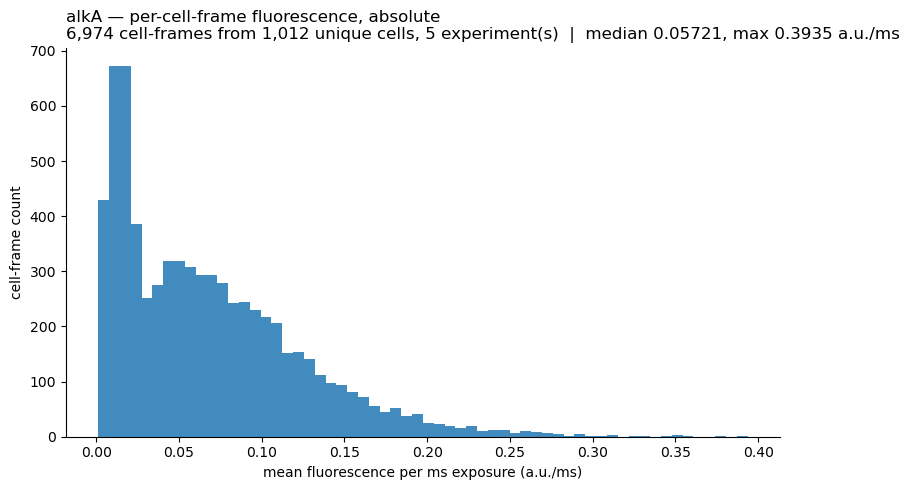

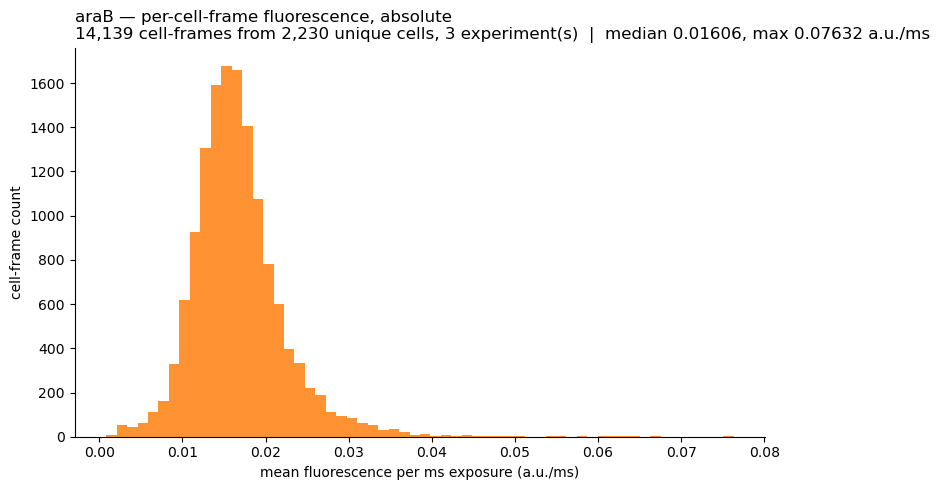

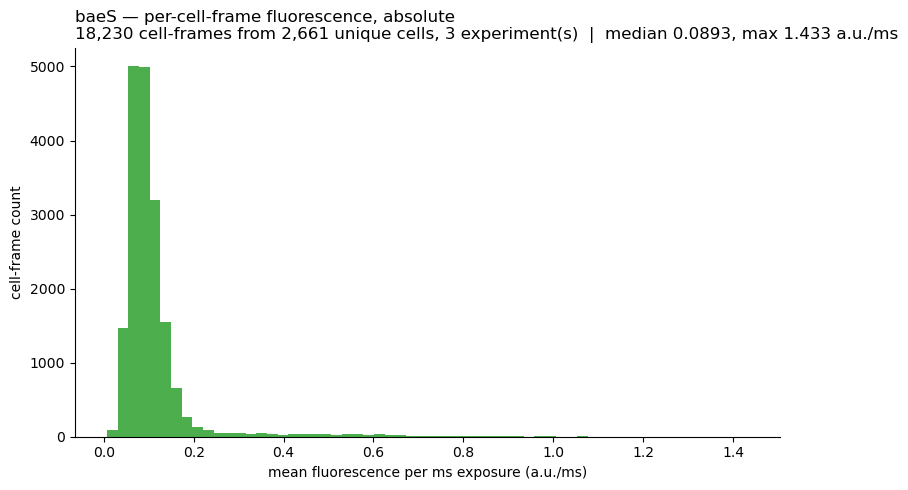

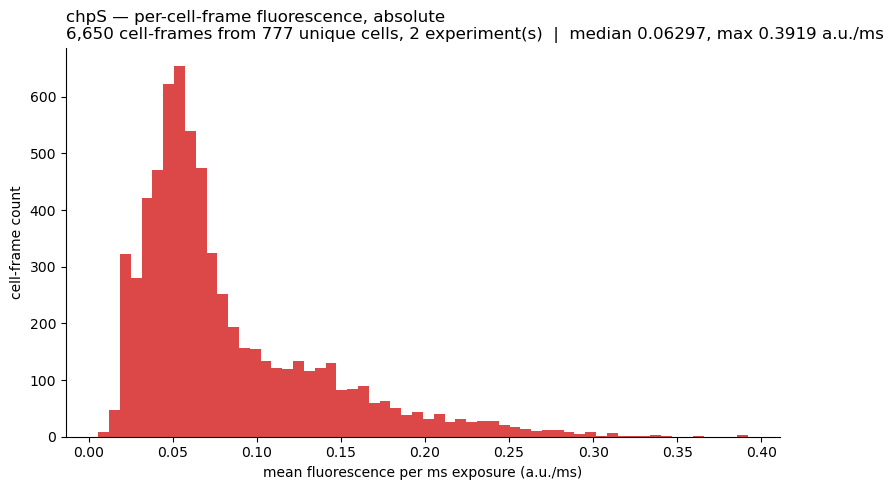

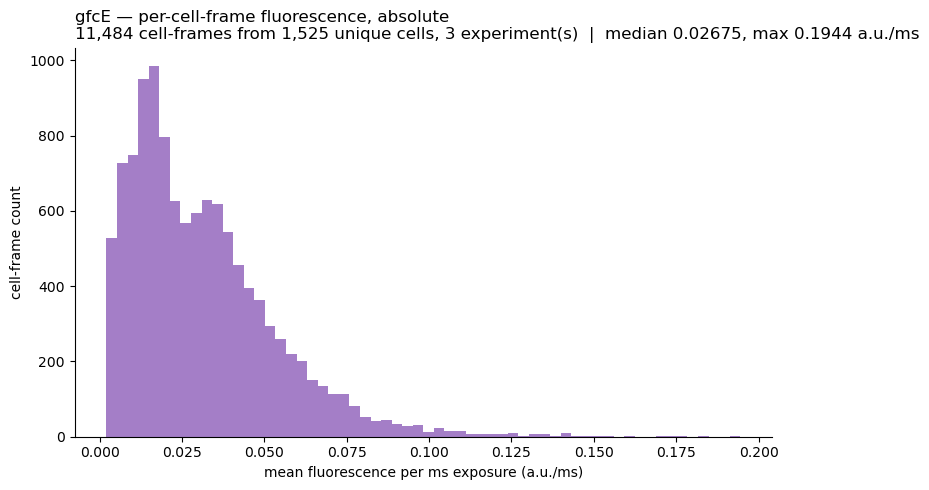

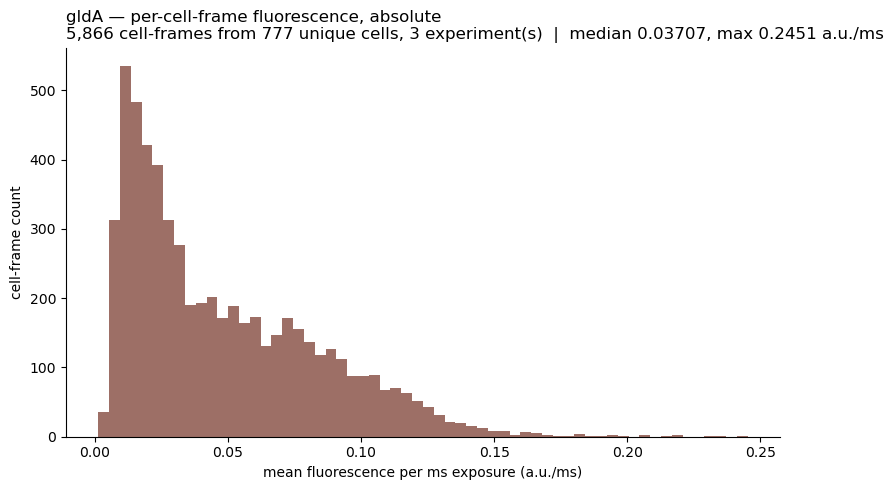

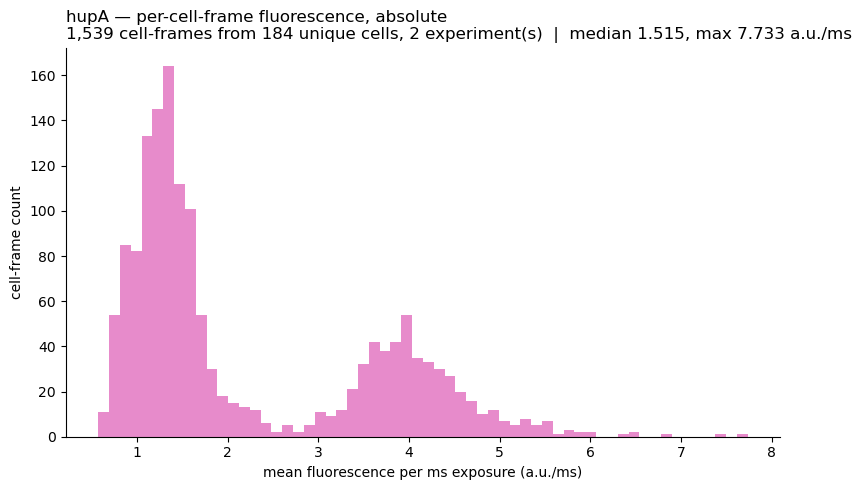

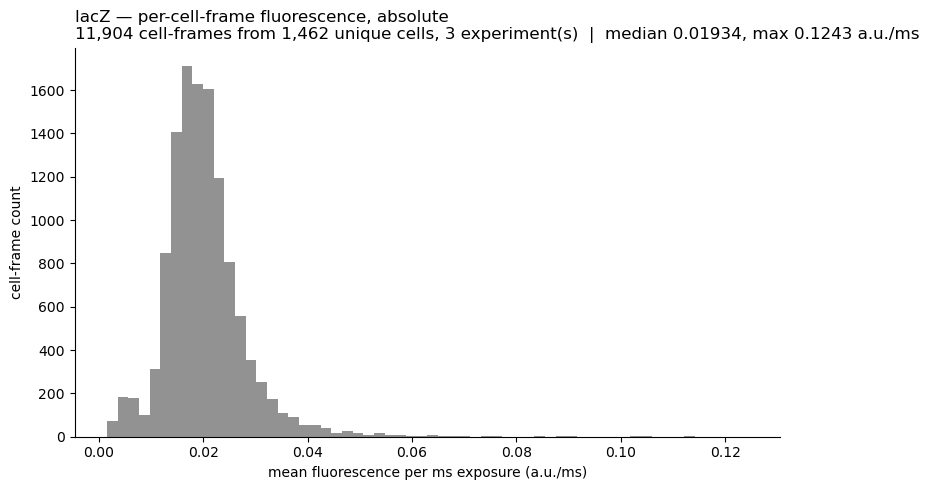

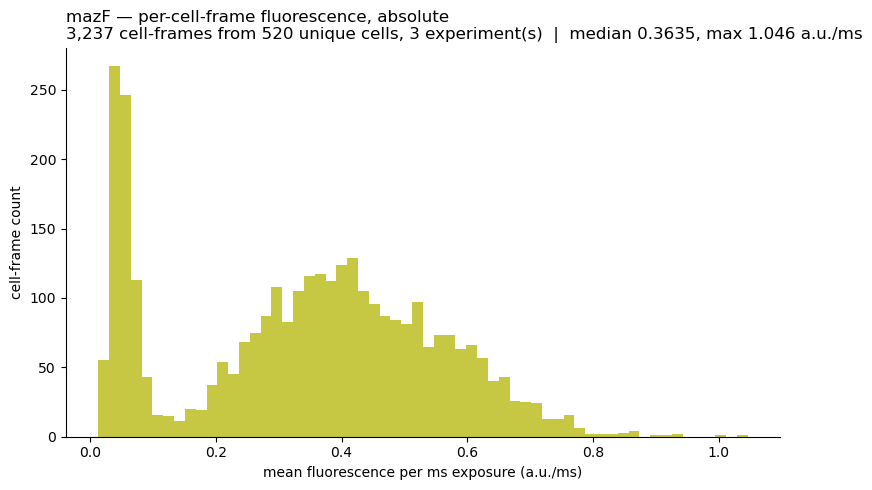

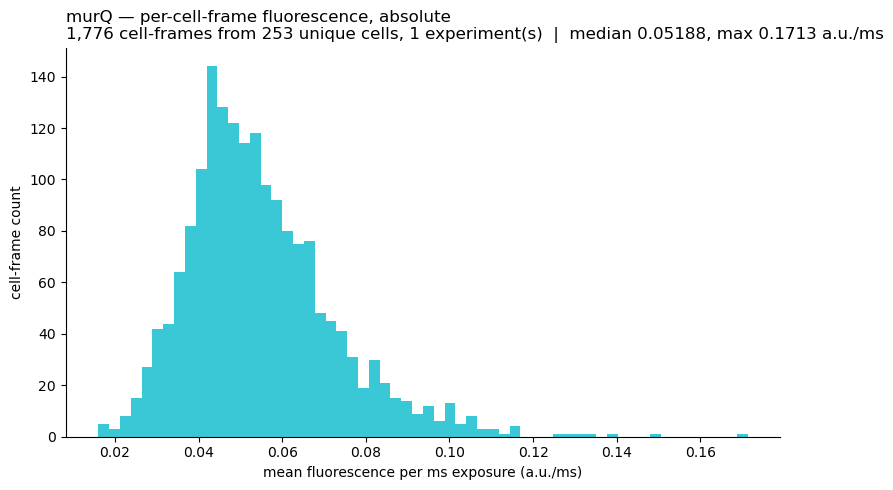

In [ ]:
# Set 1 -- absolute a.u./ms, no rescaling. Kept for reference: this is the brightness each gene
# actually sits at, and it is what Figure 6's bars average. Nothing is saved (save=False).
for _gene in sorted(hist_df['gene'].dropna().unique()):
    plot_fluor_histogram(hist_df, _gene, normalize='none', save=False)

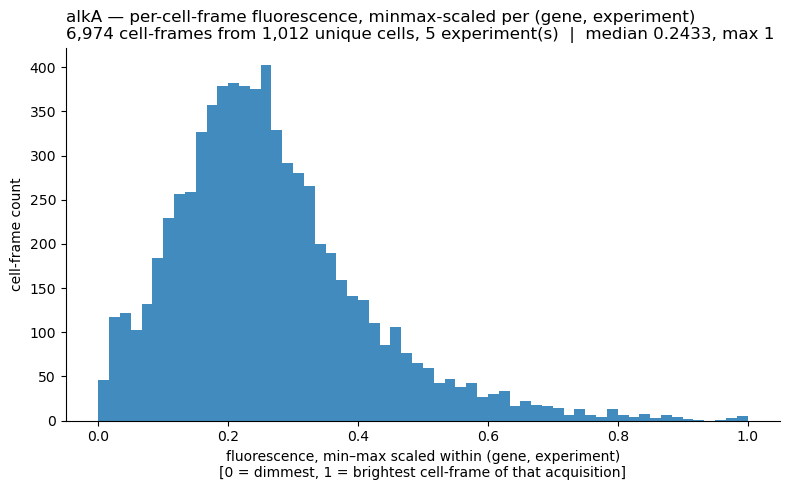

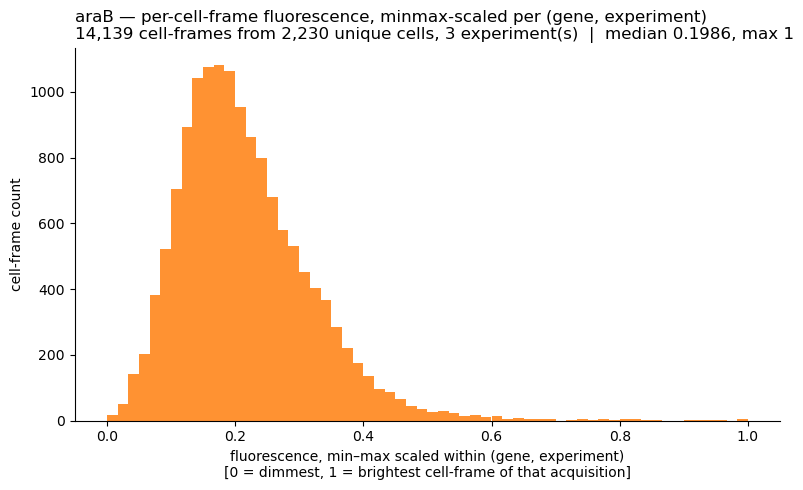

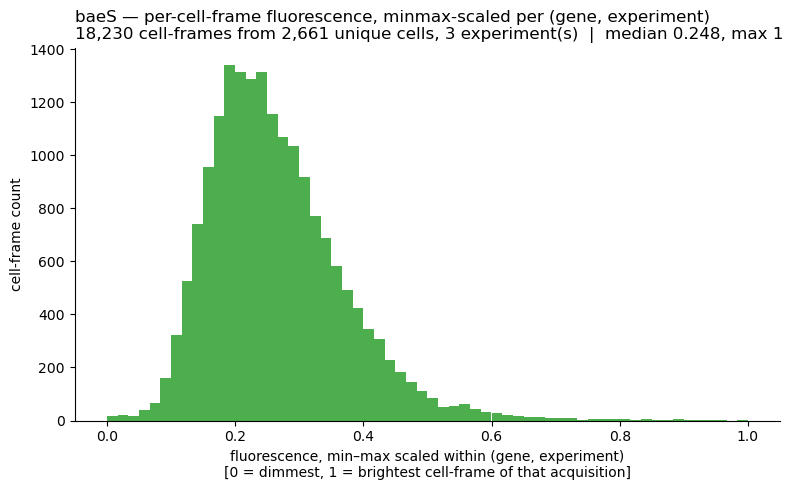

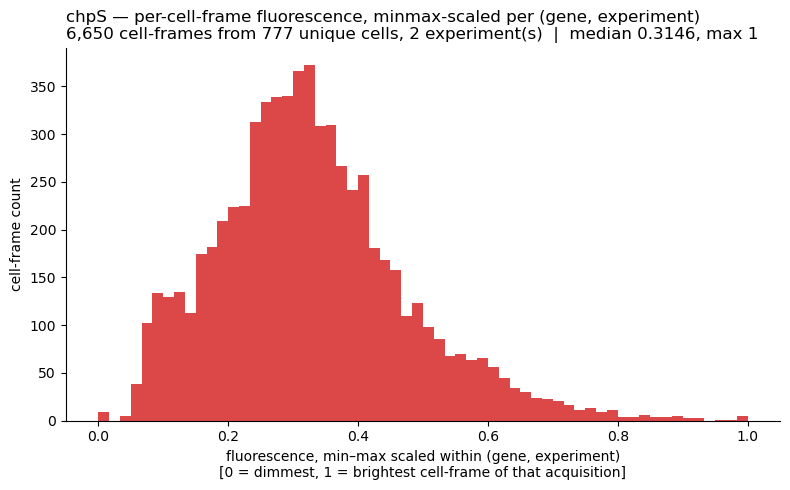

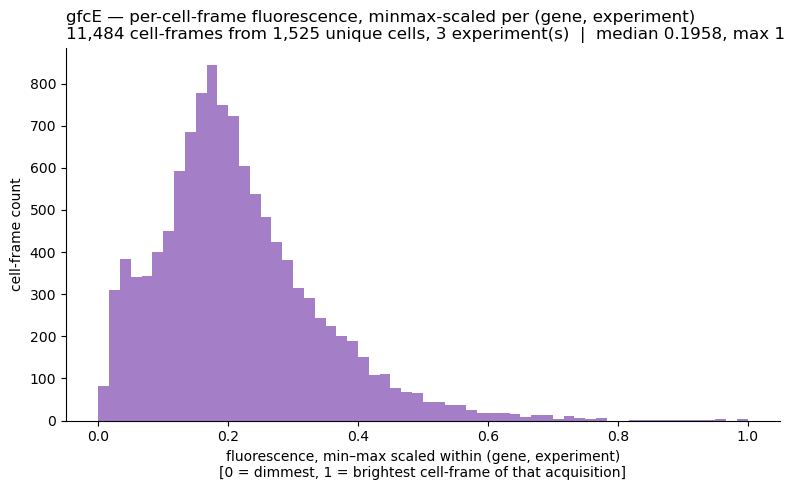

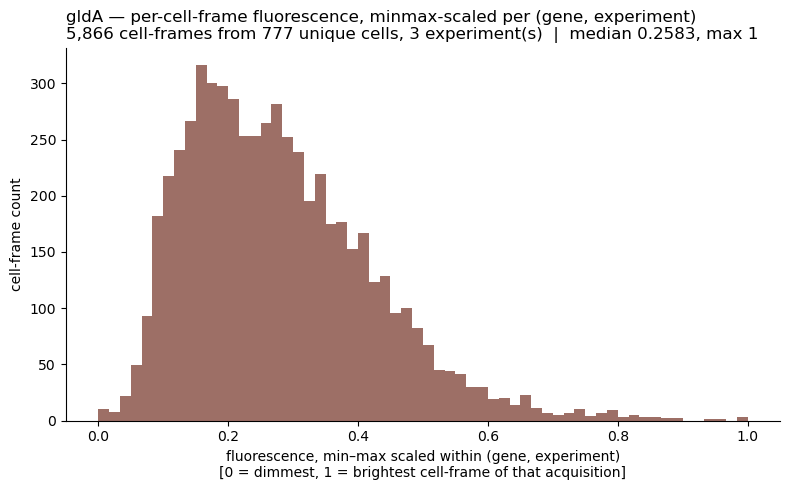

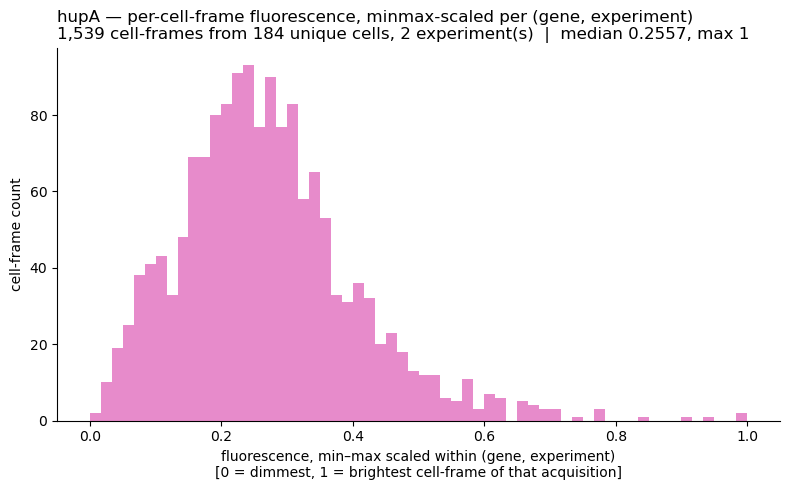

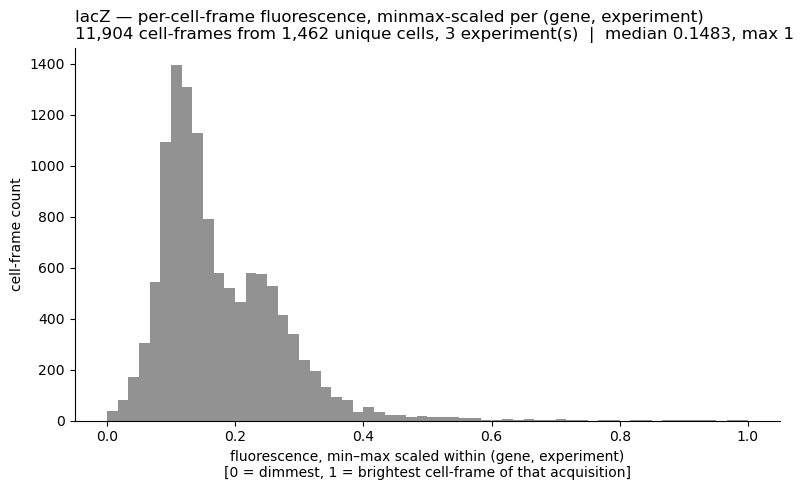

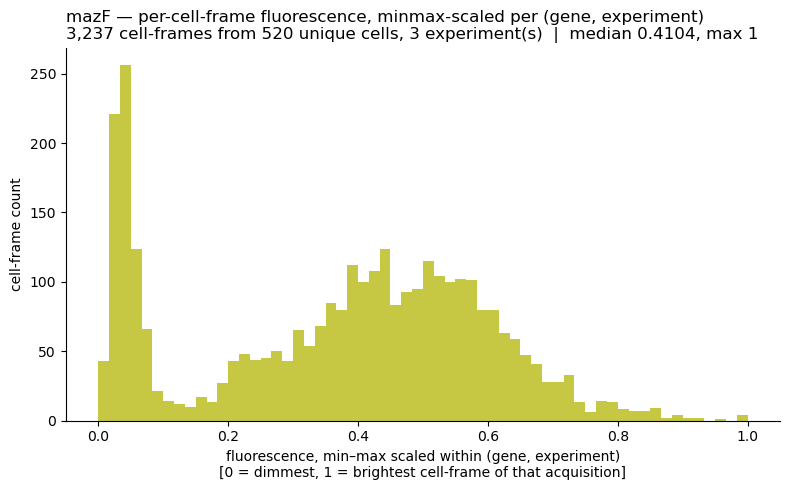

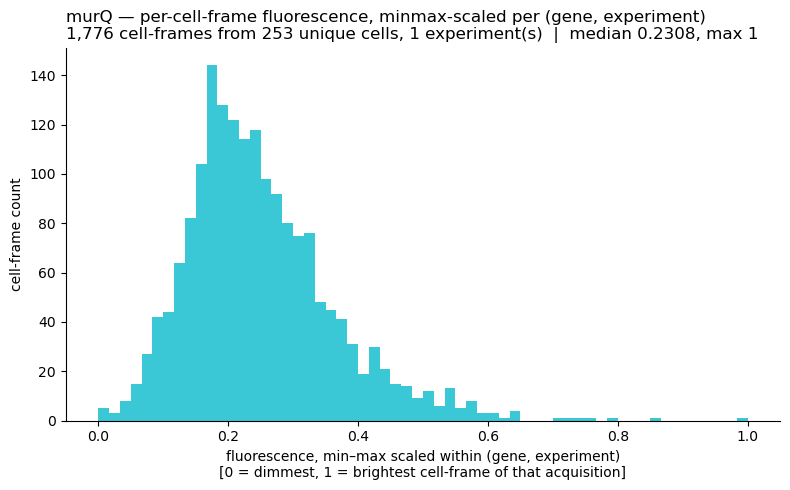

In [ ]:
# Set 2 -- min-max scaled within each (gene, experiment), so every cell-frame is expressed
# against its own acquisition and a gene's experiments can be pooled without the offset between
# them masquerading as a bright subpopulation. Same frame as set 1, so the two are directly
# comparable. Nothing is saved (save=False).
for _gene in sorted(hist_df['gene'].dropna().unique()):
    plot_fluor_histogram(hist_df, _gene, normalize='minmax', save=False)

---

## 11 — Export: two CSVs for the successor notebook

This notebook is being closed off. Everything above re-derives itself from
`all_data_082026.csv` and `track_pairs_082026.csv` on every run, and writes nothing back except
`bursts_082026.csv` — so a successor notebook would have to repeat all of it, including one step
it cannot repeat at all. This section writes the derived state out once.

**Two files, both covering all 23 experiments.** The three failed runs are *tagged*
(`is_failed_experiment`), not dropped: `df[~df.is_failed_experiment]` reproduces this notebook's
20-experiment scope exactly, and the tables are still usable for anything that wants the full set.

| file | one row is |
|---|---|
| `data/all_data_annotated_082026.csv` | one cell at one frame |
| `data/track_pairs_annotated_082026.csv` | one cell pair (`within_track` or `division`) |

### What is new relative to the source CSVs

**`fluor_filtered` — the reason this has to run here.** Per-cell mean fluorescence re-measured on
*median-filtered* (`size=3`) images by `compute_filtered_fluor`. It reads the raw subtracted fluor
TIFFs under `/Volumes/mcovert` and the 293 trackastra `ctc_masks`, so it only runs on a machine
with the drive mounted — roughly 6 minutes, cached to `data/fluor_filtered_median3_082026.csv`.
The pair table on disk was built with `--fluor-method none`, so nothing downstream has ever seen
this column. Note it is **not** on the raw absolute scale: median filtering dims cells a few
percent. Compare `fluor_filtered` against `fluor_filtered`, never against `intensity_mean_fluor`.

**Per-kymograph min–max.** Section 10's min–max is grouped by *(gene, experiment)* and exists only
inside a plotting function. Here the group is one kymograph — `(experiment_name, gene, FOV,
trench_id)`, 292 of them — and the scale is written out as columns, for each of four
fluorescence units:

```
intensity_mean_fluor   raw a.u.
fluor_per_ms           raw / fluor_exposure_ms          <- comparable across exposures
fluor_filtered         median-filtered, a.u.
fluor_filtered_per_ms  filtered / fluor_exposure_ms
```

each with `_kymo_min`, `_kymo_max` and `_kymo_minmax = (x - min) / (max - min)`.

**The scale comes from non-degenerate masks only.** On a 1-pixel mask `intensity_mean_fluor` is a
single raw pixel with no averaging, and one such mask can set an entire kymograph's maximum —
a much bigger risk per kymograph than per experiment. Section 9's area floor (5 % of the
experiment's own median area) therefore excludes those rows from every min/max, but **keeps them
in the file**, flagged `is_degenerate_mask`. They still carry a normalised value, computed against
the clean scale, so a degenerate row can land outside [0, 1]. Filter on the flag, don't clip.
A group with no spread normalises to NaN rather than dividing by zero, matching
`_rescale_within_group` above.

### One trap the pair table carries, and how these files remove it

On a `division` row, `track_id` is the **daughter** while `frame_from` is the **parent's** last
frame, and `time_frame` is NaN. A five-column merge back onto the cell table therefore silently
drops all 11,576 division rows. The export ships explicit `from_track_id` / `to_track_id` columns
so both endpoints join unambiguously:

```
from = (experiment_name, FOV, trench_id, from_track_id, frame_from)
to   = (experiment_name, FOV, trench_id, to_track_id,   frame_to)
```

The same mistake is live in `mmtrack.track_displacement.apply_filtered_fluor`, which keys both
endpoints on `track_id`: running `07_track_displacement_analysis.py --fluor-method median` today
returns `fluor_from = NaN` and `delta_fluor = NaN` for **every** division pair. Measured, not
hypothetical. It is not patched here because that would change stage 7's output — worth a
separate fix.

This section is self-contained: it needs only the imports cell and `CONFIG`, and it deliberately
does not read `all_data`, `area_data`, `hist_df` or `fluor_df`, all of which are already scoped to
the 20 kept experiments.

In [ ]:
# Export config. Every global in this section is named so it cannot rebind anything above --
# re-running an earlier cell after this one still behaves identically.
EXPORT_CELLS_CSV = f'{REPO_ROOT}/data/all_data_annotated_082026.csv'
EXPORT_PAIRS_CSV = f'{REPO_ROOT}/data/track_pairs_annotated_082026.csv'

# denoise_fluor's own default: removes speckle without moving cell edges.
EXPORT_FILTER_METHOD, EXPORT_FILTER_SIZE = 'median', 3
EXPORT_FILT_CACHE = (f'{REPO_ROOT}/data/fluor_filtered_'
                     f'{EXPORT_FILTER_METHOD}{EXPORT_FILTER_SIZE}_082026.csv')

# compute_filtered_fluor's time_dict default is RELATIVE and Jupyter's cwd is this notebook's
# own directory, so the default raises FileNotFoundError. Pass an absolute path.
EXPORT_TIME_DICT = f'{REPO_ROOT}/data/time_dict_082026.json'

# One kymograph. Same partition as KYMO_KEY -- gene is constant within a trench and never null --
# but carrying `gene` makes the group key self-describing in the exported file.
KYMO_GROUP      = ['experiment_name', 'gene', 'FOV', 'trench_id']
EXPORT_CELL_KEY = ['experiment_name', 'FOV', 'trench_id', 'track_id', 'time_frame']

# The four fluorescence units the export carries a min/max for. Full column names rather than
# short aliases, so downstream can loop `for base in FLUOR_BASES` and build f'{base}_kymo_min'.
FLUOR_BASES = ['intensity_mean_fluor',   # raw a.u.
               'fluor_per_ms',           # raw / fluor_exposure_ms
               'fluor_filtered',         # re-measured on median-filtered images, a.u.
               'fluor_filtered_per_ms']  # filtered / fluor_exposure_ms

# `predicted_lineage` holds '1', '1.1', '3.1.1' -- pandas infers int64 or float64 on any subset
# that happens to have no dots, so it must be forced to str on read as well as on write.
EXPORT_DTYPES = {'experiment_name': str, 'FOV': str, 'trench_id': str,
                 'gene': str, 'predicted_lineage': str}

print(f'cells -> {os.path.basename(EXPORT_CELLS_CSV)}')
print(f'pairs -> {os.path.basename(EXPORT_PAIRS_CSV)}')
print(f'filter : {EXPORT_FILTER_METHOD}, size={EXPORT_FILTER_SIZE}  '
      f'(cache {os.path.basename(EXPORT_FILT_CACHE)})')
print(f'min/max: per ' + ' x '.join(KYMO_GROUP))
print(f'bases  : {", ".join(FLUOR_BASES)}')

In [ ]:
def load_full_cells(csv_path=CSV_PATH):
    """The whole cell table: all 23 experiments, every column except `coords`.

    Deliberately NOT load_summary_data -- that one drops the failed runs and narrows to
    SUMMARY_COLS. The export is the archive, so it keeps the failed runs (tagged, not dropped)
    and keeps the columns sections 5 and 9 currently have to re-read the 280 MB CSV to get:
    centroid_x, axis_minor_length, the phase intensities and intensity_max/min_fluor.

    `coords` is the only exclusion -- it is the bulk of the file and nothing reads it.
    """
    df = pd.read_csv(csv_path, usecols=lambda c: c != 'coords', dtype=EXPORT_DTYPES)
    df['FOV'] = df['FOV'].str.zfill(3)

    # Same asserts as load_summary_data: fluor_per_ms is only a per-experiment constant rescale
    # if exposure is single-valued, and every cross-gene comparison rests on that.
    per_exp = df.groupby('experiment_name')[EXPOSURE_COL].nunique()
    assert (per_exp == 1).all(), \
        f'{EXPOSURE_COL} varies within: {sorted(per_exp[per_exp > 1].index)}'
    assert df[EXPOSURE_COL].notna().all() and (df[EXPOSURE_COL] > 0).all(), \
        f'{EXPOSURE_COL} has a null or non-positive value'

    # A null in the group key would become its own min/max group under dropna=False, or vanish
    # entirely under dropna=True. Neither belongs in an archive, so refuse to build one.
    assert df[KYMO_GROUP].notna().all().all(), 'a null in the kymograph group key'
    # A null area compares False against the floor and so reads as "not degenerate" -- the
    # silent direction. Catch it here rather than mislabelling the mask.
    assert df['area'].notna().all(), 'a null area would read as "not degenerate"'
    assert not df.duplicated(EXPORT_CELL_KEY).any(), 'the cell key is not unique'
    assert df['FOV'].str.len().eq(3).all(), 'FOV must stay zero-padded to 3 chars'
    return df


out_cells = load_full_cells()
out_cells['is_failed_experiment'] = out_cells['experiment_name'].isin(FAILED_EXPERIMENTS)

print(f'{len(out_cells):,} cell-frames | {out_cells.experiment_name.nunique()} experiments | '
      f'{out_cells.gene.nunique()} genes | '
      f'{len(out_cells[KYMO_GROUP].drop_duplicates()):,} kymographs | '
      f'{len(out_cells[EXPORT_CELL_KEY[:-1]].drop_duplicates()):,} unique cells')
print(f'failed runs: {int(out_cells.is_failed_experiment.sum()):,} rows from '
      f'{out_cells.loc[out_cells.is_failed_experiment, "experiment_name"].nunique()} experiments '
      f'-- tagged is_failed_experiment, NOT dropped')
print(f'columns carried: {out_cells.shape[1]} (source minus `coords`, plus is_failed_experiment)')

In [ ]:
# Per-cell mean fluorescence, re-measured on median-filtered images. This is the one step that
# needs the raw data -- it reads the subtracted fluor TIFFs under /Volumes/mcovert and the 293
# trackastra ctc_masks -- which is exactly why the result is being written to a CSV instead of
# left for the successor notebook to recompute. ~1.2 s per trench, ~6 min for all 293.
from mmtrack.track_displacement import compute_filtered_fluor

if os.path.exists(EXPORT_FILT_CACHE):
    # The dtype= is load-bearing. Without it '003' reads back as the integer 3 and the merge
    # below matches nothing at all, with no error -- the trap documented in load_cell_data.
    out_filt = pd.read_csv(EXPORT_FILT_CACHE,
                           dtype={'experiment_name': str, 'FOV': str, 'trench_id': str})
    out_filt['FOV'] = out_filt['FOV'].str.zfill(3)
    print(f'read cache {os.path.basename(EXPORT_FILT_CACHE)} ({len(out_filt):,} rows)')
else:
    print(f'computing on {EXPORT_FILTER_METHOD}-filtered images -- a few minutes ...')
    out_filt = compute_filtered_fluor(
        sorted(out_cells['experiment_name'].unique()),
        time_dict_path=EXPORT_TIME_DICT,
        method=EXPORT_FILTER_METHOD, size=EXPORT_FILTER_SIZE)
    out_filt.to_csv(EXPORT_FILT_CACHE, index=False)
    print(f'wrote cache {os.path.basename(EXPORT_FILT_CACHE)} ({len(out_filt):,} rows)')

assert not out_filt.duplicated(EXPORT_CELL_KEY).any(), 'duplicate key in the filtered table'
_n = len(out_cells)
out_cells = out_cells.merge(out_filt, on=EXPORT_CELL_KEY, how='left', validate='one_to_one')
assert len(out_cells) == _n, 'the filtered-fluor merge changed the row count'

# A dtype mismatch on any key produces an all-NaN column and no error, so coverage is checked
# rather than assumed. Expect 1.0000: the only trench whose fluor TIFF is missing
# (DUMM_giTG064_Glucose_022625 / 001 / 114) is also the only mask with no rows in the cell table.
_cov = out_cells.groupby('experiment_name')['fluor_filtered'].apply(lambda s: s.notna().mean())
_gaps = out_cells.loc[out_cells['fluor_filtered'].isna(), KYMO_GROUP].drop_duplicates()
print(f'\ncoverage {out_cells.fluor_filtered.notna().mean():.4f} overall | '
      f'worst experiment {_cov.min():.4f} ({_cov.idxmin()})')
print(f'filtered rows matching no cell: '
      f'{len(out_filt) - int(out_cells.fluor_filtered.notna().sum()):,} '
      f'(the extra mask trench, expected)')
if len(_gaps):
    print(f'{len(_gaps)} kymograph(s) with no filtered value:\n{_gaps.to_string(index=False)}')
assert out_cells['fluor_filtered'].notna().all(), 'a cell-frame has no filtered fluorescence'

# The nastiest failure mode here is not a missing value, it is a WRONG one: if a trench's
# time_dict `start` offset were off, compute_filtered_fluor would read a SHIFTED window of the
# TIFF and return a full set of plausible numbers at 100% coverage.
#
# An absolute correlation floor does NOT test for that -- it tests brightness. On the two dim,
# noise-dominated acquisitions here (both already-known failed runs) the correctly aligned
# correlation is only 0.70 and 0.86, because median filtering legitimately removes most of what
# little signal they have. What actually tests alignment is whether lag 0 beats a deliberate
# one-frame shift, which is self-calibrating per experiment: measured, lag 0 wins for all 23,
# and by the LARGEST margin (0.55, 0.70) on exactly those two dim runs.
_al = out_cells.sort_values(EXPORT_CELL_KEY[:-1] + ['time_frame'])
_shifted = _al.groupby(EXPORT_CELL_KEY[:-1], sort=False)['fluor_filtered']
_al = _al.assign(_lag_p1=_shifted.shift(1), _lag_m1=_shifted.shift(-1))
_lag = _al.groupby('experiment_name').apply(
    lambda g: pd.Series({'lag0':    g[RAW_FLUOR_COL].corr(g['fluor_filtered']),
                         'shift+1': g[RAW_FLUOR_COL].corr(g['_lag_p1']),
                         'shift-1': g[RAW_FLUOR_COL].corr(g['_lag_m1'])}),
    include_groups=False)
_lag['margin'] = _lag['lag0'] - _lag[['shift+1', 'shift-1']].max(axis=1)
_bad = _lag[_lag['margin'] <= 0]
assert _bad.empty, f'a one-frame shift fits better -- start offset misaligned:\n{_bad}'
print(f'\nalignment: lag 0 beats a +/-1 frame shift for all {len(_lag)} experiments '
      f'(smallest margin {_lag.margin.min():.4f}, {_lag.margin.idxmin()})')
print(f'corr(filtered, raw): median {_lag.lag0.median():.5f}, '
      f'min {_lag.lag0.min():.5f} ({_lag.lag0.idxmin()})')

# Median filtering dims cells, so the filtered column is NOT on the raw absolute scale -- and how
# much it dims depends on how noise-dominated the run is. On the dimmest acquisitions it removes
# more than half the signal, which is worth seeing here rather than discovering in a figure.
_ratio = (out_cells.groupby('experiment_name')
          .apply(lambda g: g['fluor_filtered'].median() / g[RAW_FLUOR_COL].median(),
                 include_groups=False)
          .sort_values())
print(f'\nfiltered/raw median ratio spans {_ratio.min():.3f} .. {_ratio.max():.3f}; '
      f'most affected:')
print('  ' + _ratio.head(3).round(3).to_string().replace('\n', '\n  '))
print(f'compare fluor_filtered only against fluor_filtered, never against {RAW_FLUOR_COL}.')

In [ ]:
# ---- derived fluorescence units --------------------------------------------------------------
# Exposure is single-valued per experiment (asserted at load), so this is a per-experiment
# constant rescale -- the same one section 5 applies, recomputed over all 23 experiments rather
# than reusing EXPOSURE_BY_EXP, which only knows the 20 kept ones and would give the three
# failed runs a NaN exposure and therefore an all-NaN fluor_per_ms.
out_cells['fluor_per_ms'] = out_cells[RAW_FLUOR_COL] / out_cells[EXPOSURE_COL]
out_cells['fluor_filtered_per_ms'] = out_cells['fluor_filtered'] / out_cells[EXPOSURE_COL]

# ---- degenerate-mask flag ---------------------------------------------------------------------
# Section 9's rule, restated so this section stands alone, with the median recomputed over all 23
# experiments: cell 75's EXP_MEDIAN_AREA is built from the 20-experiment all_data, so mapping it
# here would yield NaN for the failed runs and quietly mark none of their masks degenerate.
# The floor is relative because one run sits at ~1/3 the linear pixel scale of every other.
EXPORT_MIN_AREA_FRAC = 0.05          # 5% of the experiment's OWN median cell area
EXPORT_EXP_MEDIAN_AREA = out_cells.groupby('experiment_name')['area'].median()
_floor = EXPORT_MIN_AREA_FRAC * out_cells['experiment_name'].map(EXPORT_EXP_MEDIAN_AREA)
assert _floor.notna().all(), 'an experiment is missing from EXPORT_EXP_MEDIAN_AREA'
out_cells['is_degenerate_mask'] = out_cells['area'] < _floor

# ---- per-kymograph min / max / min-max ---------------------------------------------------------
# The scale is taken from the NON-degenerate rows only: on a 1-pixel mask intensity_mean_fluor is
# a single raw pixel with no averaging, and one such mask can set a whole kymograph's maximum --
# a far bigger risk per kymograph than per experiment, because the groups are ~40x smaller.
#
# Degenerate rows are kept and still get a normalised value against that clean scale, so they can
# land outside [0, 1]. That is deliberate: is_degenerate_mask lets a reader filter them, whereas
# clipping would hide them. A group with no spread normalises to NaN rather than dividing by
# zero, matching _rescale_within_group in section 10.
#
# dropna=False so a null group key could never silently swallow a whole group. There are none --
# it is asserted at load -- but the archive should not depend on that staying true.
_gkeys = [out_cells[c] for c in KYMO_GROUP]
for _base in FLUOR_BASES:
    _clean = out_cells[_base].where(~out_cells['is_degenerate_mask'])
    _g = _clean.groupby(_gkeys, dropna=False, sort=False)
    _lo, _hi = _g.transform('min'), _g.transform('max')
    _span = (_hi - _lo).where(lambda s: s > 0)        # 0 or NaN -> NaN, never a divide-by-zero
    out_cells[f'{_base}_kymo_min'] = _lo
    out_cells[f'{_base}_kymo_max'] = _hi
    out_cells[f'{_base}_kymo_minmax'] = (out_cells[_base] - _lo) / _span

_ndeg = int(out_cells.is_degenerate_mask.sum())
print(f'{len(out_cells[KYMO_GROUP].drop_duplicates()):,} kymograph groups | '
      f'smallest {out_cells.groupby(KYMO_GROUP).size().min()} rows')
print(f'degenerate masks: {_ndeg:,} of {len(out_cells):,} '
      f'({100 * _ndeg / len(out_cells):.2f}%) -- excluded from every min/max, kept in the file')
for _base in FLUOR_BASES:
    _mm = out_cells[f'{_base}_kymo_minmax']
    _out01 = (_mm < 0) | (_mm > 1)
    print(f'  {_base:22s} no-spread NaN {int(_mm.isna().sum()):>4,} | '
          f'outside [0,1] {int(_out01.sum()):>4,} '
          f'(all degenerate: {bool(out_cells.loc[_out01, "is_degenerate_mask"].all())})')

# ---- cross-check against the frames this notebook actually used --------------------------------
# Nothing else proves the export reproduces the notebook's own scope, and both frames are still
# in memory, so check it. Skipped silently if sections 1 / 9 have not been run in this kernel.
if 'all_data' in globals():
    assert int((~out_cells.is_failed_experiment).sum()) == len(all_data), \
        'dropping the failed runs does not reproduce all_data'
    print(f'\nreproduces all_data exactly: {len(all_data):,} rows')
if 'area_data' in globals():
    _rec = int(((~out_cells.is_failed_experiment) & (~out_cells.is_degenerate_mask)).sum())
    assert _rec == len(area_data), f'{_rec:,} != len(area_data) = {len(area_data):,}'
    print(f'reproduces area_data exactly: {len(area_data):,} rows')

out_cells = (out_cells.sort_values(KYMO_GROUP + ['time_frame', 'track_id'])
             .reset_index(drop=True))
assert not out_cells.duplicated(EXPORT_CELL_KEY).any(), 'duplicate cell key before write'
out_cells.to_csv(EXPORT_CELLS_CSV, index=False)
print(f'\nwrote {EXPORT_CELLS_CSV}')
print(f'  {len(out_cells):,} rows x {out_cells.shape[1]} cols, '
      f'{os.path.getsize(EXPORT_CELLS_CSV) / 1e6:.1f} MB')

In [ ]:
# ---- the pair table, annotated -----------------------------------------------------------------
# Read with no failed-run exclusion, and ADD columns rather than overwrite. Section 3 divides
# fluor_from / fluor_to / delta_fluor by exposure in place, which makes that frame non-idempotent;
# here the raw a.u. columns stay byte-for-byte as stage 7 wrote them and every derived unit gets
# its own name.
out_pairs = pd.read_csv(PAIRS_CSV, dtype=EXPORT_DTYPES)
out_pairs['FOV'] = out_pairs['FOV'].str.zfill(3)
out_pairs['is_failed_experiment'] = out_pairs['experiment_name'].isin(FAILED_EXPERIMENTS)

# The endpoint keys, made explicit. On a `division` row track_id is the DAUGHTER while frame_from
# is the PARENT's last frame, and time_frame is NaN -- so a five-column merge back onto the cell
# table silently drops all of them. Shipping both ids removes the trap from the successor
# notebook. (This is the bug live in apply_filtered_fluor; see the markdown above.)
_from_tid = np.where(out_pairs['is_division'].astype(bool),
                     out_pairs['parent_track_id'], out_pairs['track_id'])
assert not np.isnan(_from_tid).any(), 'a division row has no parent_track_id'
# Cast explicitly: parent_track_id is float64, and a float level in the MultiIndex below would
# reindex to NaN on some pandas versions without raising.
out_pairs['from_track_id'] = _from_tid.astype('int64')
out_pairs['to_track_id'] = out_pairs['track_id'].astype('int64')


def endpoint_lookup(col, tid_col, frame_col):
    """One endpoint's value of `col`, pulled from out_cells by (trench, track, frame)."""
    lut = out_cells.set_index(EXPORT_CELL_KEY)[col]
    idx = pd.MultiIndex.from_arrays([
        out_pairs['experiment_name'], out_pairs['FOV'], out_pairs['trench_id'],
        out_pairs[tid_col], out_pairs[frame_col],
    ])
    return lut.reindex(idx).to_numpy()


# Proof the keying is right, before anything is derived from it: the raw column looked up this
# way must reproduce what stage 7 already wrote, on BOTH pair types. This is the only thing
# standing between a wrong join and a plausible-looking CSV.
for _lbl, _tid, _fr, _want in (('from', 'from_track_id', 'frame_from', 'fluor_from'),
                               ('to', 'to_track_id', 'frame_to', 'fluor_to')):
    _got = endpoint_lookup(RAW_FLUOR_COL, _tid, _fr)
    assert np.isfinite(_got).all(), \
        f'{_lbl}-endpoint lookup missed {int((~np.isfinite(_got)).sum()):,} rows'
    _dev = float(np.nanmax(np.abs(_got - out_pairs[_want])))
    assert _dev < 1e-9, f'{_lbl}-endpoint disagrees with the pair table by {_dev:g}'
    print(f'{_lbl:>4}-endpoint verified against stage 7: '
          f'{len(out_pairs):,} rows, max deviation {_dev:g}')

for _base in FLUOR_BASES:
    out_pairs[f'{_base}_from'] = endpoint_lookup(_base, 'from_track_id', 'frame_from')
    out_pairs[f'{_base}_to'] = endpoint_lookup(_base, 'to_track_id', 'frame_to')
    out_pairs[f'delta_{_base}'] = out_pairs[f'{_base}_to'] - out_pairs[f'{_base}_from']
    assert out_pairs[f'delta_{_base}'].notna().all(), f'delta_{_base} has nulls'

out_pairs['area_from'] = endpoint_lookup('area', 'from_track_id', 'frame_from')
out_pairs['area_to'] = endpoint_lookup('area', 'to_track_id', 'frame_to')
out_pairs['fluor_exposure_ms'] = endpoint_lookup(EXPOSURE_COL, 'to_track_id', 'frame_to')
for _lbl, _tid, _fr in (('from', 'from_track_id', 'frame_from'),
                        ('to', 'to_track_id', 'frame_to')):
    _flag = endpoint_lookup('is_degenerate_mask', _tid, _fr)
    assert pd.notna(_flag).all(), f'is_degenerate_mask_{_lbl} has nulls'
    out_pairs[f'is_degenerate_mask_{_lbl}'] = _flag.astype(bool)

# The kymograph scale, so a Delta can be normalised straight out of this file without re-reading
# the cell table. Merged on the three-column trench key rather than KYMO_GROUP: `gene` is carried
# independently in both files, and joining on it would turn any disagreement into a silent NaN
# instead of the loud assert below.
_TRENCH_KEY = ['experiment_name', 'FOV', 'trench_id']
_scale_cols = [f'{b}_kymo_{s}' for b in FLUOR_BASES for s in ('min', 'max')]
_scale = out_cells[_TRENCH_KEY + _scale_cols].drop_duplicates(_TRENCH_KEY)
assert not (set(_scale_cols) & set(out_pairs.columns)), 'a scale column already exists on pairs'
_n = len(out_pairs)
out_pairs = out_pairs.merge(_scale, on=_TRENCH_KEY, how='left', validate='many_to_one')
assert len(out_pairs) == _n, 'the scale merge changed the row count'
assert out_pairs[_scale_cols].notna().all().all(), 'a pair belongs to no kymograph in the cells'

# The two files must agree on which gene a trench belongs to, or the successor notebook can group
# the same trench two ways.
_gene_cells = out_cells.drop_duplicates(_TRENCH_KEY).set_index(_TRENCH_KEY)['gene']
_gene_pairs = out_pairs.drop_duplicates(_TRENCH_KEY).set_index(_TRENCH_KEY)['gene']
assert _gene_cells.reindex(_gene_pairs.index).equals(_gene_pairs), \
    'the cell and pair tables disagree about a trench\'s gene'
print(f'gene assignment agrees across both files for all {len(_gene_pairs):,} trenches')

out_pairs.to_csv(EXPORT_PAIRS_CSV, index=False)
print(f'\nwrote {EXPORT_PAIRS_CSV}')
print(f'  {len(out_pairs):,} rows x {out_pairs.shape[1]} cols, '
      f'{os.path.getsize(EXPORT_PAIRS_CSV) / 1e6:.1f} MB')
print('  ' + ' | '.join(f'{k} {v:,}' for k, v in out_pairs.pair_type.value_counts().items()))

In [ ]:
# ---- round-trip validation + the recipe for the successor notebook ------------------------------
# Read both files back the way the next notebook will, and check they survive the trip. A CSV
# that is correct in memory and wrong on disk is the whole risk being guarded against here.
_c = pd.read_csv(EXPORT_CELLS_CSV, dtype=EXPORT_DTYPES)
_p = pd.read_csv(EXPORT_PAIRS_CSV, dtype=EXPORT_DTYPES)
assert _c.shape == out_cells.shape, f'{_c.shape} != {out_cells.shape}'
assert _p.shape == out_pairs.shape, f'{_p.shape} != {out_pairs.shape}'
assert _c['FOV'].str.len().eq(3).all() and _p['FOV'].str.len().eq(3).all(), 'FOV lost its padding'

print(f'{os.path.basename(EXPORT_CELLS_CSV)}')
print(f'  {len(_c):,} rows x {_c.shape[1]} cols | {_c.experiment_name.nunique()} experiments | '
      f'{_c.gene.nunique()} genes | {len(_c[KYMO_GROUP].drop_duplicates()):,} kymographs | '
      f'{len(_c[EXPORT_CELL_KEY[:-1]].drop_duplicates()):,} unique cells')
print(f'{os.path.basename(EXPORT_PAIRS_CSV)}')
print(f'  {len(_p):,} rows x {_p.shape[1]} cols | {_p.experiment_name.nunique()} experiments | '
      + ' | '.join(f'{k} {v:,}' for k, v in _p.pair_type.value_counts().items()))

print('\nscoped the way this notebook scopes (is_failed_experiment == False):')
_ck, _pk = _c[~_c.is_failed_experiment], _p[~_p.is_failed_experiment]
print(f'  cells {len(_ck):,} rows | {_ck.experiment_name.nunique()} experiments | '
      f'{len(_ck[KYMO_GROUP].drop_duplicates()):,} kymographs | '
      f'{len(_ck[EXPORT_CELL_KEY[:-1]].drop_duplicates()):,} unique cells')
print(f'  pairs {len(_pk):,} rows | {int(_pk.is_jump.sum()):,} flagged as jumps')

print('\nper-kymograph min/max:')
for _base in FLUOR_BASES:
    _mm = _c[f'{_base}_kymo_minmax']
    print(f'  {_base:22s} nan {int(_mm.isna().sum()):>5,} | '
          f'outside [0,1] {int(((_mm < 0) | (_mm > 1)).sum()):>4,} | '
          f'range [{_mm.min():.3f}, {_mm.max():.3f}]')

print('\n' + '=' * 78)
print('read these back with -- the dtype= is NOT optional: without it FOV \'003\' becomes the')
print("integer 3, trench_id '1488' becomes 1488, and every join silently matches nothing.")
print('=' * 78)
print("  D = {'experiment_name': str, 'FOV': str, 'trench_id': str,")
print("       'gene': str, 'predicted_lineage': str}")
print(f"  cells = pd.read_csv('data/{os.path.basename(EXPORT_CELLS_CSV)}', dtype=D)")
print(f"  pairs = pd.read_csv('data/{os.path.basename(EXPORT_PAIRS_CSV)}', dtype=D)")
print()
print('  cells = cells[~cells.is_failed_experiment]      # this notebook\'s 20-experiment scope')
print('  clean = cells[~cells.is_degenerate_mask]        # drop 1-px masks (already excluded')
print('                                                  #   from every *_kymo_* column)')
print()
print('  # pair -> cell, per endpoint. Do NOT merge on `time_frame`: it is NaN on every')
print('  # division row, so those 11,576 pairs would vanish without a word.')
print('  FROM = [\'experiment_name\', \'FOV\', \'trench_id\', \'from_track_id\', \'frame_from\']')
print('  TO   = [\'experiment_name\', \'FOV\', \'trench_id\', \'to_track_id\',   \'frame_to\']')